# Yolo Comparison #

Figuring out the best Yolo model for efficient (edge) vehicle tracking and detection

### Model comparison table

![YOLO models table comparison](YoloResearchData/YoloModelsTableComparison.png)

### Scaling curves (mAP, size, CPU / GPU speed)

![YOLO models graph comparison](YoloResearchData/YoloModelsGraphComparison.png)

## Decision: YOLO26 #

We are opting for **YOLO26**. It has the best accuracy at every size and the fastest CPU inference of the nano models, and it is NMS-free, which makes it well suited to edge deployment.


In [2]:
%pip install -q torch torchvision ultralytics opencv-python matplotlib

import time
from pathlib import Path

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

Note: you may need to restart the kernel to use updated packages.


## Setup: model, classes, paths #

Pretrained YOLO26n with COCO classes, so no training is needed. People, bikes (bicycle + motorcycle) and vehicles (car, bus, truck) are tracked with ByteTrack.

In [3]:
import time
from pathlib import Path

import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------- Paths (local) ----------
# Project root = first folder (going up from this notebook) that contains "data/".
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_DIR    = PROJECT_ROOT / "data" / "videos"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_PATH = VIDEO_DIR / "6_11_26_morning_cam2.mp4"

# ---------- Settings ----------
MODEL_PATH = MODELS_DIR / "yolo26n.pt"   # downloaded here (~5 MB) on first run
CONF       = 0.35                        # min detection confidence
IMGSZ      = 640                         # inference size; lower (480/416) = faster on CPU
TRACKER    = "bytetrack.yaml"            # lighter than the default botsort on CPU
DEVICE     = 0 if torch.cuda.is_available() else "cpu"

# COCO class id -> name
TARGET_CLASSES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
}

# ---------- Model ----------
model = YOLO(str(MODEL_PATH) if MODEL_PATH.exists() else MODEL_PATH.name)
if not MODEL_PATH.exists():                      # first run: move the downloaded weights into models/
    Path(MODEL_PATH.name).replace(MODEL_PATH)
for cid, name in TARGET_CLASSES.items():
    assert model.names[cid] == name, f"class {cid} is {model.names[cid]!r}, expected {name!r}"

# ---------- Video info ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
WIDTH   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT  = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

print(f"Project : {PROJECT_ROOT}")
print(f"Model   : {MODEL_PATH.name} on {DEVICE}")
print(f"Classes : {list(TARGET_CLASSES.values())}")
print(f"Video   : {VIDEO_PATH.name}  {WIDTH}x{HEIGHT} @ {FPS:.1f} fps, {NFRAMES} frames ({NFRAMES / FPS:.1f}s)")

Project : c:\hammad's_everything\myProjects\VehicleTollingSystem
Model   : yolo26n.pt on cpu
Classes : ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck']
Video   : 6_11_26_morning_cam2.mp4  960x1080 @ 15.0 fps, 4515 frames (301.0s)


## Inference: track and count #

Writes an annotated video to `data/outputs/` and counts unique track IDs per class.

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.5 MB 3.2 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 4.3 MB/s  0:00:00

requirements: AutoUpdate success  6.1s
WARNING requirements: Restart runtime or rerun command for updates to take effect

frame 0/4515  (0.1 fps)
frame 100/4515  (4.2 fps)
frame 200/4515  (6.1 fps)
frame 300/4515  (7.4 fps)
frame 400/4515  (8.2 fps)
frame 500/4515  (8.8 fps)
frame 600/4515  (9.3 fps)
frame 700/4515  (9.6 fps)
frame 800/4515  (9.9 fps)
frame 900/4515  (10.1 fps)
frame 1000/4515  (10.3 fps)
frame 1100/4515  (10.4 fps)
frame 1200/4515  (10.6 fps)
frame 1300/4515  (10.7 fps)
frame 1400/4515  (10.9 fps)
frame 1500/4515  (11.0 fps)
fram

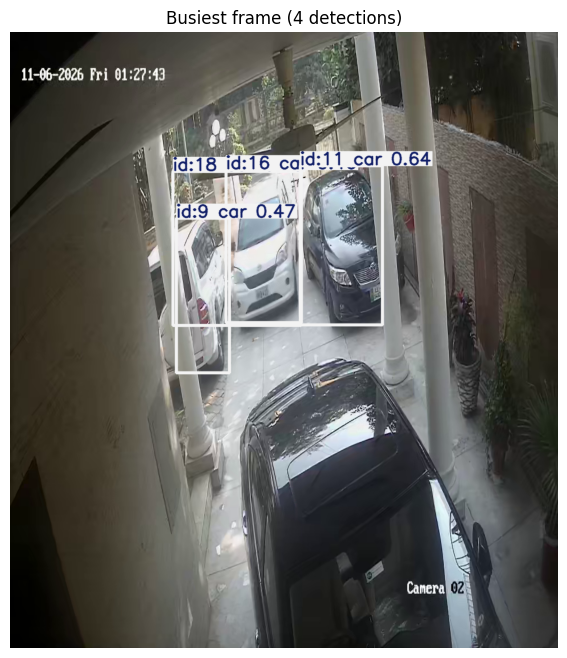

In [4]:
out_path = OUTPUT_DIR / f"{VIDEO_PATH.stem}_tracked.mp4"
writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH, HEIGHT))

unique_ids = {name: set() for name in TARGET_CLASSES.values()}
sample_frame, best_count = None, 0
t0 = time.time()

results = model.track(
    source=str(VIDEO_PATH),
    classes=list(TARGET_CLASSES),
    conf=CONF,
    imgsz=IMGSZ,
    tracker=TRACKER,
    device=DEVICE,
    persist=True,
    stream=True,      # generator: one frame at a time, low memory
    verbose=False,
)

for i, r in enumerate(results):
    annotated = r.plot()
    writer.write(annotated)

    if r.boxes.id is not None:
        for cls, tid in zip(r.boxes.cls.int().tolist(), r.boxes.id.int().tolist()):
            unique_ids[TARGET_CLASSES[cls]].add(tid)
        if len(r.boxes) > best_count:          # keep the busiest frame to preview
            best_count, sample_frame = len(r.boxes), annotated.copy()

    if i % 100 == 0:
        print(f"frame {i}/{NFRAMES}  ({(i + 1) / (time.time() - t0):.1f} fps)")

writer.release()
elapsed = time.time() - t0

print()
print(f"Done: {i + 1} frames in {elapsed:.1f}s ({(i + 1) / elapsed:.1f} fps)")
print(f"Saved: {out_path}")
print()
print("Unique objects tracked:")
for name, ids in unique_ids.items():
    print(f"  {name:<11}{len(ids)}")

if sample_frame is not None:
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Busiest frame ({best_count} detections)")
    plt.axis("off")
    plt.show()

## Comparing bigger YOLO26 models: s, m, l, x #

Same video, classes and tracker settings as above; only the model changes. Weights are stored in `models/`, and each run saves `data/outputs/<video>_<model>_tracked.mp4`.

Run the setup cell above first.

In [5]:
# ---------- Compare settings ----------
VARIANTS    = ["yolo26s", "yolo26m", "yolo26l", "yolo26x"]
MAX_SECONDS = None   # e.g. 60 to test only the first minute of video; None = full video


def load_model(name):
    """Load weights from models/, downloading them there on first use."""
    path = MODELS_DIR / f"{name}.pt"
    if not path.exists():
        YOLO(f"{name}.pt")                 # ultralytics downloads into the current folder
        Path(f"{name}.pt").replace(path)   # move it into models/
    return YOLO(str(path))


def run_tracking(model, tag):
    """Track TARGET_CLASSES on VIDEO_PATH, save an annotated video, return stats."""
    out_path = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{tag}_tracked.mp4"
    writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH, HEIGHT))
    max_frames = int(MAX_SECONDS * FPS) if MAX_SECONDS else NFRAMES

    unique_ids = {name: set() for name in TARGET_CLASSES.values()}
    sample_frame, best_count, n = None, 0, 0
    t0 = time.time()

    results = model.track(
        source=str(VIDEO_PATH),
        classes=list(TARGET_CLASSES),
        conf=CONF,
        imgsz=IMGSZ,
        tracker=TRACKER,
        device=DEVICE,
        persist=True,
        stream=True,
        verbose=False,
    )
    for i, r in enumerate(results):
        if i >= max_frames:
            break
        annotated = r.plot()
        writer.write(annotated)
        n = i + 1

        if r.boxes.id is not None:
            for cls, tid in zip(r.boxes.cls.int().tolist(), r.boxes.id.int().tolist()):
                unique_ids[TARGET_CLASSES[cls]].add(tid)
            if len(r.boxes) > best_count:
                best_count, sample_frame = len(r.boxes), annotated.copy()

        if i % 200 == 0:
            print(f"  [{tag}] frame {i}/{max_frames}  ({n / (time.time() - t0):.1f} fps)")

    writer.release()
    elapsed = time.time() - t0
    print(f"  [{tag}] done: {n} frames in {elapsed:.0f}s ({n / elapsed:.1f} fps) -> {out_path.name}")

    return {
        "model": tag,
        "frames": n,
        "seconds": elapsed,
        "fps": n / elapsed,
        "counts": {k: len(v) for k, v in unique_ids.items()},
        "video": out_path,
        "sample": sample_frame,
        "best_count": best_count,
    }


# Download any missing weights up front
for name in VARIANTS:
    load_model(name)
print("Weights in models/:", sorted(p.name for p in MODELS_DIR.glob("*.pt")))

Weights in models/: ['yolo26l.pt', 'yolo26m.pt', 'yolo26n.pt', 'yolo26s.pt', 'yolo26x.pt']


*reviewing the video footage shows that the smallest n variant is unable to track cars that are not fully present in the camera or obstructed, and detection is jittery*


*trying all variants to find the sweet spot*

### Run all variants #

In [6]:
# Runs every variant in VARIANTS. On a CPU this is slow: yolo26n took ~10 min on this video,
# and x is roughly 10x heavier, so expect hours for the full set. Set MAX_SECONDS above for a quick test.
compare_results = []
for name in VARIANTS:
    print(f"\n=== {name} ===")
    compare_results.append(run_tracking(load_model(name), name))


=== yolo26s ===
  [yolo26s] frame 0/4515  (3.0 fps)
  [yolo26s] frame 200/4515  (6.9 fps)
  [yolo26s] frame 400/4515  (7.0 fps)
  [yolo26s] frame 600/4515  (7.1 fps)
  [yolo26s] frame 800/4515  (7.1 fps)
  [yolo26s] frame 1000/4515  (7.1 fps)
  [yolo26s] frame 1200/4515  (7.1 fps)
  [yolo26s] frame 1400/4515  (7.2 fps)
  [yolo26s] frame 1600/4515  (7.2 fps)
  [yolo26s] frame 1800/4515  (7.2 fps)
  [yolo26s] frame 2000/4515  (7.1 fps)
  [yolo26s] frame 2200/4515  (7.1 fps)
  [yolo26s] frame 2400/4515  (7.1 fps)
  [yolo26s] frame 2600/4515  (7.1 fps)
  [yolo26s] frame 2800/4515  (7.1 fps)
  [yolo26s] frame 3000/4515  (7.1 fps)
  [yolo26s] frame 3200/4515  (7.1 fps)
  [yolo26s] frame 3400/4515  (7.1 fps)
  [yolo26s] frame 3600/4515  (7.1 fps)
  [yolo26s] frame 3800/4515  (7.1 fps)
  [yolo26s] frame 4000/4515  (7.1 fps)
  [yolo26s] frame 4200/4515  (7.1 fps)
  [yolo26s] frame 4400/4515  (7.1 fps)
  [yolo26s] done: 4515 frames in 633s (7.1 fps) -> 6_11_26_morning_cam2_yolo26s_tracked.mp4



### Results #

model         fps  time (s)      person     bicycle         car  motorcycle         bus       truck
---------------------------------------------------------------------------------------------------
yolo26s       7.1       633           6           0          13           0          57           0
yolo26m       2.9      1578           8           0          10           0           2           2
yolo26l       2.3      1963           6           0          15           0           0           1
yolo26x       1.2      3883           7           0          15           0           0           1

Videos saved:
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26s_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26m_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26l_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSy

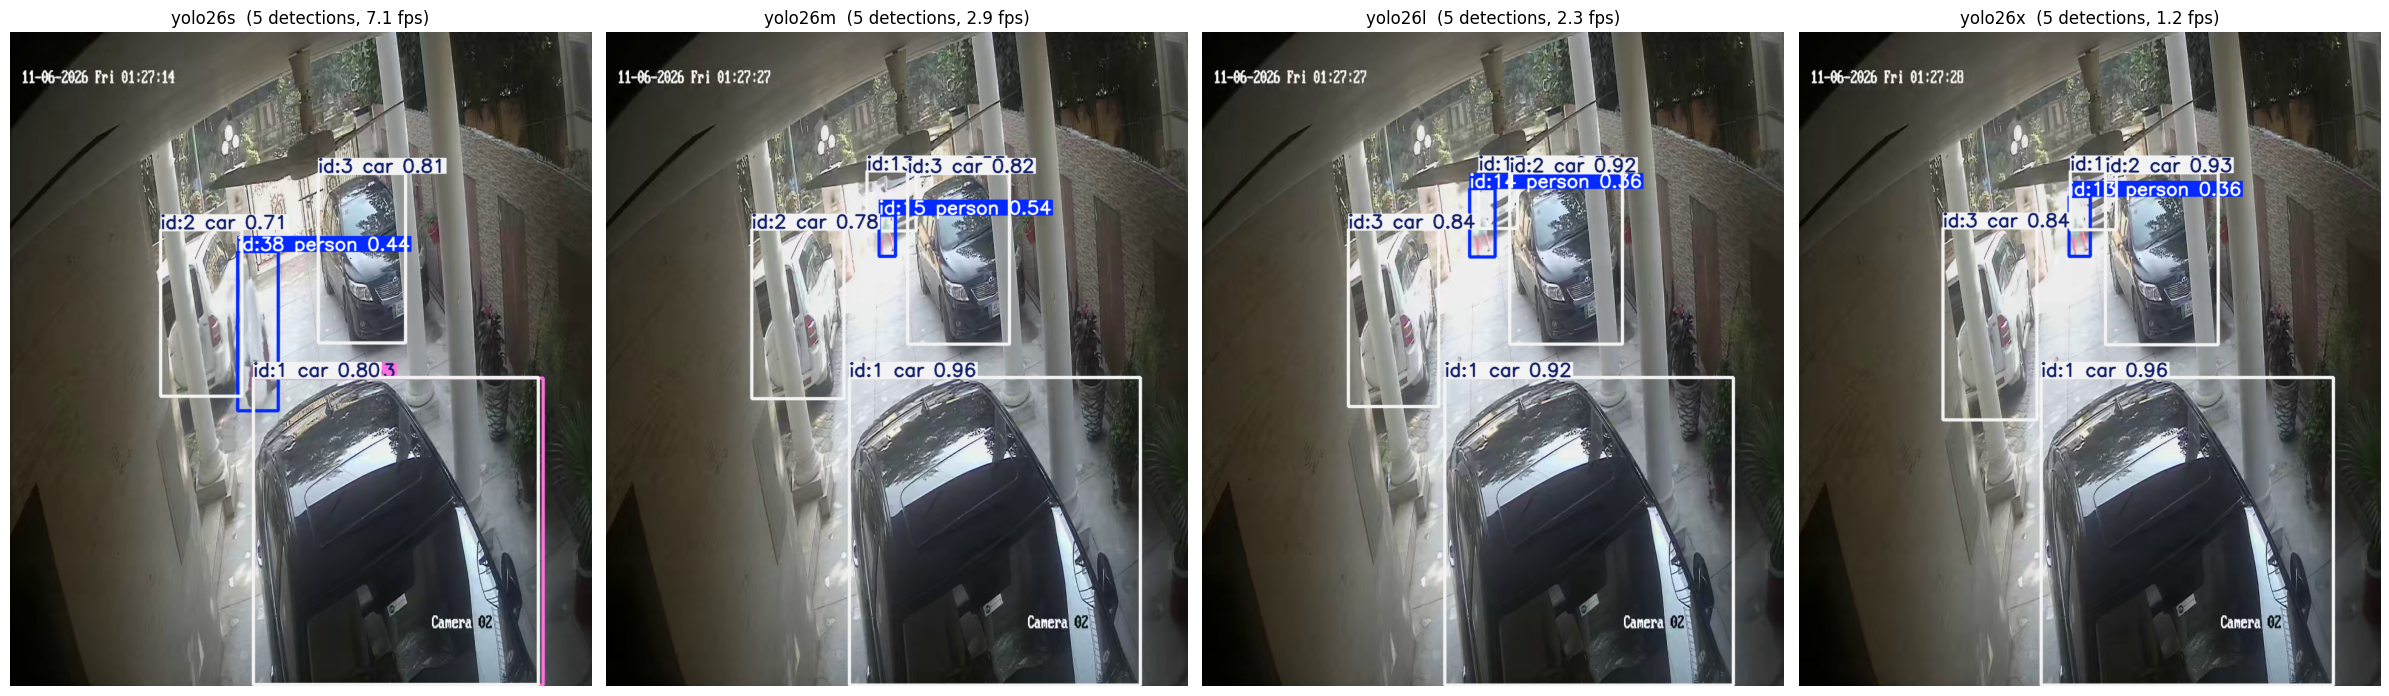

In [7]:
# ---------- Summary table ----------
classes = list(TARGET_CLASSES.values())
header = f"{'model':<10}{'fps':>7}{'time (s)':>10}" + "".join(f"{c:>12}" for c in classes)
print(header)
print("-" * len(header))
for res in compare_results:
    print(f"{res['model']:<10}{res['fps']:>7.1f}{res['seconds']:>10.0f}"
          + "".join(f"{res['counts'][c]:>12}" for c in classes))

print("\nVideos saved:")
for res in compare_results:
    print(" ", res["video"])

# ---------- Busiest frame from each model ----------
fig, axes = plt.subplots(1, len(compare_results), figsize=(6 * len(compare_results), 7))
axes = [axes] if len(compare_results) == 1 else axes
for ax, res in zip(axes, compare_results):
    if res["sample"] is not None:
        ax.imshow(cv2.cvtColor(res["sample"], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{res['model']}  ({res['best_count']} detections, {res['fps']:.1f} fps)")
    ax.axis("off")
plt.tight_layout()
plt.show()

*Even the S variant is running perfectly, and also has low inference speed (even if double that of n)*

# Passageway logic #

Counting cars that **enter or exit** through a gate: calibration (arrows + gate zone, then v2 with a crop), entry/exit detection, and findings.

## Camera calibration #

Each camera gets a config in `cameraConfigs/<camera_id>.json` with:

- **camera_type**: `passageway` (cars cross the frame and leave) or `parking_zone` (cars drive in and park in view)
- **entry** / **exit** arrows: the direction an entering / exiting car moves, in pixels and normalised 0-1 coords
- **gate_zone**: a polygon every entering/exiting car drives through. Cars that never touch it (e.g. main-road traffic) are ignored

For **cam1** (looking outside the gate): right → left = entering, left → right = exiting.

Running the next cell opens a separate window. Follow the prompts in it.

In [10]:
# Opens an OpenCV window (outside VS Code) on the camera video. Steps:
#   1. choose camera type: passageway or parking zone
#   2. drag the ENTRY arrow   3. drag the EXIT arrow
#   4. click the corners of the GATE ZONE (only cars that pass through it count)
#   5. save
# Saved to cameraConfigs/<CAMERA_ID>.json (+ a PNG snapshot of the arrows and gate zone).
import json
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

# ---------- Settings ----------
CAMERA_ID    = "cam1"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
CALIB_VIDEO  = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1.mp4"
CONFIG_DIR   = PROJECT_ROOT / "cameraConfigs"
CONFIG_PATH  = CONFIG_DIR / f"{CAMERA_ID}.json"
MAX_DISPLAY  = (1280, 720)          # window is scaled down to fit; coords are saved in full-res pixels

ENTRY_COLOR = (80, 200, 80)         # BGR green
EXIT_COLOR  = (60, 60, 230)         # BGR red
GATE_COLOR  = (0, 215, 255)         # BGR yellow
CAMERA_TYPES = {"passageway": "Passageway", "parking_zone": "Parking zone"}

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
assert CALIB_VIDEO.exists(), f"Video not found: {CALIB_VIDEO}"

cap = cv2.VideoCapture(str(CALIB_VIDEO))
VID_FPS = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
assert ok, "Could not read a frame from the video"
frame_idx = 0
H, W = frame.shape[:2]
scale = min(MAX_DISPLAY[0] / W, MAX_DISPLAY[1] / H, 1.0)
WIN = f"Calibrate {CAMERA_ID}"

state = {
    "stage": "type",                 # type -> entry -> exit -> gate -> review
    "cam_type": None,
    "arrows": {"entry": None, "exit": None},
    "gate": [],                      # polygon corners, full-res pixels
    "drag_start": None,
    "drag_now": None,
    "mouse": None,
    "buttons": {},
}


# ---------- Drawing helpers ----------
def to_orig(x, y):
    """Display coords -> full-resolution frame coords (clamped to the frame)."""
    return (min(max(int(round(x / scale)), 0), W - 1),
            min(max(int(round(y / scale)), 0), H - 1))


def text_box(img, lines, org=(12, 12)):
    font, fs, th, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1, 10, 26
    w = max(cv2.getTextSize(l, font, fs, th)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    x, y = org
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.78, img, 0.22, 0, img)
    for i, line in enumerate(lines):
        weight = 2 if i == 0 else 1
        cv2.putText(img, line, (x + pad, y + pad + 16 + lh * i), font, fs, (255, 255, 255), weight, cv2.LINE_AA)


def button(img, key, rect, label, color):
    x1, y1, x2, y2 = rect
    cv2.rectangle(img, (x1, y1), (x2, y2), color, -1)
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.putText(img, label, (x1 + (x2 - x1 - tw) // 2, y1 + (y2 - y1 + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    state["buttons"][key] = rect


def label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)


def arrow(img, start, end, color, text, s=1.0, thickness=4):
    p1 = (int(start[0] * s), int(start[1] * s))
    p2 = (int(end[0] * s), int(end[1] * s))
    length = max(np.hypot(p2[0] - p1[0], p2[1] - p1[1]), 1)
    cv2.arrowedLine(img, p1, p2, color, thickness, cv2.LINE_AA, tipLength=min(30 / length, 0.4))
    if text:
        label(img, text, (p1[0] + 8, p1[1] - 10), color)


def gate_poly(img, pts, s=1.0, closed=True, cursor=None, thickness=2):
    if not pts:
        return
    p = np.array([[int(x * s), int(y * s)] for x, y in pts], np.int32)
    if closed and len(p) >= 3:
        overlay = img.copy()
        cv2.fillPoly(overlay, [p], GATE_COLOR)
        cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)
        cv2.polylines(img, [p], True, GATE_COLOR, thickness, cv2.LINE_AA)
        label(img, "GATE", tuple(p.mean(axis=0).astype(int) - [30, 0]), GATE_COLOR)
    else:
        cv2.polylines(img, [p], False, GATE_COLOR, thickness, cv2.LINE_AA)
        if cursor is not None:                                   # rubber band to the mouse
            c = (int(cursor[0] * s), int(cursor[1] * s))
            cv2.line(img, tuple(p[-1]), c, GATE_COLOR, 1, cv2.LINE_AA)
            if len(p) >= 2:
                cv2.line(img, c, tuple(p[0]), GATE_COLOR, 1, cv2.LINE_AA)
    for q in p:
        cv2.circle(img, tuple(q), 5, GATE_COLOR, -1, cv2.LINE_AA)


def render():
    img = cv2.resize(frame, (int(W * scale), int(H * scale)))
    dh, dw = img.shape[:2]
    state["buttons"] = {}
    stage, ctype = state["stage"], CAMERA_TYPES.get(state["cam_type"], "")

    gate_poly(img, state["gate"], s=scale, closed=(stage == "review"),
              cursor=state["mouse"] if stage == "gate" else None)
    for name, color in (("entry", ENTRY_COLOR), ("exit", EXIT_COLOR)):
        if state["arrows"][name]:
            arrow(img, *state["arrows"][name], color, name.upper(), s=scale)
    if state["drag_start"] and state["drag_now"]:
        color = ENTRY_COLOR if stage == "entry" else EXIT_COLOR
        arrow(img, state["drag_start"], state["drag_now"], color, None, s=scale, thickness=2)

    if stage == "type":
        text_box(img, [
            "Step 1/4: Is this camera a passageway or a parking zone?",
            "Passageway: cars cross the frame and leave (L<->R or top<->bottom).",
            "Parking zone: cars drive in, park in view, and leave later.",
            "Click a button or press P / K.   N = skip 1 s ahead   Esc = cancel",
        ])
        bw, bh, cx, y = 270, 56, dw // 2, dh - 56 - 30
        button(img, "passageway", (cx - bw - 20, y, cx - 20, y + bh), "Passageway (P)", (150, 110, 40))
        button(img, "parking_zone", (cx + 20, y, cx + bw + 20, y + bh), "Parking zone (K)", (40, 110, 150))
    elif stage == "entry":
        text_box(img, [
            f"Step 2/4: Draw the ENTRY direction   [{ctype}]",
            "Click and drag along the path an ENTERING car takes.",
            "Backspace = back   N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "exit":
        text_box(img, [
            f"Step 3/4: Draw the EXIT direction   [{ctype}]",
            "Click and drag along the path an EXITING car takes.",
            "Backspace = redo entry   N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "gate":
        text_box(img, [
            f"Step 4/4: Mark the GATE ZONE   [{ctype}]   ({len(state['gate'])} points)",
            "Left-click each corner of the area every entering/exiting car drives through.",
            "Right-click or Enter = finish (3+ points)   Backspace = undo point",
            "N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "review":
        text_box(img, [
            f"Check the arrows and gate zone   [{ctype}]",
            "S or Enter = save   R = redo everything   G = redo gate zone only",
            "Esc = cancel without saving",
        ])
    return img


def finish_gate():
    if len(state["gate"]) >= 3:
        state["stage"] = "review"


def on_mouse(event, x, y, flags, param):
    stage = state["stage"]
    state["mouse"] = to_orig(x, y)
    if stage == "type" and event == cv2.EVENT_LBUTTONDOWN:
        for key, (x1, y1, x2, y2) in state["buttons"].items():
            if x1 <= x <= x2 and y1 <= y <= y2:
                state["cam_type"], state["stage"] = key, "entry"
    elif stage in ("entry", "exit"):
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_orig(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_orig(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            start, end = state["drag_start"], to_orig(x, y)
            state["drag_start"] = state["drag_now"] = None
            if np.hypot(end[0] - start[0], end[1] - start[1]) < 20 / scale:
                return                                  # too short: treat as a stray click
            state["arrows"][stage] = (start, end)
            state["stage"] = "exit" if stage == "entry" else "gate"
    elif stage == "gate":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["gate"].append(to_orig(x, y))
        elif event == cv2.EVENT_RBUTTONDOWN:
            finish_gate()


def arrow_dict(a):
    (x1, y1), (x2, y2) = a
    dx, dy = x2 - x1, y2 - y1
    n = float(np.hypot(dx, dy))
    return {
        "start": [x1, y1],
        "end": [x2, y2],
        "start_norm": [round(x1 / W, 4), round(y1 / H, 4)],   # 0-1, resolution independent
        "end_norm": [round(x2 / W, 4), round(y2 / H, 4)],
        "unit_vector": [round(dx / n, 4), round(dy / n, 4)],
    }


# ---------- Window loop ----------
saved = False
cv2.namedWindow(WIN, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(WIN, on_mouse)
try:
    while True:
        cv2.imshow(WIN, render())
        key = cv2.waitKey(20) & 0xFF
        if cv2.getWindowProperty(WIN, cv2.WND_PROP_VISIBLE) < 1 or key == 27:   # window closed / Esc
            break
        stage = state["stage"]

        if key in (ord("n"), ord("N")) and stage != "review" and not state["drag_start"]:
            for _ in range(int(VID_FPS)):
                ok, f = cap.read()
                if not ok:
                    break
                frame, frame_idx = f, frame_idx + 1

        if stage == "type":
            if key in (ord("p"), ord("P")):
                state["cam_type"], state["stage"] = "passageway", "entry"
            elif key in (ord("k"), ord("K")):
                state["cam_type"], state["stage"] = "parking_zone", "entry"
        elif stage in ("entry", "exit") and key == 8:                            # Backspace
            if stage == "exit":
                state["arrows"]["entry"], state["stage"] = None, "entry"
            else:
                state["cam_type"], state["stage"] = None, "type"
        elif stage == "gate":
            if key == 8:                                                         # Backspace
                if state["gate"]:
                    state["gate"].pop()
                else:
                    state["arrows"]["exit"], state["stage"] = None, "exit"
            elif key == 13:                                                      # Enter
                finish_gate()
        elif stage == "review":
            if key in (ord("r"), ord("R")):
                state["arrows"] = {"entry": None, "exit": None}
                state["gate"] = []
                state["stage"] = "entry"
            elif key in (ord("g"), ord("G")):
                state["gate"], state["stage"] = [], "gate"
            elif key in (ord("s"), ord("S"), 13):                               # S / Enter
                config = {
                    "camera_id": CAMERA_ID,
                    "camera_type": state["cam_type"],
                    "source": CALIB_VIDEO.relative_to(PROJECT_ROOT).as_posix(),
                    "frame_size": [W, H],
                    "calibration_frame": frame_idx,
                    "entry": arrow_dict(state["arrows"]["entry"]),
                    "exit": arrow_dict(state["arrows"]["exit"]),
                    "gate_zone": {
                        "points": [list(p) for p in state["gate"]],
                        "points_norm": [[round(x / W, 4), round(y / H, 4)] for x, y in state["gate"]],
                    },
                    "created_at": datetime.now().isoformat(timespec="seconds"),
                }
                CONFIG_PATH.write_text(json.dumps(config, indent=2))

                snap = frame.copy()
                gate_poly(snap, state["gate"], thickness=3)
                arrow(snap, *state["arrows"]["entry"], ENTRY_COLOR, "ENTRY", thickness=6)
                arrow(snap, *state["arrows"]["exit"], EXIT_COLOR, "EXIT", thickness=6)
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_calibration.png"), snap)
                saved = True
                break
finally:
    cap.release()
    cv2.destroyWindow(WIN)
    cv2.waitKey(1)

if saved:
    e, x = config["entry"]["unit_vector"], config["exit"]["unit_vector"]
    print(f"Saved {CONFIG_PATH}")
    print(json.dumps(config, indent=2))
    if config["camera_type"] == "passageway" and (e[0] * x[0] + e[1] * x[1]) > -0.5:
        print("\nNote: for a passageway the entry and exit arrows usually point in roughly opposite directions.")
else:
    print("Calibration cancelled, nothing saved.")

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\cameraConfigs\cam1.json
{
  "camera_id": "cam1",
  "camera_type": "passageway",
  "source": "data/videos/6_11_26_morning_cam1.mp4",
  "frame_size": [
    960,
    1080
  ],
  "calibration_frame": 0,
  "entry": {
    "start": [
      732,
      416
    ],
    "end": [
      444,
      816
    ],
    "start_norm": [
      0.7625,
      0.3852
    ],
    "end_norm": [
      0.4625,
      0.7556
    ],
    "unit_vector": [
      -0.5843,
      0.8115
    ]
  },
  "exit": {
    "start": [
      364,
      740
    ],
    "end": [
      678,
      362
    ],
    "start_norm": [
      0.3792,
      0.6852
    ],
    "end_norm": [
      0.7063,
      0.3352
    ],
    "unit_vector": [
      0.639,
      -0.7692
    ]
  },
  "gate_zone": {
    "points": [
      [
        10,
        886
      ],
      [
        190,
        768
      ],
      [
        405,
        1076
      ],
      [
        12,
        1078
      ],
      [
       

### Check the saved calibration #

cam1: passageway   frame 960x1080
  entry [732, 416] -> [444, 816]   direction [-0.5843, 0.8115]
  exit  [364, 740] -> [678, 362]   direction [0.639, -0.7692]
  gate  [[10, 886], [190, 768], [405, 1076], [12, 1078], [12, 968]]


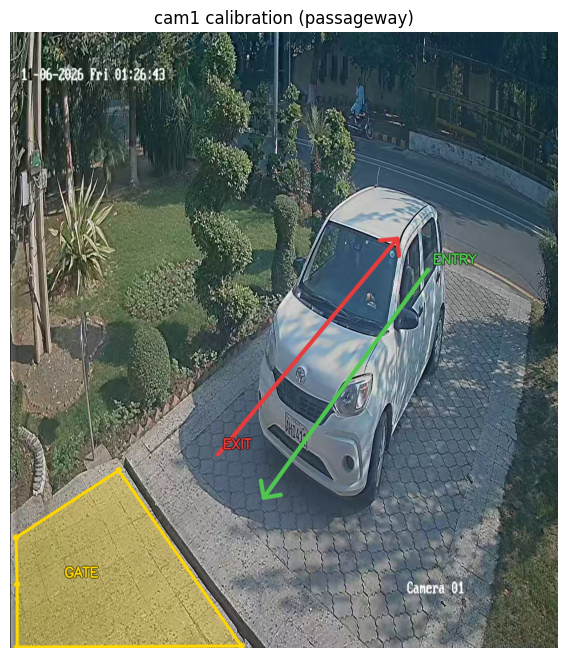

In [11]:
# Show the saved calibration for a camera
import json
import cv2
import matplotlib.pyplot as plt

cfg = json.loads(CONFIG_PATH.read_text())
print(f"{cfg['camera_id']}: {cfg['camera_type']}   frame {cfg['frame_size'][0]}x{cfg['frame_size'][1]}")
print(f"  entry {cfg['entry']['start']} -> {cfg['entry']['end']}   direction {cfg['entry']['unit_vector']}")
print(f"  exit  {cfg['exit']['start']} -> {cfg['exit']['end']}   direction {cfg['exit']['unit_vector']}")
gate = cfg.get("gate_zone")
print(f"  gate  {gate['points'] if gate else 'not set (rerun calibration)'}")

snap = cv2.imread(str(CONFIG_DIR / f"{cfg['camera_id']}_calibration.png"))
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(snap, cv2.COLOR_BGR2RGB))
plt.title(f"{cfg['camera_id']} calibration ({cfg['camera_type']})")
plt.axis("off")
plt.show()

## Entry / exit detection: cam1, YOLO26s #

Uses `cameraConfigs/cam1.json` (entry/exit arrows + gate zone). Each vehicle's point is recorded ~5x per second; once it leaves the frame its **net displacement** is compared to the entry and exit arrows (cosine similarity), so turns and three-point turns don't affect the result. Only vehicles that pass through the **gate zone** can count, which filters out main-road traffic.

Outputs in `data/outputs/`:
- `<video>_yolo26s_entry_exit.mp4`: annotated video, notifications top-right, the car's path drawn for a few seconds
- `<video>_yolo26s_events.json`: every entry/exit event (time, track, path, scores) plus ignored tracks and why

In [13]:
# Entry / exit counting for one camera, using its calibration config (arrows + gate zone).
#
# For every tracked vehicle:
#   1. record its (smoothed) box point ~5x per second, noting whether it is inside the gate zone
#   2. when the tracker has lost it for FINALIZE_AFTER_S (it left the frame), decide:
#        - never touched the gate zone            -> ignored (e.g. main-road traffic)
#        - net displacement too small             -> ignored (parked / jitter / drove in and backed out)
#        - displacement direction vs entry/exit arrows (cosine) -> best match if >= MIN_COS
#        - order check: entry = gate visited near the END of the track, exit = near the START
#   3. on entry/exit: top-right notification + the car's path drawn for NOTIFY_S seconds
# Turns and three-point turns don't matter: only where the car started and ended up counts.
import json
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam1"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1_test_0033-0200.mp4"  # test clip; full video: 6_11_26_morning_cam1.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker (main knobs for jittery / dropped detections) ----------
CONF              = 0.10   # detector floor. Keep LOW: weak boxes are what keep a track alive when the car blurs
TRACK_HIGH_THRESH = 0.30   # boxes above this are matched to tracks first
TRACK_LOW_THRESH  = 0.10   # weak boxes (low..high) can still CONTINUE an existing track (ByteTrack's 2nd pass)
NEW_TRACK_THRESH  = 0.40   # a NEW track only starts from a box this confident, so low CONF doesn't create junk tracks
MATCH_THRESH      = 0.85   # association leniency; higher accepts bigger jumps between frames (fast/large cars)
TRACK_BUFFER_S    = 3.0    # tracker keeps a lost ID this long, so the SAME id resumes after a dropout

# ---------- Persistence: our own track records ----------
COAST_S          = 1.0     # keep drawing a lost car (predicted box + trail) this long: no flicker on short dropouts
FINALIZE_AFTER_S = 3.0     # wait this long after the last sighting before deciding (should be >= TRACK_BUFFER_S)
EDGE_FINALIZE_S  = 0.7     # ...but decide sooner if the car was last seen touching the frame edge (it drove out)
EDGE_MARGIN_PX   = 12      # "touching the edge" = box within this many pixels of the border
STITCH_DIST_FRAC = 0.15    # new ID appearing this close (fraction of frame diagonal) to a lost car's predicted spot = same car
SMOOTH_ALPHA     = 0.4     # point smoothing between frames (1 = none, lower = smoother but laggier)
VEL_ALPHA        = 0.3     # velocity smoothing, used to predict where a lost car is

POINT_MODE       = "bottom"   # "bottom" = bottom-centre of the box (where the car meets the ground), "center" = box centre
SAMPLE_EVERY_S   = 0.2        # record the point this often
MIN_SAMPLES      = 5          # fewer recorded points than this -> ignored
MIN_DISP_FRAC    = 0.15       # net movement must be >= this fraction of the arrow length
MIN_COS          = 0.5        # direction must be within ~60 degrees of the arrow
ORDER_SPLIT      = 0.5        # entry: last gate visit in the later half of the track; exit: first gate visit in the earlier half
HIGH_CONF_COS    = 0.8        # cosine above this -> "high" confidence
NOTIFY_S         = 4.0        # how long the notification and path stay on screen
TRAIL_LEN        = 60         # recorded points shown as a live trail behind each car

ENTRY_COLOR = (80, 200, 80)   # BGR
EXIT_COLOR  = (60, 60, 230)
GATE_COLOR  = (0, 215, 255)
TRACK_COLOR = (200, 200, 200)
EVENT_COLORS = {"entry": ENTRY_COLOR, "exit": EXIT_COLOR}
EVENT_WORDS  = {"entry": "ENTERED", "exit": "EXITED"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_entry_exit.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_events.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("gate_zone"), "Config has no gate_zone: rerun the calibration cell"
assert cfg.get("config_version", 1) == 1, "This is a v2 (cropped) config: use the 'Entry / exit detection v2' cell"

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
W       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()


def denorm(p):
    """Normalised config coords -> pixels of THIS video (works if the resolution differs from calibration)."""
    return np.array([p[0] * W, p[1] * H], dtype=float)


GATE = np.array([denorm(p) for p in cfg["gate_zone"]["points_norm"]], dtype=np.float32)
ARROWS = {}
for kind in ("entry", "exit"):
    s, e = denorm(cfg[kind]["start_norm"]), denorm(cfg[kind]["end_norm"])
    ARROWS[kind] = {"start": s, "end": e, "unit": (e - s) / np.linalg.norm(e - s)}

ARROW_LEN      = float(np.mean([np.linalg.norm(a["end"] - a["start"]) for a in ARROWS.values()]))
MIN_DISP       = MIN_DISP_FRAC * ARROW_LEN
STITCH_DIST    = STITCH_DIST_FRAC * float(np.hypot(W, H))
SAMPLE_EVERY   = max(1, round(SAMPLE_EVERY_S * FPS))
FINALIZE_AFTER = max(1, round(FINALIZE_AFTER_S * FPS))
EDGE_FINALIZE  = max(1, round(EDGE_FINALIZE_S * FPS))
COAST_FRAMES   = round(COAST_S * FPS)
NOTIFY_FRAMES  = round(NOTIFY_S * FPS)

# Tracker config generated from the settings above (track_buffer is in frames)
TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def in_gate(pt):
    return cv2.pointPolygonTest(GATE, (float(pt[0]), float(pt[1])), False) >= 0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Track records ----------
class Track:
    def __init__(self, key, frame):
        self.key = key                 # display id = first tracker id
        self.ids = [key]               # all tracker ids stitched into this car
        self.first_frame = frame
        self.last_frame = frame
        self.smooth = None
        self.vel = np.zeros(2)         # smoothed px/frame, used to predict a lost car's position
        self.last_box = None
        self.samples = []              # (frame, x, y, in_gate)
        self.cls_votes = {}

    def update(self, pt, cls, frame, box):
        if self.smooth is None:
            self.smooth = pt
        else:
            gap = max(frame - self.last_frame, 1)
            new = SMOOTH_ALPHA * pt + (1 - SMOOTH_ALPHA) * self.smooth
            self.vel = VEL_ALPHA * (new - self.smooth) / gap + (1 - VEL_ALPHA) * self.vel
            self.smooth = new
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        if not self.samples or frame - self.samples[-1][0] >= SAMPLE_EVERY:
            self.samples.append((frame, float(self.smooth[0]), float(self.smooth[1]), in_gate(self.smooth)))
        self.last_frame = frame
        self.last_box = np.array(box, dtype=float)

    def predicted_shift(self, frame):
        """How far the car has probably moved since it was last seen (capped at COAST_S)."""
        return self.vel * min(frame - self.last_frame, COAST_FRAMES)

    @property
    def at_edge(self):
        x1, y1, x2, y2 = self.last_box
        m = EDGE_MARGIN_PX
        return x1 <= m or y1 <= m or x2 >= W - m or y2 >= H - m

    def finalize_after(self):
        return EDGE_FINALIZE if self.at_edge else FINALIZE_AFTER

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def points(self):
        return np.array([[s[1], s[2]] for s in self.samples], dtype=float)


def classify(t):
    """Return (result, None) for an entry/exit, or (None, reason) if the track is ignored."""
    S = t.samples
    if len(S) < MIN_SAMPLES:
        return None, f"too few samples ({len(S)})"
    gate_idx = [i for i, s in enumerate(S) if s[3]]
    if not gate_idx:
        return None, "never entered the gate zone"

    pts = t.points()
    k = max(1, min(3, len(pts) // 3))                 # median of first/last few points = less jitter
    start, end = np.median(pts[:k], axis=0), np.median(pts[-k:], axis=0)
    disp = end - start
    dist = float(np.linalg.norm(disp))
    if dist < MIN_DISP:
        return None, f"moved too little ({dist:.0f}px < {MIN_DISP:.0f}px)"

    cos = {kind: float(disp @ a["unit"] / dist) for kind, a in ARROWS.items()}
    kind = max(cos, key=cos.get)
    if cos[kind] < MIN_COS:
        return None, f"direction matches neither arrow (cos entry {cos['entry']:.2f}, exit {cos['exit']:.2f})"

    n = max(len(S) - 1, 1)
    first_gate, last_gate = gate_idx[0] / n, gate_idx[-1] / n
    if kind == "entry" and last_gate < ORDER_SPLIT:
        return None, f"entry direction but the gate was visited early (last visit at {last_gate:.0%} of track)"
    if kind == "exit" and first_gate > ORDER_SPLIT:
        return None, f"exit direction but the gate was visited late (first visit at {first_gate:.0%} of track)"

    return {
        "type": kind,
        "confidence": "high" if cos[kind] >= HIGH_CONF_COS else "medium",
        "cos_entry": round(cos["entry"], 3),
        "cos_exit": round(cos["exit"], 3),
        "start_point": [round(v, 1) for v in start],
        "end_point": [round(v, 1) for v in end],
        "displacement_px": [round(v, 1) for v in disp],
        "distance_px": round(dist, 1),
        "gate_samples": len(gate_idx),
        "gate_first_visit_frac": round(first_gate, 3),
        "gate_last_visit_frac": round(last_gate, 3),
    }, None


tracks, lost, alias = {}, {}, {}     # active records, recently lost records, tracker id -> record key
events, ignored = [], []
notifications = deque()               # (event, until_frame, path points)
counts = {"entry": 0, "exit": 0}


def finalize(t, frame):
    result, reason = classify(t)
    base = {
        "track_ids": t.ids,
        "class": t.label,
        "first_seen_s": round(t.first_frame / FPS, 2),
        "last_seen_s": round(t.last_frame / FPS, 2),
        "duration_s": round((t.last_frame - t.first_frame) / FPS, 2),
        "num_samples": len(t.samples),
    }
    if result is None:
        ignored.append({**base, "reason": reason})
        return
    counts[result["type"]] += 1
    event = {
        "event_id": len(events) + 1,
        "camera_id": CAMERA_ID,
        "type": result["type"],
        "video_time_s": round(t.last_frame / FPS, 2),
        "video_time": fmt_time(t.last_frame / FPS),
        "frame": t.last_frame,
        "decided_at_frame": frame,
        **base,
        **{k: v for k, v in result.items() if k != "type"},
        "path": [[round(f / FPS, 2), round(x, 1), round(y, 1), g] for f, x, y, g in t.samples],  # [t_s, x, y, in_gate]
    }
    events.append(event)
    notifications.append((event, frame + NOTIFY_FRAMES, t.points()))
    print(f"  {EVENT_WORDS[event['type']]:<8} {t.label} #{t.key} at {event['video_time']} "
          f"(cos {max(result['cos_entry'], result['cos_exit']):.2f}, {result['confidence']})")


def stitch(pt, frame):
    """Find a just-lost track that ended near this new detection (ID switch, occlusion)."""
    best, best_d = None, STITCH_DIST
    for key, t in lost.items():
        if frame - t.last_frame <= FINALIZE_AFTER and t.smooth is not None:
            d = float(np.linalg.norm(t.smooth + t.predicted_shift(frame) - pt))
            if d < best_d:
                best, best_d = key, d
    return best


# ---------- Drawing ----------
def text_box(img, lines, x, y, color, anchor_right=False):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 10, 24
    w = max(cv2.getTextSize(l, font, fs, 2)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    if anchor_right:
        x = x - w
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.75, img, 0.25, 0, img)
    cv2.rectangle(img, (x, y), (x + 6, y + h), color, -1)                 # colour strip = event type
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad + 4, y + pad + 14 + lh * i), font, fs,
                    (255, 255, 255), 2 if i == 0 else 1, cv2.LINE_AA)
    return h


def draw_frame(img, frame, boxes):
    # gate zone + faint arrows
    overlay = img.copy()
    cv2.fillPoly(overlay, [GATE.astype(np.int32)], GATE_COLOR)
    cv2.addWeighted(overlay, 0.18, img, 0.82, 0, img)
    cv2.polylines(img, [GATE.astype(np.int32)], True, GATE_COLOR, 2, cv2.LINE_AA)
    for kind, a in ARROWS.items():
        cv2.arrowedLine(img, tuple(a["start"].astype(int)), tuple(a["end"].astype(int)),
                        EVENT_COLORS[kind], 1, cv2.LINE_AA, tipLength=0.04)

    # live tracks: box, trail, label (yellow outline once the car has touched the gate zone).
    # Cars lost for <= COAST_S are still drawn at their predicted position with a thin box, so short dropouts don't flicker.
    live = [(tracks[key], np.array(box, dtype=float), False) for key, box in boxes]
    live += [(t, t.last_box + np.tile(t.predicted_shift(frame), 2), True)
             for t in lost.values() if frame - t.last_frame <= COAST_FRAMES and t.last_box is not None]
    for t, (x1, y1, x2, y2), coasting in live:
        touched = any(s[3] for s in t.samples)
        trail = t.points()[-TRAIL_LEN:].astype(np.int32)
        if len(trail) >= 2:
            cv2.polylines(img, [trail], False, TRACK_COLOR, 2, cv2.LINE_AA)
        color = GATE_COLOR if touched else TRACK_COLOR
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 1 if coasting else 2)
        tag = f"{t.label} #{t.key}" + (" (lost)" if coasting else "")
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

    # paths of recent entry/exit events
    while notifications and notifications[0][1] < frame:
        notifications.popleft()
    for event, until, pts in notifications:
        color = EVENT_COLORS[event["type"]]
        p = pts.astype(np.int32)
        if len(p) >= 2:
            cv2.polylines(img, [p], False, color, 4, cv2.LINE_AA)
            cv2.arrowedLine(img, tuple(p[max(0, len(p) - 4)]), tuple(p[-1]), color, 4, cv2.LINE_AA, tipLength=0.5)
            cv2.circle(img, tuple(p[0]), 7, color, -1, cv2.LINE_AA)

    # notifications top-right, newest on top
    y = 12
    for event, until, _ in reversed(notifications):
        y += text_box(img, [
            f"{EVENT_WORDS[event['type']]}: {event['class']} #{event['track_ids'][0]}",
            f"at {event['video_time']}  ({event['confidence']} confidence)",
        ], W - 12, y, EVENT_COLORS[event["type"]], anchor_right=True) + 8

    # counters top-left
    text_box(img, [f"Entered: {counts['entry']}", f"Exited:  {counts['exit']}",
                   f"{fmt_time(frame / FPS)}"], 12, 12, GATE_COLOR)


# ---------- Run ----------
print(f"{CAMERA_ID} ({cfg['camera_type']}) | {VIDEO_PATH.name} {W}x{H} @ {FPS:.1f} fps, {NFRAMES} frames | {MODEL_NAME} on {DEVICE}")
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
t0 = time.time()
frame = -1

results = model.track(
    source=str(VIDEO_PATH),
    classes=list(VEHICLE_CLASSES),
    conf=CONF,
    imgsz=IMGSZ,
    tracker=str(TRACKER),
    device=DEVICE,
    persist=True,
    stream=True,
    verbose=False,
)

for frame, r in enumerate(results):
    seen, boxes = set(), []
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), tid, cls in zip(r.boxes.xyxy.cpu().numpy(),
                                               r.boxes.id.int().tolist(),
                                               r.boxes.cls.int().tolist()):
            pt = np.array([(x1 + x2) / 2, y2 if POINT_MODE == "bottom" else (y1 + y2) / 2], dtype=float)
            key = alias.get(tid)
            if key is None:                                   # new tracker id
                key = stitch(pt, frame)
                if key is not None:                           # continuation of a just-lost car
                    tracks[key] = lost.pop(key)
                    tracks[key].ids.append(tid)
                    tracks[key].smooth = None
                else:
                    key = tid
                    tracks[key] = Track(key, frame)
                alias[tid] = key
            elif key in lost:                                 # same id came back
                tracks[key] = lost.pop(key)
            elif key not in tracks:                           # id came back after its record was finalized
                tracks[key] = Track(key, frame)
            if key in seen:                                   # two boxes mapped to one car this frame
                continue
            tracks[key].update(pt, cls, frame, (x1, y1, x2, y2))
            seen.add(key)
            boxes.append((key, (x1, y1, x2, y2)))

    for key in [k for k in tracks if k not in seen]:          # not detected this frame
        lost[key] = tracks.pop(key)
    for key in [k for k, t in lost.items() if frame - t.last_frame >= t.finalize_after()]:
        finalize(lost.pop(key), frame)                        # gone long enough (or drove out of frame): decide

    img = r.orig_img.copy()
    draw_frame(img, frame, boxes)
    writer.write(img)

    if frame % 300 == 0:
        print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)")

for t in list(tracks.values()) + list(lost.values()):           # cars still in view when the video ends
    finalize(t, frame)
writer.release()
elapsed = time.time() - t0

# ---------- Save events ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": cfg["camera_type"],
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "point_mode": POINT_MODE,
        "tracker": TRACKER.read_text(),
        "coast_s": COAST_S, "edge_finalize_s": EDGE_FINALIZE_S,
        "sample_every_s": SAMPLE_EVERY_S, "finalize_after_s": FINALIZE_AFTER_S,
        "min_disp_px": round(MIN_DISP, 1), "min_cos": MIN_COS, "order_split": ORDER_SPLIT,
        "stitch_dist_px": round(STITCH_DIST, 1),
    },
    "counts": counts,
    "events": events,
    "ignored_tracks": ignored,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Entered: {counts['entry']}   Exited: {counts['exit']}   Ignored tracks: {len(ignored)}")
print(f"Video : {OUT_VIDEO}")
print(f"Events: {OUT_JSON}")

reasons = {}
for t in ignored:
    r_ = t["reason"].split(" (")[0]
    reasons[r_] = reasons.get(r_, 0) + 1
print("\nWhy tracks were ignored:")
for r_, n in sorted(reasons.items(), key=lambda kv: -kv[1]):
    print(f"  {n:>4}  {r_}")

cam1 (passageway) | 6_11_26_morning_cam1_test_0033-0200.mp4 960x1080 @ 15.0 fps, 1306 frames | yolo26s on cpu
frame 0/1306  (1.8 fps)
frame 300/1306  (4.0 fps)
  ENTERED  car #6 at 00:19.9 (cos 0.93, high)
  ENTERED  car #6 at 00:23.0 (cos 0.59, medium)
frame 600/1306  (3.6 fps)
frame 900/1306  (3.4 fps)
frame 1200/1306  (3.3 fps)

Done: 1306 frames in 391s (3.3 fps)
Entered: 2   Exited: 0   Ignored tracks: 16
Video : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_entry_exit.mp4
Events: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_events.json

Why tracks were ignored:
    13  never entered the gate zone
     3  too few samples


## Camera calibration v2: crop first #

Same as the calibration above, with a **crop** step first: drag a rectangle around the driveway and gate to leave out the main road. Passageway/parking, the entry and exit arrows and the gate zone are then drawn on the cropped image.

Saves `cameraConfigs/cam1.json` as **config_version 2** (arrows and gate in crop coordinates), plus `cam1_calibration.png` and `cam1_crop.png`. This overwrites the v1 config. Details: `docs/camera-config-and-stream.md`.

In [14]:
# Camera calibration v2 (with crop). Opens an OpenCV window (outside VS Code). Steps:
#   1. CROP: drag a rectangle around the area to keep (driveway + gate); leave out the road etc.
#   2. on the cropped image: choose passageway / parking zone
#   3. drag the ENTRY arrow   4. drag the EXIT arrow
#   5. click the corners of the GATE ZONE   -> review -> save
# Saved to cameraConfigs/<CAMERA_ID>.json (config_version 2). Arrows and gate are stored in CROP coordinates.
import json
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

# ---------- Settings ----------
CAMERA_ID    = "cam1"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
CALIB_VIDEO  = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1.mp4"
CONFIG_DIR   = PROJECT_ROOT / "cameraConfigs"
CONFIG_PATH  = CONFIG_DIR / f"{CAMERA_ID}.json"
MAX_DISPLAY  = (1280, 720)          # window size limit; coords are always saved in real pixels
MAX_UPSCALE  = 2.0                  # small crops are enlarged up to this much so they're easy to draw on
MIN_CROP_PX  = 64                   # smallest allowed crop side

ENTRY_COLOR = (80, 200, 80)         # BGR green
EXIT_COLOR  = (60, 60, 230)         # BGR red
GATE_COLOR  = (0, 215, 255)         # BGR yellow
CROP_COLOR  = (255, 180, 60)        # BGR light blue
CAMERA_TYPES = {"passageway": "Passageway", "parking_zone": "Parking zone"}

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
assert CALIB_VIDEO.exists(), f"Video not found: {CALIB_VIDEO}"

cap = cv2.VideoCapture(str(CALIB_VIDEO))
VID_FPS = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
assert ok, "Could not read a frame from the video"
frame_idx = 0
FH, FW = frame.shape[:2]
WIN = f"Calibrate {CAMERA_ID}"

state = {
    "stage": "crop",                 # crop -> type -> entry -> exit -> gate -> review
    "crop": None,                    # (x1, y1, x2, y2) in full-frame pixels
    "cam_type": None,
    "arrows": {"entry": None, "exit": None},   # crop pixels
    "gate": [],                                # crop pixels
    "drag_start": None,
    "drag_now": None,
    "mouse": None,
    "buttons": {},
    "scale": 1.0,
    "view_wh": (FW, FH),
}


# ---------- View helpers ----------
def view_img():
    """Full frame while choosing the crop, the cropped region afterwards."""
    if state["stage"] == "crop" or state["crop"] is None:
        return frame
    x1, y1, x2, y2 = state["crop"]
    return frame[y1:y2, x1:x2]


def to_view(x, y):
    """Window coords -> view pixel coords (clamped)."""
    s, (vw, vh) = state["scale"], state["view_wh"]
    return (min(max(int(round(x / s)), 0), vw - 1), min(max(int(round(y / s)), 0), vh - 1))


def reset_after_crop():
    state["cam_type"] = None
    state["arrows"] = {"entry": None, "exit": None}
    state["gate"] = []


# ---------- Drawing helpers ----------
def text_box(img, lines, org=(12, 12)):
    font, fs, th, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1, 10, 26
    w = max(cv2.getTextSize(l, font, fs, th)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    x, y = org
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.78, img, 0.22, 0, img)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad, y + pad + 16 + lh * i), font, fs, (255, 255, 255),
                    2 if i == 0 else 1, cv2.LINE_AA)


def button(img, key, rect, label_text, color):
    x1, y1, x2, y2 = rect
    cv2.rectangle(img, (x1, y1), (x2, y2), color, -1)
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)
    (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.putText(img, label_text, (x1 + (x2 - x1 - tw) // 2, y1 + (y2 - y1 + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    state["buttons"][key] = rect


def label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)


def arrow(img, start, end, color, text, s=1.0, thickness=4):
    p1 = (int(start[0] * s), int(start[1] * s))
    p2 = (int(end[0] * s), int(end[1] * s))
    length = max(np.hypot(p2[0] - p1[0], p2[1] - p1[1]), 1)
    cv2.arrowedLine(img, p1, p2, color, thickness, cv2.LINE_AA, tipLength=min(30 / length, 0.4))
    if text:
        label(img, text, (p1[0] + 8, p1[1] - 10), color)


def gate_poly(img, pts, s=1.0, closed=True, cursor=None, thickness=2):
    if not pts:
        return
    p = np.array([[int(x * s), int(y * s)] for x, y in pts], np.int32)
    if closed and len(p) >= 3:
        overlay = img.copy()
        cv2.fillPoly(overlay, [p], GATE_COLOR)
        cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)
        cv2.polylines(img, [p], True, GATE_COLOR, thickness, cv2.LINE_AA)
        label(img, "GATE", tuple(p.mean(axis=0).astype(int) - [30, 0]), GATE_COLOR)
    else:
        cv2.polylines(img, [p], False, GATE_COLOR, thickness, cv2.LINE_AA)
        if cursor is not None:
            c = (int(cursor[0] * s), int(cursor[1] * s))
            cv2.line(img, tuple(p[-1]), c, GATE_COLOR, 1, cv2.LINE_AA)
            if len(p) >= 2:
                cv2.line(img, c, tuple(p[0]), GATE_COLOR, 1, cv2.LINE_AA)
    for q in p:
        cv2.circle(img, tuple(q), 5, GATE_COLOR, -1, cv2.LINE_AA)


def draw_crop_rect(img, rect, s):
    """Dim everything outside the rectangle and outline it."""
    x1, y1, x2, y2 = [int(v * s) for v in rect]
    dimmed = (img * 0.35).astype(np.uint8)
    dimmed[y1:y2, x1:x2] = img[y1:y2, x1:x2]
    img[:] = dimmed
    cv2.rectangle(img, (x1, y1), (x2, y2), CROP_COLOR, 2, cv2.LINE_AA)


def drag_rect():
    (ax, ay), (bx, by) = state["drag_start"], state["drag_now"]
    return min(ax, bx), min(ay, by), max(ax, bx), max(ay, by)


def render():
    stage = state["stage"]
    v = view_img()
    vh, vw = v.shape[:2]
    s = min(MAX_DISPLAY[0] / vw, MAX_DISPLAY[1] / vh)
    s = min(s, 1.0) if stage == "crop" else min(s, MAX_UPSCALE)
    state["scale"], state["view_wh"] = s, (vw, vh)
    img = cv2.resize(v, (int(vw * s), int(vh * s)))
    dh, dw = img.shape[:2]
    state["buttons"] = {}
    ctype = CAMERA_TYPES.get(state["cam_type"], "")

    if stage == "crop":
        rect = drag_rect() if state["drag_start"] and state["drag_now"] else state["crop"]
        if rect:
            draw_crop_rect(img, rect, s)
        text_box(img, [
            "Step 1/5: CROP to the area that matters",
            "Drag a rectangle around the driveway + gate. Leave out the main road",
            "and anything cars don't use to enter/exit. Only this area is sent to YOLO.",
            "Enter = use crop   F = use full frame   N = skip 1 s ahead   Esc = cancel",
        ])
        return img

    gate_poly(img, state["gate"], s=s, closed=(stage == "review"),
              cursor=state["mouse"] if stage == "gate" else None)
    for name, color in (("entry", ENTRY_COLOR), ("exit", EXIT_COLOR)):
        if state["arrows"][name]:
            arrow(img, *state["arrows"][name], color, name.upper(), s=s)
    if state["drag_start"] and state["drag_now"]:
        color = ENTRY_COLOR if stage == "entry" else EXIT_COLOR
        arrow(img, state["drag_start"], state["drag_now"], color, None, s=s, thickness=2)

    if stage == "type":
        text_box(img, [
            "Step 2/5: Passageway or parking zone?",
            "Passageway: cars cross and leave. Parking zone: cars park in view.",
            "Click a button or press P / K.   Backspace = redo crop   Esc = cancel",
        ])
        bw, bh = min(240, dw // 2 - 30), 52
        cx, y = dw // 2, dh - bh - 24
        button(img, "passageway", (cx - bw - 10, y, cx - 10, y + bh), "Passageway (P)", (150, 110, 40))
        button(img, "parking_zone", (cx + 10, y, cx + bw + 10, y + bh), "Parking (K)", (40, 110, 150))
    elif stage == "entry":
        text_box(img, [f"Step 3/5: Draw the ENTRY direction   [{ctype}]",
                       "Click and drag along the path an ENTERING car takes.",
                       "Backspace = back   N = skip 1 s   Esc = cancel"])
    elif stage == "exit":
        text_box(img, [f"Step 4/5: Draw the EXIT direction   [{ctype}]",
                       "Click and drag along the path an EXITING car takes.",
                       "Backspace = redo entry   N = skip 1 s   Esc = cancel"])
    elif stage == "gate":
        text_box(img, [f"Step 5/5: Mark the GATE ZONE ({len(state['gate'])} points)",
                       "Left-click each corner of the area every entering/exiting car drives through.",
                       "Right-click or Enter = finish (3+)   Backspace = undo point   Esc = cancel"])
    elif stage == "review":
        text_box(img, [f"Check everything   [{ctype}]",
                       "S or Enter = save   R = redo arrows + gate   G = redo gate",
                       "C = redo crop (clears everything)   Esc = cancel"])
    return img


def on_mouse(event, x, y, flags, param):
    stage = state["stage"]
    state["mouse"] = to_view(x, y)
    if stage == "crop":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
            x1, y1, x2, y2 = drag_rect()
            state["drag_start"] = state["drag_now"] = None
            if x2 - x1 >= MIN_CROP_PX and y2 - y1 >= MIN_CROP_PX:
                state["crop"] = (x1, y1, x2 + 1, y2 + 1)
    elif stage == "type" and event == cv2.EVENT_LBUTTONDOWN:
        for key, (x1, y1, x2, y2) in state["buttons"].items():
            if x1 <= x <= x2 and y1 <= y <= y2:
                state["cam_type"], state["stage"] = key, "entry"
    elif stage in ("entry", "exit"):
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            start, end = state["drag_start"], to_view(x, y)
            state["drag_start"] = state["drag_now"] = None
            if np.hypot(end[0] - start[0], end[1] - start[1]) < 20 / state["scale"]:
                return
            state["arrows"][stage] = (start, end)
            state["stage"] = "exit" if stage == "entry" else "gate"
    elif stage == "gate":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["gate"].append(to_view(x, y))
        elif event == cv2.EVENT_RBUTTONDOWN and len(state["gate"]) >= 3:
            state["stage"] = "review"


def arrow_dict(a, cw, ch):
    (x1, y1), (x2, y2) = a
    dx, dy = x2 - x1, y2 - y1
    n = float(np.hypot(dx, dy))
    return {
        "start": [x1, y1], "end": [x2, y2],
        "start_norm": [round(x1 / cw, 4), round(y1 / ch, 4)],   # 0-1 relative to the CROP
        "end_norm": [round(x2 / cw, 4), round(y2 / ch, 4)],
        "unit_vector": [round(dx / n, 4), round(dy / n, 4)],
    }


# ---------- Window loop ----------
saved = False
cv2.namedWindow(WIN, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(WIN, on_mouse)
try:
    while True:
        cv2.imshow(WIN, render())
        key = cv2.waitKey(20) & 0xFF
        if cv2.getWindowProperty(WIN, cv2.WND_PROP_VISIBLE) < 1 or key == 27:
            break
        stage = state["stage"]

        if key in (ord("n"), ord("N")) and stage != "review" and not state["drag_start"]:
            for _ in range(int(VID_FPS)):
                ok, f = cap.read()
                if not ok:
                    break
                frame, frame_idx = f, frame_idx + 1

        if stage == "crop":
            if key == 13 and state["crop"]:
                state["stage"] = "type"
            elif key in (ord("f"), ord("F")):
                state["crop"], state["stage"] = (0, 0, FW, FH), "type"
        elif stage == "type":
            if key in (ord("p"), ord("P")):
                state["cam_type"], state["stage"] = "passageway", "entry"
            elif key in (ord("k"), ord("K")):
                state["cam_type"], state["stage"] = "parking_zone", "entry"
            elif key == 8:
                reset_after_crop()
                state["stage"] = "crop"
        elif stage in ("entry", "exit") and key == 8:
            if stage == "exit":
                state["arrows"]["entry"], state["stage"] = None, "entry"
            else:
                state["cam_type"], state["stage"] = None, "type"
        elif stage == "gate":
            if key == 8:
                if state["gate"]:
                    state["gate"].pop()
                else:
                    state["arrows"]["exit"], state["stage"] = None, "exit"
            elif key == 13 and len(state["gate"]) >= 3:
                state["stage"] = "review"
        elif stage == "review":
            if key in (ord("r"), ord("R")):
                state["arrows"], state["gate"], state["stage"] = {"entry": None, "exit": None}, [], "entry"
            elif key in (ord("g"), ord("G")):
                state["gate"], state["stage"] = [], "gate"
            elif key in (ord("c"), ord("C")):
                reset_after_crop()
                state["stage"] = "crop"
            elif key in (ord("s"), ord("S"), 13):
                cx1, cy1, cx2, cy2 = state["crop"]
                cw, ch = cx2 - cx1, cy2 - cy1
                config = {
                    "config_version": 2,
                    "camera_id": CAMERA_ID,
                    "camera_type": state["cam_type"],
                    "source": CALIB_VIDEO.relative_to(PROJECT_ROOT).as_posix(),
                    "frame_size": [FW, FH],
                    "crop": {
                        "x1": cx1, "y1": cy1, "x2": cx2, "y2": cy2,
                        "size": [cw, ch],
                        "norm": [round(cx1 / FW, 4), round(cy1 / FH, 4), round(cx2 / FW, 4), round(cy2 / FH, 4)],
                    },
                    "coordinate_space": "crop",
                    "calibration_frame": frame_idx,
                    "entry": arrow_dict(state["arrows"]["entry"], cw, ch),
                    "exit": arrow_dict(state["arrows"]["exit"], cw, ch),
                    "gate_zone": {
                        "points": [list(p) for p in state["gate"]],
                        "points_norm": [[round(x / cw, 4), round(y / ch, 4)] for x, y in state["gate"]],
                    },
                    "created_at": datetime.now().isoformat(timespec="seconds"),
                }
                CONFIG_PATH.write_text(json.dumps(config, indent=2))

                snap = np.ascontiguousarray(frame[cy1:cy2, cx1:cx2])
                gate_poly(snap, state["gate"], thickness=3)
                arrow(snap, *state["arrows"]["entry"], ENTRY_COLOR, "ENTRY", thickness=5)
                arrow(snap, *state["arrows"]["exit"], EXIT_COLOR, "EXIT", thickness=5)
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_calibration.png"), snap)

                full = frame.copy()
                draw_crop_rect(full, state["crop"], 1.0)
                full[cy1:cy2, cx1:cx2] = snap
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_crop.png"), full)
                saved = True
                break
finally:
    cap.release()
    cv2.destroyWindow(WIN)
    cv2.waitKey(1)

if saved:
    print(f"Saved {CONFIG_PATH}")
    print(f"Crop: x {config['crop']['x1']}-{config['crop']['x2']}, y {config['crop']['y1']}-{config['crop']['y2']} "
          f"({config['crop']['size'][0]}x{config['crop']['size'][1]} of {FW}x{FH})")
    print(json.dumps({k: config[k] for k in ("camera_type", "entry", "exit", "gate_zone")}, indent=2))
    e, x = config["entry"]["unit_vector"], config["exit"]["unit_vector"]
    if config["camera_type"] == "passageway" and (e[0] * x[0] + e[1] * x[1]) > -0.5:
        print("\nNote: for a passageway the entry and exit arrows usually point in roughly opposite directions.")
else:
    print("Calibration cancelled, nothing saved.")

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\cameraConfigs\cam1.json
Crop: x 0-909, y 376-1080 (909x704 of 960x1080)
{
  "camera_type": "passageway",
  "entry": {
    "start": [
      634,
      102
    ],
    "end": [
      361,
      448
    ],
    "start_norm": [
      0.6975,
      0.1449
    ],
    "end_norm": [
      0.3971,
      0.6364
    ],
    "unit_vector": [
      -0.6194,
      0.7851
    ]
  },
  "exit": {
    "start": [
      462,
      507
    ],
    "end": [
      784,
      93
    ],
    "start_norm": [
      0.5083,
      0.7202
    ],
    "end_norm": [
      0.8625,
      0.1321
    ],
    "unit_vector": [
      0.6139,
      -0.7894
    ]
  },
  "gate_zone": {
    "points": [
      [
        4,
        482
      ],
      [
        194,
        383
      ],
      [
        418,
        703
      ],
      [
        4,
        699
      ]
    ],
    "points_norm": [
      [
        0.0044,
        0.6847
      ],
      [
        0.2134,
        0.544


## Entry / exit detection v2: cropped stream #

Reads the video frame by frame, crops each frame to the calibrated area, and runs YOLO26s + ByteTrack on the crop only. Decision logic and persistence settings are the same as v1. New: **a car is never recorded twice** (revived IDs, a car split into two tracks, or two boxes on one car are skipped as duplicates).

Outputs in `data/outputs/`: `<video>_yolo26s_cropped_entry_exit.mp4` and `<video>_yolo26s_cropped_events.json`. Set `OUTPUT_VIEW = "full"` to see the crop inside the full frame.

In [15]:
# Entry / exit detection v2: cropped stream.
# Each frame is read, cropped to the calibrated region, and only the crop goes to YOLO + ByteTrack.
# Everything else matches v1 (point recording, gate zone, net-displacement vs arrows, order check,
# persistence settings), plus duplicate protection: a car is never recorded twice.
import json
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam1"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1_test_0033-0200.mp4"  # full video: 6_11_26_morning_cam1.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

OUTPUT_VIEW = "crop"       # "crop" = video of the cropped area only, "full" = full frame, crop outlined, outside dimmed
IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker ----------
CONF              = 0.10   # detector floor. Keep LOW: weak boxes keep a track alive when the car blurs
TRACK_HIGH_THRESH = 0.30   # boxes above this are matched to tracks first
TRACK_LOW_THRESH  = 0.10   # weak boxes (low..high) can still CONTINUE an existing track
NEW_TRACK_THRESH  = 0.40   # a NEW track only starts from a box this confident
MATCH_THRESH      = 0.85   # association leniency; higher accepts bigger jumps between frames
TRACK_BUFFER_S    = 3.0    # tracker keeps a lost ID this long, so the same id resumes after a dropout

# ---------- Persistence: our own track records ----------
COAST_S          = 1.0     # keep drawing a lost car (predicted box + trail) this long
FINALIZE_AFTER_S = 3.0     # wait this long after the last sighting before deciding (>= TRACK_BUFFER_S)
EDGE_FINALIZE_S  = 0.7     # ...but decide sooner if the car was last seen touching the crop edge (drove out)
EDGE_MARGIN_PX   = 12      # "touching the edge" = box within this many pixels of the crop border
STITCH_DIST_FRAC = 0.15    # new ID this close (fraction of crop diagonal) to a lost car's predicted spot = same car
SMOOTH_ALPHA     = 0.4     # point smoothing between frames (1 = none)
VEL_ALPHA        = 0.3     # velocity smoothing, used to predict where a lost car is

# ---------- Duplicate protection ----------
DEDUP_S          = 5.0     # a same-type event this soon after another...
DEDUP_DIST_FRAC  = 0.15    # ...that starts where the previous one ended (fraction of crop diagonal) = same car, skip

# ---------- Decision ----------
POINT_MODE       = "bottom"   # "bottom" = bottom-centre of the box, "center" = box centre
SAMPLE_EVERY_S   = 0.2
MIN_SAMPLES      = 5
MIN_DISP_FRAC    = 0.15
MIN_COS          = 0.5
ORDER_SPLIT      = 0.5
HIGH_CONF_COS    = 0.8
NOTIFY_S         = 4.0
TRAIL_LEN        = 60

ENTRY_COLOR = (80, 200, 80)   # BGR
EXIT_COLOR  = (60, 60, 230)
GATE_COLOR  = (0, 215, 255)
CROP_COLOR  = (255, 180, 60)
TRACK_COLOR = (200, 200, 200)
EVENT_COLORS = {"entry": ENTRY_COLOR, "exit": EXIT_COLOR}
EVENT_WORDS  = {"entry": "ENTERED", "exit": "EXITED"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_cropped_entry_exit.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_cropped_events.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("config_version") == 2 and "crop" in cfg, \
    "This cell needs a v2 config with a crop: run the 'Camera calibration v2' cell first"

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
FW      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
FH      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Crop box in THIS video's pixels (from normalised coords, so a different resolution still works)
nx1, ny1, nx2, ny2 = cfg["crop"]["norm"]
CX1, CY1 = int(round(nx1 * FW)), int(round(ny1 * FH))
CX2, CY2 = int(round(nx2 * FW)), int(round(ny2 * FH))
W, H = CX2 - CX1, CY2 - CY1          # everything below works in crop coordinates


def denorm(p):
    """Normalised (crop-relative) config coords -> crop pixels."""
    return np.array([p[0] * W, p[1] * H], dtype=float)


GATE = np.array([denorm(p) for p in cfg["gate_zone"]["points_norm"]], dtype=np.float32)
ARROWS = {}
for kind in ("entry", "exit"):
    s, e = denorm(cfg[kind]["start_norm"]), denorm(cfg[kind]["end_norm"])
    ARROWS[kind] = {"start": s, "end": e, "unit": (e - s) / np.linalg.norm(e - s)}

DIAG           = float(np.hypot(W, H))
ARROW_LEN      = float(np.mean([np.linalg.norm(a["end"] - a["start"]) for a in ARROWS.values()]))
MIN_DISP       = MIN_DISP_FRAC * ARROW_LEN
STITCH_DIST    = STITCH_DIST_FRAC * DIAG
DEDUP_DIST     = DEDUP_DIST_FRAC * DIAG
SAMPLE_EVERY   = max(1, round(SAMPLE_EVERY_S * FPS))
FINALIZE_AFTER = max(1, round(FINALIZE_AFTER_S * FPS))
EDGE_FINALIZE  = max(1, round(EDGE_FINALIZE_S * FPS))
COAST_FRAMES   = round(COAST_S * FPS)
NOTIFY_FRAMES  = round(NOTIFY_S * FPS)

TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def in_gate(pt):
    return cv2.pointPolygonTest(GATE, (float(pt[0]), float(pt[1])), False) >= 0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Track records ----------
class Track:
    def __init__(self, key, frame):
        self.key = key
        self.ids = [key]
        self.first_frame = frame
        self.last_frame = frame
        self.smooth = None
        self.vel = np.zeros(2)
        self.last_box = None
        self.samples = []              # (frame, x, y, in_gate), crop coords
        self.cls_votes = {}

    def update(self, pt, cls, frame, box):
        if self.smooth is None:
            self.smooth = pt
        else:
            gap = max(frame - self.last_frame, 1)
            new = SMOOTH_ALPHA * pt + (1 - SMOOTH_ALPHA) * self.smooth
            self.vel = VEL_ALPHA * (new - self.smooth) / gap + (1 - VEL_ALPHA) * self.vel
            self.smooth = new
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        if not self.samples or frame - self.samples[-1][0] >= SAMPLE_EVERY:
            self.samples.append((frame, float(self.smooth[0]), float(self.smooth[1]), in_gate(self.smooth)))
        self.last_frame = frame
        self.last_box = np.array(box, dtype=float)

    def predicted_shift(self, frame):
        return self.vel * min(frame - self.last_frame, COAST_FRAMES)

    @property
    def at_edge(self):
        x1, y1, x2, y2 = self.last_box
        m = EDGE_MARGIN_PX
        return x1 <= m or y1 <= m or x2 >= W - m or y2 >= H - m

    def finalize_after(self):
        return EDGE_FINALIZE if self.at_edge else FINALIZE_AFTER

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def points(self):
        return np.array([[s[1], s[2]] for s in self.samples], dtype=float)


def classify(t):
    S = t.samples
    if len(S) < MIN_SAMPLES:
        return None, f"too few samples ({len(S)})"
    gate_idx = [i for i, s in enumerate(S) if s[3]]
    if not gate_idx:
        return None, "never entered the gate zone"

    pts = t.points()
    k = max(1, min(3, len(pts) // 3))
    start, end = np.median(pts[:k], axis=0), np.median(pts[-k:], axis=0)
    disp = end - start
    dist = float(np.linalg.norm(disp))
    if dist < MIN_DISP:
        return None, f"moved too little ({dist:.0f}px < {MIN_DISP:.0f}px)"

    cos = {kind: float(disp @ a["unit"] / dist) for kind, a in ARROWS.items()}
    kind = max(cos, key=cos.get)
    if cos[kind] < MIN_COS:
        return None, f"direction matches neither arrow (cos entry {cos['entry']:.2f}, exit {cos['exit']:.2f})"

    n = max(len(S) - 1, 1)
    first_gate, last_gate = gate_idx[0] / n, gate_idx[-1] / n
    if kind == "entry" and last_gate < ORDER_SPLIT:
        return None, f"entry direction but the gate was visited early (last visit at {last_gate:.0%} of track)"
    if kind == "exit" and first_gate > ORDER_SPLIT:
        return None, f"exit direction but the gate was visited late (first visit at {first_gate:.0%} of track)"

    return {
        "type": kind,
        "confidence": "high" if cos[kind] >= HIGH_CONF_COS else "medium",
        "cos_entry": round(cos["entry"], 3),
        "cos_exit": round(cos["exit"], 3),
        "start_point": [round(v, 1) for v in start],
        "end_point": [round(v, 1) for v in end],
        "displacement_px": [round(v, 1) for v in disp],
        "distance_px": round(dist, 1),
        "gate_samples": len(gate_idx),
        "gate_first_visit_frac": round(first_gate, 3),
        "gate_last_visit_frac": round(last_gate, 3),
    }, None


tracks, lost, alias = {}, {}, {}
events, ignored = [], []
counted_ids = {}                       # tracker id -> event_id, so a counted car is never recorded again
notifications = deque()
counts = {"entry": 0, "exit": 0}


def find_duplicate(t, result):
    """Same car already recorded? (revived id, or the same car split into two tracks)."""
    for tid in t.ids:
        if tid in counted_ids:
            return counted_ids[tid], "tracker id already counted"
    start = np.array(result["start_point"])
    end = np.array(result["end_point"])
    for ev in reversed(events):
        if ev["type"] != result["type"]:
            continue
        gap = t.first_frame / FPS - ev["last_seen_s"]
        if gap > DEDUP_S:
            break                                              # events are in time order
        if np.linalg.norm(start - np.array(ev["end_point"])) <= DEDUP_DIST:
            return ev["event_id"], "continues where the previous event ended"
        overlap = t.first_frame / FPS <= ev["last_seen_s"]
        if overlap and np.linalg.norm(start - np.array(ev["start_point"])) <= STITCH_DIST \
                and np.linalg.norm(end - np.array(ev["end_point"])) <= STITCH_DIST:
            return ev["event_id"], "second box on the same car"
    return None, None


def finalize(t, frame):
    base = {
        "track_ids": t.ids,
        "class": t.label,
        "first_seen_s": round(t.first_frame / FPS, 2),
        "last_seen_s": round(t.last_frame / FPS, 2),
        "duration_s": round((t.last_frame - t.first_frame) / FPS, 2),
        "num_samples": len(t.samples),
    }
    result, reason = classify(t)
    if result is None:
        ignored.append({**base, "reason": reason})
        return
    dup_of, why = find_duplicate(t, result)
    if dup_of is not None:
        ignored.append({**base, "reason": f"duplicate of event {dup_of} ({why})", "would_be": result["type"]})
        for tid in t.ids:
            counted_ids.setdefault(tid, dup_of)
        return

    counts[result["type"]] += 1
    event = {
        "event_id": len(events) + 1,
        "camera_id": CAMERA_ID,
        "type": result["type"],
        "video_time_s": round(t.last_frame / FPS, 2),
        "video_time": fmt_time(t.last_frame / FPS),
        "frame": t.last_frame,
        "decided_at_frame": frame,
        **base,
        **{k: v for k, v in result.items() if k != "type"},
        "path": [[round(f / FPS, 2), round(x, 1), round(y, 1), g] for f, x, y, g in t.samples],  # crop coords
    }
    events.append(event)
    for tid in t.ids:
        counted_ids[tid] = event["event_id"]
    notifications.append((event, frame + NOTIFY_FRAMES, t.points()))
    print(f"  {EVENT_WORDS[event['type']]:<8} {t.label} #{t.key} at {event['video_time']} "
          f"(cos {max(result['cos_entry'], result['cos_exit']):.2f}, {result['confidence']})")


def stitch(pt, frame):
    best, best_d = None, STITCH_DIST
    for key, t in lost.items():
        if frame - t.last_frame <= FINALIZE_AFTER and t.smooth is not None:
            d = float(np.linalg.norm(t.smooth + t.predicted_shift(frame) - pt))
            if d < best_d:
                best, best_d = key, d
    return best


# ---------- Drawing (on the crop) ----------
def text_box(img, lines, x, y, color, anchor_right=False):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 10, 24
    w = max(cv2.getTextSize(l, font, fs, 2)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    if anchor_right:
        x = max(0, x - w)
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.75, img, 0.25, 0, img)
    cv2.rectangle(img, (x, y), (x + 6, y + h), color, -1)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad + 4, y + pad + 14 + lh * i), font, fs,
                    (255, 255, 255), 2 if i == 0 else 1, cv2.LINE_AA)
    return h


def draw_frame(img, frame, boxes):
    overlay = img.copy()
    cv2.fillPoly(overlay, [GATE.astype(np.int32)], GATE_COLOR)
    cv2.addWeighted(overlay, 0.18, img, 0.82, 0, img)
    cv2.polylines(img, [GATE.astype(np.int32)], True, GATE_COLOR, 2, cv2.LINE_AA)
    for kind, a in ARROWS.items():
        cv2.arrowedLine(img, tuple(a["start"].astype(int)), tuple(a["end"].astype(int)),
                        EVENT_COLORS[kind], 1, cv2.LINE_AA, tipLength=0.04)

    live = [(tracks[key], np.array(box, dtype=float), False) for key, box in boxes]
    live += [(t, t.last_box + np.tile(t.predicted_shift(frame), 2), True)
             for t in lost.values() if frame - t.last_frame <= COAST_FRAMES and t.last_box is not None]
    for t, (x1, y1, x2, y2), coasting in live:
        touched = any(s[3] for s in t.samples)
        trail = t.points()[-TRAIL_LEN:].astype(np.int32)
        if len(trail) >= 2:
            cv2.polylines(img, [trail], False, TRACK_COLOR, 2, cv2.LINE_AA)
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)),
                      GATE_COLOR if touched else TRACK_COLOR, 1 if coasting else 2)
        tag = f"{t.label} #{t.key}" + (" (lost)" if coasting else "")
        if any(tid in counted_ids for tid in t.ids):
            tag += " (counted)"
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

    while notifications and notifications[0][1] < frame:
        notifications.popleft()
    for event, until, pts in notifications:
        color = EVENT_COLORS[event["type"]]
        p = pts.astype(np.int32)
        if len(p) >= 2:
            cv2.polylines(img, [p], False, color, 4, cv2.LINE_AA)
            cv2.arrowedLine(img, tuple(p[max(0, len(p) - 4)]), tuple(p[-1]), color, 4, cv2.LINE_AA, tipLength=0.5)
            cv2.circle(img, tuple(p[0]), 7, color, -1, cv2.LINE_AA)

    y = 12
    for event, until, _ in reversed(notifications):
        y += text_box(img, [
            f"{EVENT_WORDS[event['type']]}: {event['class']} #{event['track_ids'][0]}",
            f"at {event['video_time']}  ({event['confidence']})",
        ], W - 12, y, EVENT_COLORS[event["type"]], anchor_right=True) + 8

    text_box(img, [f"Entered: {counts['entry']}", f"Exited:  {counts['exit']}",
                   f"{fmt_time(frame / FPS)}"], 12, 12, GATE_COLOR)


def compose_output(full, crop_img):
    if OUTPUT_VIEW != "full":
        return crop_img
    out = (full * 0.4).astype(np.uint8)
    out[CY1:CY2, CX1:CX2] = crop_img
    cv2.rectangle(out, (CX1, CY1), (CX2 - 1, CY2 - 1), CROP_COLOR, 2, cv2.LINE_AA)
    return out


# ---------- Run: read -> crop -> track ----------
print(f"{CAMERA_ID} ({cfg['camera_type']}) | {VIDEO_PATH.name} {FW}x{FH} @ {FPS:.1f} fps, {NFRAMES} frames")
print(f"Crop x {CX1}-{CX2}, y {CY1}-{CY2} -> {W}x{H} ({W * H / (FW * FH):.0%} of the frame) | {MODEL_NAME} on {DEVICE}")
out_size = (W, H) if OUTPUT_VIEW != "full" else (FW, FH)
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, out_size)
t0 = time.time()
frame = -1

try:
    while True:
        ok, full = cap.read()
        if not ok:
            break
        frame += 1
        crop = np.ascontiguousarray(full[CY1:CY2, CX1:CX2])

        r = model.track(crop, classes=list(VEHICLE_CLASSES), conf=CONF, imgsz=IMGSZ,
                        tracker=str(TRACKER), device=DEVICE, persist=True, verbose=False)[0]

        seen, boxes = set(), []
        if r.boxes.id is not None:
            for (x1, y1, x2, y2), tid, cls in zip(r.boxes.xyxy.cpu().numpy(),
                                                   r.boxes.id.int().tolist(),
                                                   r.boxes.cls.int().tolist()):
                pt = np.array([(x1 + x2) / 2, y2 if POINT_MODE == "bottom" else (y1 + y2) / 2], dtype=float)
                key = alias.get(tid)
                if key is None:
                    key = stitch(pt, frame)
                    if key is not None:
                        tracks[key] = lost.pop(key)
                        tracks[key].ids.append(tid)
                        tracks[key].smooth = None
                    else:
                        key = tid
                        tracks[key] = Track(key, frame)
                    alias[tid] = key
                elif key in lost:
                    tracks[key] = lost.pop(key)
                elif key not in tracks:                       # id came back after its record was finalized
                    tracks[key] = Track(key, frame)
                if key in seen:
                    continue
                tracks[key].update(pt, cls, frame, (x1, y1, x2, y2))
                seen.add(key)
                boxes.append((key, (x1, y1, x2, y2)))

        for key in [k for k in tracks if k not in seen]:
            lost[key] = tracks.pop(key)
        for key in [k for k, t in lost.items() if frame - t.last_frame >= t.finalize_after()]:
            finalize(lost.pop(key), frame)

        draw_frame(crop, frame, boxes)
        writer.write(compose_output(full, crop))

        if frame % 300 == 0:
            print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)")
finally:
    cap.release()
    writer.release()

for t in list(tracks.values()) + list(lost.values()):
    finalize(t, frame)
elapsed = time.time() - t0

# ---------- Save events ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": cfg["camera_type"],
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "crop": {"x1": CX1, "y1": CY1, "x2": CX2, "y2": CY2, "size": [W, H]},
    "coordinate_space": "crop (add crop x1/y1 to get full-frame pixels)",
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "point_mode": POINT_MODE, "output_view": OUTPUT_VIEW,
        "tracker": TRACKER.read_text(),
        "coast_s": COAST_S, "edge_finalize_s": EDGE_FINALIZE_S, "finalize_after_s": FINALIZE_AFTER_S,
        "sample_every_s": SAMPLE_EVERY_S, "min_disp_px": round(MIN_DISP, 1), "min_cos": MIN_COS,
        "order_split": ORDER_SPLIT, "stitch_dist_px": round(STITCH_DIST, 1),
        "dedup_s": DEDUP_S, "dedup_dist_px": round(DEDUP_DIST, 1),
    },
    "counts": counts,
    "events": events,
    "ignored_tracks": ignored,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Entered: {counts['entry']}   Exited: {counts['exit']}   Ignored tracks: {len(ignored)}")
print(f"Video : {OUT_VIDEO}")
print(f"Events: {OUT_JSON}")

reasons = {}
for t in ignored:
    r_ = t["reason"].split(" (")[0]
    reasons[r_] = reasons.get(r_, 0) + 1
print("\nWhy tracks were ignored:")
for r_, n in sorted(reasons.items(), key=lambda kv: -kv[1]):
    print(f"  {n:>4}  {r_}")

cam1 (passageway) | 6_11_26_morning_cam1_test_0033-0200.mp4 960x1080 @ 15.0 fps, 1306 frames
Crop x 0-909, y 376-1080 -> 909x704 (62% of the frame) | yolo26s on cpu
frame 0/1306  (2.6 fps)
frame 300/1306  (3.0 fps)
frame 600/1306  (3.1 fps)
frame 900/1306  (3.2 fps)
frame 1200/1306  (3.3 fps)

Done: 1306 frames in 384s (3.4 fps)
Entered: 0   Exited: 0   Ignored tracks: 6
Video : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_cropped_entry_exit.mp4
Events: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_cropped_events.json

Why tracks were ignored:
     4  too few samples
     1  never entered the gate zone
     1  moved too little


## Findings: passageway (gate) use case #

Facing issues in the logic implementation, since it relies heavily on good tracking. In our case, tracking is failing due to jittery detections and the gate obstructing the view when it is opened.

**Possible solutions:**
- Use a larger model (higher latency)
- Better camera placement
- Better cropping to exclude excess regions

Now moving to the **parking** use case.

# Parking logic #

Counting how many cars are **parked** at any moment. A vehicle counts as parked when at least 50% of its bounding box is inside the parking zone. Same model (YOLO26s) and tracker settings as the passageway tests.

Test clip: `data/videos/6_11_26_morning_cam2_test_0045-0130.mp4` (cam2, 0:45-1:30, 15 fps).

## Parking calibration #

Opens a window on cam2: click the corners of the parking zone, then save. Saves `cameraConfigs/cam2.json` (`camera_type: parking_zone`, the zone polygon, `occupancy_threshold: 0.5`) and `cam2_calibration.png`.

In [1]:
# Parking calibration. Opens an OpenCV window (outside VS Code):
#   click the corners of the PARKING ZONE -> review -> save.
# A vehicle counts as parked when at least OCCUPANCY_THRESHOLD of its box is inside this zone.
# Saved to cameraConfigs/<CAMERA_ID>.json (+ a PNG snapshot).
import json
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

# ---------- Settings ----------
CAMERA_ID           = "cam2"
PROJECT_ROOT        = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
CALIB_VIDEO         = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam2.mp4"
CONFIG_DIR          = PROJECT_ROOT / "cameraConfigs"
CONFIG_PATH         = CONFIG_DIR / f"{CAMERA_ID}.json"
OCCUPANCY_THRESHOLD = 0.5            # fraction of a box that must be inside the zone
MAX_DISPLAY         = (1280, 720)

ZONE_COLOR = (80, 200, 80)           # BGR green

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
assert CALIB_VIDEO.exists(), f"Video not found: {CALIB_VIDEO}"

cap = cv2.VideoCapture(str(CALIB_VIDEO))
VID_FPS = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
assert ok, "Could not read a frame from the video"
frame_idx = 0
H, W = frame.shape[:2]
scale = min(MAX_DISPLAY[0] / W, MAX_DISPLAY[1] / H, 1.0)
WIN = f"Parking zone {CAMERA_ID}"

state = {"stage": "zone", "zone": [], "mouse": None}     # zone -> review


def to_orig(x, y):
    return (min(max(int(round(x / scale)), 0), W - 1),
            min(max(int(round(y / scale)), 0), H - 1))


def text_box(img, lines, org=(12, 12)):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 10, 26
    w = max(cv2.getTextSize(l, font, fs, 1)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    x, y = org
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.78, img, 0.22, 0, img)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad, y + pad + 16 + lh * i), font, fs, (255, 255, 255),
                    2 if i == 0 else 1, cv2.LINE_AA)


def zone_poly(img, pts, s=1.0, closed=True, cursor=None, thickness=2):
    if not pts:
        return
    p = np.array([[int(x * s), int(y * s)] for x, y in pts], np.int32)
    if closed and len(p) >= 3:
        overlay = img.copy()
        cv2.fillPoly(overlay, [p], ZONE_COLOR)
        cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)
        cv2.polylines(img, [p], True, ZONE_COLOR, thickness, cv2.LINE_AA)
        c = tuple(p.mean(axis=0).astype(int) - [60, 0])
        cv2.putText(img, "PARKING", c, cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(img, "PARKING", c, cv2.FONT_HERSHEY_SIMPLEX, 0.9, ZONE_COLOR, 2, cv2.LINE_AA)
    else:
        cv2.polylines(img, [p], False, ZONE_COLOR, thickness, cv2.LINE_AA)
        if cursor is not None:
            c = (int(cursor[0] * s), int(cursor[1] * s))
            cv2.line(img, tuple(p[-1]), c, ZONE_COLOR, 1, cv2.LINE_AA)
            if len(p) >= 2:
                cv2.line(img, c, tuple(p[0]), ZONE_COLOR, 1, cv2.LINE_AA)
    for q in p:
        cv2.circle(img, tuple(q), 5, ZONE_COLOR, -1, cv2.LINE_AA)


def render():
    img = cv2.resize(frame, (int(W * scale), int(H * scale)))
    review = state["stage"] == "review"
    zone_poly(img, state["zone"], s=scale, closed=review, cursor=None if review else state["mouse"])
    if review:
        text_box(img, ["Check the parking zone",
                       f"A car counts as parked when >= {OCCUPANCY_THRESHOLD:.0%} of its box is inside it.",
                       "S or Enter = save   R = redraw   Esc = cancel"])
    else:
        text_box(img, [f"Mark the PARKING ZONE ({len(state['zone'])} points)",
                       "Left-click each corner of the area where cars park.",
                       "Right-click or Enter = finish (3+)   Backspace = undo point",
                       "N = skip 1 s ahead   Esc = cancel"])
    return img


def on_mouse(event, x, y, flags, param):
    state["mouse"] = to_orig(x, y)
    if state["stage"] != "zone":
        return
    if event == cv2.EVENT_LBUTTONDOWN:
        state["zone"].append(to_orig(x, y))
    elif event == cv2.EVENT_RBUTTONDOWN and len(state["zone"]) >= 3:
        state["stage"] = "review"


saved = False
cv2.namedWindow(WIN, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(WIN, on_mouse)
try:
    while True:
        cv2.imshow(WIN, render())
        key = cv2.waitKey(20) & 0xFF
        if cv2.getWindowProperty(WIN, cv2.WND_PROP_VISIBLE) < 1 or key == 27:
            break
        if state["stage"] == "zone":
            if key in (ord("n"), ord("N")):
                for _ in range(int(VID_FPS)):
                    ok, f = cap.read()
                    if not ok:
                        break
                    frame, frame_idx = f, frame_idx + 1
            elif key == 8 and state["zone"]:
                state["zone"].pop()
            elif key == 13 and len(state["zone"]) >= 3:
                state["stage"] = "review"
        else:
            if key in (ord("r"), ord("R")):
                state["zone"], state["stage"] = [], "zone"
            elif key in (ord("s"), ord("S"), 13):
                config = {
                    "config_version": 2,
                    "camera_id": CAMERA_ID,
                    "camera_type": "parking_zone",
                    "source": CALIB_VIDEO.relative_to(PROJECT_ROOT).as_posix(),
                    "frame_size": [W, H],
                    "coordinate_space": "frame",
                    "calibration_frame": frame_idx,
                    "parking_zone": {
                        "points": [list(p) for p in state["zone"]],
                        "points_norm": [[round(x / W, 4), round(y / H, 4)] for x, y in state["zone"]],
                    },
                    "occupancy_threshold": OCCUPANCY_THRESHOLD,
                    "created_at": datetime.now().isoformat(timespec="seconds"),
                }
                CONFIG_PATH.write_text(json.dumps(config, indent=2))
                snap = frame.copy()
                zone_poly(snap, state["zone"], thickness=3)
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_calibration.png"), snap)
                saved = True
                break
finally:
    cap.release()
    cv2.destroyWindow(WIN)
    cv2.waitKey(1)

print(f"Saved {CONFIG_PATH}\n{json.dumps(config, indent=2)}" if saved else "Calibration cancelled, nothing saved.")

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\cameraConfigs\cam2.json
{
  "config_version": 2,
  "camera_id": "cam2",
  "camera_type": "parking_zone",
  "source": "data/videos/6_11_26_morning_cam2.mp4",
  "frame_size": [
    960,
    1080
  ],
  "coordinate_space": "frame",
  "calibration_frame": 0,
  "parking_zone": {
    "points": [
      [
        346,
        1071
      ],
      [
        368,
        698
      ],
      [
        296,
        702
      ],
      [
        254,
        372
      ],
      [
        404,
        392
      ],
      [
        609,
        290
      ],
      [
        954,
        861
      ],
      [
        956,
        1076
      ],
      [
        636,
        1070
      ]
    ],
    "points_norm": [
      [
        0.3604,
        0.9917
      ],
      [
        0.3833,
        0.6463
      ],
      [
        0.3083,
        0.65
      ],
      [
        0.2646,
        0.3444
      ],
      [
        0.4208,
        0.363
      ],
   

## Parking detection: cam2, YOLO26s #

Every vehicle box is drawn: **green = parked** (>= 50% inside the zone), grey = not parked, with the % in zone and how long it has been parked. The counter at the top shows how many are parked right now.

- The parked state must hold for `STATE_HOLD_S` before it flips, so the counter doesn't flicker.
- A parked car that briefly goes undetected (someone walking past) stays counted for `HOLD_LOST_S`.
- A new tracker ID on the same spot as a just-lost car is joined to that car, so it isn't recorded twice.

Outputs in `data/outputs/`: `<video>_yolo26s_parking.mp4` and `<video>_yolo26s_parking.json` (per-vehicle parked sessions, parked/left events, and a once-per-second parked-count timeline).

In [3]:
# Parking occupancy: YOLO26s + ByteTrack (same persistence settings as the passageway cells).
# A vehicle is "in the zone" when >= occupancy_threshold (default 50%) of its box is inside the parking zone.
# Counter at the top = how many vehicles are parked right now. Every box is drawn (green = parked).
import json
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam2"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam2_test_0045-0130.mp4"  # full video: 6_11_26_morning_cam2.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker (same as passageway) ----------
CONF              = 0.10
TRACK_HIGH_THRESH = 0.30
TRACK_LOW_THRESH  = 0.10
NEW_TRACK_THRESH  = 0.40
MATCH_THRESH      = 0.85
TRACK_BUFFER_S    = 3.0

# ---------- Parking logic ----------
STATE_HOLD_S   = 0.5    # in/out of zone must hold this long before the parked state flips (stops counter flicker)
HOLD_LOST_S    = 3.0    # a parked car that goes undetected (person walking past, pillar) stays counted this long
STITCH_IOU     = 0.5    # a new ID whose box overlaps a lost car's last box this much = same car (no double record)
DUP_IOU        = 0.7    # two boxes overlapping this much in one frame = one vehicle detected twice (e.g. "car" + "bus"); keep one
TIMELINE_EVERY_S = 1.0  # how often the parked count is written to the JSON timeline

ZONE_COLOR    = (80, 200, 80)    # BGR
PARKED_COLOR  = (80, 200, 80)
MOVING_COLOR  = (200, 200, 200)
COUNTER_COLOR = (80, 200, 80)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_parking.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_parking.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("camera_type") == "parking_zone" and "parking_zone" in cfg, \
    "Not a parking config: run the 'Parking calibration' cell first"
OCC_THRESH = cfg.get("occupancy_threshold", 0.5)

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
W       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

ZONE = np.array([[p[0] * W, p[1] * H] for p in cfg["parking_zone"]["points_norm"]], dtype=np.int32)
ZONE_MASK = np.zeros((H, W), dtype=np.uint8)
cv2.fillPoly(ZONE_MASK, [ZONE], 1)

STATE_HOLD     = max(1, round(STATE_HOLD_S * FPS))
HOLD_LOST      = max(1, round(HOLD_LOST_S * FPS))
TIMELINE_EVERY = max(1, round(TIMELINE_EVERY_S * FPS))

TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def zone_fraction(box):
    """Fraction of the box area that lies inside the parking zone."""
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float(ZONE_MASK[y1:y2, x1:x2].mean())


def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Vehicle records ----------
class Vehicle:
    def __init__(self, key, frame):
        self.key = key
        self.ids = [key]
        self.first_frame = frame
        self.last_frame = frame
        self.box = None
        self.frac = 0.0
        self.parked = False
        self.pending = None              # (state, since_frame) waiting to be confirmed
        self.park_start = None
        self.sessions = []               # [start_frame, end_frame] parked intervals
        self.cls_votes = {}

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def update(self, box, cls, frame):
        self.box = np.array(box, dtype=float)
        self.last_frame = frame
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        self.frac = zone_fraction(box)
        raw = self.frac >= OCC_THRESH
        if raw == self.parked:
            self.pending = None
        elif self.pending is None or self.pending[0] != raw:
            self.pending = (raw, frame)
        elif frame - self.pending[1] >= STATE_HOLD:
            self.set_parked(raw, self.pending[1])
            self.pending = None

    def set_parked(self, parked, frame):
        if parked and not self.parked:
            self.park_start = frame
            log_event("parked", self, frame)
        elif not parked and self.parked:
            self.sessions.append([self.park_start, frame])
            log_event("left_zone", self, frame)
            self.park_start = None
        self.parked = parked

    def parked_for(self, frame):
        return (frame - self.park_start) / FPS if self.parked and self.park_start is not None else 0.0


vehicles, lost, alias = {}, {}, {}
finished = []
events = []
timeline = []


def log_event(kind, v, frame):
    events.append({
        "type": kind,
        "vehicle": v.key,
        "track_ids": list(v.ids),
        "class": v.label if v.cls_votes else None,
        "video_time_s": round(frame / FPS, 2),
        "video_time": fmt_time(frame / FPS),
        "box": [round(float(c), 1) for c in v.box] if v.box is not None else None,
        "zone_fraction": round(v.frac, 3),
    })


def stitch(box, frame):
    """A new tracker ID on (almost) the same box as a recently lost car is that car."""
    best, best_iou = None, STITCH_IOU
    for key, v in lost.items():
        if frame - v.last_frame <= HOLD_LOST and v.box is not None:
            o = iou(box, v.box)
            if o >= best_iou:
                best, best_iou = key, o
    return best


def retire(v, frame):
    if v.parked:
        v.sessions.append([v.park_start, v.last_frame])
        log_event("left_zone", v, v.last_frame)
        v.parked = False
    finished.append(v)


# ---------- Drawing ----------
def draw_label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)


def draw_frame(img, frame, parked_now, in_view):
    overlay = img.copy()
    cv2.fillPoly(overlay, [ZONE], ZONE_COLOR)
    cv2.addWeighted(overlay, 0.15, img, 0.85, 0, img)
    cv2.polylines(img, [ZONE], True, ZONE_COLOR, 2, cv2.LINE_AA)

    shown = [(v, False) for v in vehicles.values()]
    shown += [(v, True) for v in lost.values() if v.parked and frame - v.last_frame <= HOLD_LOST]
    for v, held in shown:
        x1, y1, x2, y2 = v.box.astype(int)
        color = PARKED_COLOR if v.parked else MOVING_COLOR
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 1 if held else 2)
        status = f"parked {fmt_time(v.parked_for(frame))}" if v.parked else "not parked"
        draw_label(img, f"{v.label} #{v.key}  {v.frac:.0%} in zone", (x1, max(y1 - 28, 16)), (255, 255, 255))
        draw_label(img, status + ("  (not seen)" if held else ""), (x1, max(y1 - 8, 36)), color)

    # counter, top centre
    text = f"PARKED: {parked_now}"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.4, 3)
    x, y = (W - tw) // 2 - 20, 12
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + tw + 40, y + th + 56), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.8, img, 0.2, 0, img)
    cv2.putText(img, text, (x + 20, y + th + 14), cv2.FONT_HERSHEY_SIMPLEX, 1.4, COUNTER_COLOR, 3, cv2.LINE_AA)
    cv2.putText(img, f"vehicles in view: {in_view}   {fmt_time(frame / FPS)}", (x + 20, y + th + 44),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (230, 230, 230), 1, cv2.LINE_AA)


# ---------- Run ----------
print(f"{CAMERA_ID} (parking) | {VIDEO_PATH.name} {W}x{H} @ {FPS:.1f} fps, {NFRAMES} frames | "
      f"{MODEL_NAME} on {DEVICE} | parked when >= {OCC_THRESH:.0%} of box in zone")
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
t0 = time.time()
frame = -1
max_parked = 0

try:
    while True:
        ok, img = cap.read()
        if not ok:
            break
        frame += 1
        r = model.track(img, classes=list(VEHICLE_CLASSES), conf=CONF, imgsz=IMGSZ,
                        tracker=str(TRACKER), device=DEVICE, persist=True, verbose=False)[0]

        seen = set()
        if r.boxes.id is not None:
            # Class-agnostic duplicate removal: YOLO can return the same vehicle as two classes with near-identical
            # boxes. Keep boxes already linked to a known vehicle first, then the most confident; drop overlaps.
            dets = list(zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist(),
                            r.boxes.cls.int().tolist(), r.boxes.conf.cpu().numpy().tolist()))
            dets.sort(key=lambda d: (d[1] in alias, d[3]), reverse=True)
            kept = []
            for d in dets:
                if all(iou(d[0], k[0]) < DUP_IOU for k in kept):
                    kept.append(d)
            for box, tid, cls, _conf in kept:
                key = alias.get(tid)
                if key is None:
                    key = stitch(box, frame)
                    if key is not None:                    # same car, new tracker id
                        vehicles[key] = lost.pop(key)
                        vehicles[key].ids.append(tid)
                    else:
                        key = tid
                        vehicles[key] = Vehicle(key, frame)
                    alias[tid] = key
                elif key in lost:
                    vehicles[key] = lost.pop(key)
                elif key not in vehicles:                  # id revived after its record was retired
                    vehicles[key] = Vehicle(key, frame)
                if key in seen:
                    continue
                vehicles[key].update(box, cls, frame)
                seen.add(key)

        for key in [k for k in vehicles if k not in seen]:
            lost[key] = vehicles.pop(key)
        for key in [k for k, v in lost.items() if frame - v.last_frame > HOLD_LOST]:
            retire(lost.pop(key), frame)

        parked_now = sum(v.parked for v in vehicles.values()) + \
                     sum(v.parked for v in lost.values() if frame - v.last_frame <= HOLD_LOST)
        max_parked = max(max_parked, parked_now)
        if frame % TIMELINE_EVERY == 0:
            timeline.append({"video_time_s": round(frame / FPS, 2), "parked": parked_now, "in_view": len(vehicles)})

        draw_frame(img, frame, parked_now, len(vehicles))
        writer.write(img)

        if frame % 300 == 0:
            print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)  parked: {parked_now}")
finally:
    cap.release()
    writer.release()

still_parked = [v for v in list(vehicles.values()) + list(lost.values()) if v.parked]
for v in still_parked:                                     # close sessions open at the end of the video
    v.sessions.append([v.park_start, frame])
finished += list(vehicles.values()) + list(lost.values())
elapsed = time.time() - t0

# ---------- Save ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": "parking_zone",
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "tracker": TRACKER.read_text(),
        "occupancy_threshold": OCC_THRESH, "state_hold_s": STATE_HOLD_S,
        "hold_lost_s": HOLD_LOST_S, "stitch_iou": STITCH_IOU, "dup_iou": DUP_IOU,
    },
    "summary": {
        "parked_at_end": len(still_parked),
        "max_parked": max_parked,
        "vehicles_seen": len(finished),
        "vehicles_parked_at_some_point": sum(1 for v in finished if v.sessions),
    },
    "vehicles": [
        {
            "vehicle": v.key,
            "track_ids": v.ids,
            "class": v.label,
            "first_seen_s": round(v.first_frame / FPS, 2),
            "last_seen_s": round(v.last_frame / FPS, 2),
            "parked_sessions": [
                {"from_s": round(a / FPS, 2), "to_s": round(b / FPS, 2), "duration_s": round((b - a) / FPS, 2)}
                for a, b in v.sessions
            ],
            "still_parked_at_end": v in still_parked,
        }
        for v in sorted(finished, key=lambda v: v.first_frame)
    ],
    "events": events,
    "timeline": timeline,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Parked at end: {len(still_parked)}   Max parked at once: {max_parked}   Vehicles seen: {len(finished)}")
print(f"Video: {OUT_VIDEO}")
print(f"JSON : {OUT_JSON}")

cam2 (parking) | 6_11_26_morning_cam2_test_0045-0130.mp4 960x1080 @ 15.0 fps, 676 frames | yolo26s on cpu | parked when >= 50% of box in zone
frame 0/676  (2.5 fps)  parked: 0
frame 300/676  (2.6 fps)  parked: 3
frame 600/676  (2.6 fps)  parked: 4

Done: 676 frames in 263s (2.6 fps)
Parked at end: 4   Max parked at once: 4   Vehicles seen: 5
Video: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_test_0045-0130_yolo26s_parking.mp4
JSON : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_test_0045-0130_yolo26s_parking.json


## Findings: parking use case #

**What we did:**
- Made a config step where the user draws the parking zone on the camera view.
- Tracked vehicles across all frames. A vehicle counts as in the zone (parked) when at least 50% of its bounding box overlaps the zone.
- When the same vehicle is detected as different classes (e.g. the black SUV as both "car" and "bus"), duplicates are removed and the higher-confidence box remains (a box already linked to a known vehicle is preferred first, to keep IDs stable).

**Possible improvements:**
- For parking we only need to run YOLO at larger intervals (e.g. once every few seconds). Parked cars barely move, so running detection on every frame doesn't serve a great purpose and only adds cost and latency.

# Nighttime testing #

Same model (YOLO26s) and tracker settings as the day tests, run on the night recordings to see how detection and tracking hold up in low light, headlight glare and IR/greyscale footage.

Test clips (re-encoded at a constant 15 fps, originals kept):
- cam1: `data/videos/6_11_26_night_cam1_test_0100-0300.mp4` (1:00-3:00)
- cam2: `data/videos/6_11_26_night_cam2_test_0110-0300.mp4` (1:10-3:00)

## Night tracking: cam1, YOLO26s #

Tracking only (no entry/exit decision), on the cam1 config crop. Every box is drawn with its ID, class and confidence, plus a short trail.

Outputs in `data/outputs/`: `<video>_yolo26s_cropped_tracking.mp4` and `.json`. The JSON summary shows how well tracking held up: unique IDs, short tracks (flicker or a car split into several IDs), mean confidence, how often each track's box dropped out, and the mean brightness of the crop.

In [4]:
# Night test, cam1: YOLO26s + ByteTrack tracking only (no entry/exit logic), same persistence settings as the
# passageway cells. Frames are cropped to the cam1 config crop (v2) before tracking, like the v2 pipeline.
# Output: video with boxes, IDs and trails + a JSON with per-track stats to judge night tracking quality.
import json
import time
from collections import defaultdict, deque
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam1"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_night_cam1_test_0100-0300.mp4"  # full video: 6_11_26_night_cam1.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

USE_CONFIG_CROP = True     # True = track on the config crop only (v2 config), False = full frame
IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
TARGET_CLASSES = {0: "person", 1: "bicycle", 2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker (same as passageway) ----------
CONF              = 0.10
TRACK_HIGH_THRESH = 0.30
TRACK_LOW_THRESH  = 0.10
NEW_TRACK_THRESH  = 0.40
MATCH_THRESH      = 0.85
TRACK_BUFFER_S    = 3.0

TRAIL_LEN     = 45      # trail points drawn per track
SHORT_TRACK_S = 1.0     # tracks shorter than this are counted as "short" (flicker / fragmentation)

CLASS_COLORS = {0: (255, 180, 60), 1: (255, 120, 200), 2: (80, 200, 80),
                3: (0, 215, 255), 5: (60, 60, 230), 7: (200, 120, 255)}   # BGR

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tag = "cropped_" if USE_CONFIG_CROP else ""
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_{tag}tracking.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_{tag}tracking.json"

# ---------- Video + crop ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
FW      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
FH      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

CX1, CY1, CX2, CY2 = 0, 0, FW, FH
if USE_CONFIG_CROP:
    cfg = json.loads(CONFIG_PATH.read_text())
    assert "crop" in cfg, "No crop in the cam1 config: run 'Camera calibration v2' or set USE_CONFIG_CROP = False"
    nx1, ny1, nx2, ny2 = cfg["crop"]["norm"]
    CX1, CY1 = int(round(nx1 * FW)), int(round(ny1 * FH))
    CX2, CY2 = int(round(nx2 * FW)), int(round(ny2 * FH))
W, H = CX2 - CX1, CY2 - CY1

TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)

# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


def label(img, text, org, color):
    font, fs = cv2.FONT_HERSHEY_SIMPLEX, 0.5
    (tw, th), _ = cv2.getTextSize(text, font, fs, 1)
    x, y = org
    y = max(y, th + 6)
    cv2.rectangle(img, (x, y - th - 6), (x + tw + 6, y), color, -1)
    cv2.putText(img, text, (x + 3, y - 4), font, fs, (0, 0, 0), 1, cv2.LINE_AA)


def hud(img, lines):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 8, 24
    w = max(cv2.getTextSize(l, font, fs, 1)[0][0] for l in lines) + 2 * pad
    overlay = img.copy()
    cv2.rectangle(overlay, (0, 0), (w, lh * len(lines) + pad), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.75, img, 0.25, 0, img)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (pad, pad + 16 + lh * i), font, fs, (255, 255, 255), 1, cv2.LINE_AA)


# ---------- Run ----------
tracks = {}                                        # id -> stats
trails = defaultdict(lambda: deque(maxlen=TRAIL_LEN))
brightness = []
frames_with_dets = 0
print(f"{CAMERA_ID} (night tracking) | {VIDEO_PATH.name} {FW}x{FH} @ {FPS:.1f} fps, {NFRAMES} frames | "
      f"crop {W}x{H} at ({CX1},{CY1}) | {MODEL_NAME} on {DEVICE}")
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
frame, t0 = 0, time.time()
try:
    while True:
        ok, full = cap.read()
        if not ok:
            break
        frame += 1
        crop = np.ascontiguousarray(full[CY1:CY2, CX1:CX2])
        brightness.append(float(cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY).mean()))

        r = model.track(crop, classes=list(TARGET_CLASSES), conf=CONF, imgsz=IMGSZ,
                        tracker=str(TRACKER), device=DEVICE, persist=True, verbose=False)[0]

        out = crop.copy()
        active = 0
        if r.boxes.id is not None:
            frames_with_dets += 1
            for (x1, y1, x2, y2), tid, cls, conf in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist(),
                                                        r.boxes.cls.int().tolist(), r.boxes.conf.cpu().numpy().tolist()):
                active += 1
                t = tracks.setdefault(tid, {"id": tid, "first_frame": frame, "last_frame": frame, "frames": 0,
                                            "conf_sum": 0.0, "classes": defaultdict(int)})
                t["last_frame"], t["frames"] = frame, t["frames"] + 1
                t["conf_sum"] += conf
                t["classes"][TARGET_CLASSES[cls]] += 1
                color = CLASS_COLORS.get(cls, (200, 200, 200))
                trails[tid].append((int((x1 + x2) / 2), int(y2)))
                pts = np.array(trails[tid], np.int32)
                if len(pts) > 1:
                    cv2.polylines(out, [pts], False, color, 2, cv2.LINE_AA)
                cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
                label(out, f"#{tid} {TARGET_CLASSES[cls]} {conf:.2f}", (int(x1), int(y1)), color)

        hud(out, [f"NIGHT {CAMERA_ID} | {MODEL_NAME} | {fmt_time(frame / FPS)}",
                  f"Tracked now: {active} | IDs so far: {len(tracks)}"])
        writer.write(out)
        if frame % 100 == 0:
            el = time.time() - t0
            print(f"  frame {frame}/{NFRAMES}  {frame / el:.1f} fps  IDs so far: {len(tracks)}")
finally:
    cap.release()
    writer.release()

elapsed = time.time() - t0

# ---------- Report ----------
track_list = []
for t in tracks.values():
    span = (t["last_frame"] - t["first_frame"] + 1)
    track_list.append({
        "id": t["id"],
        "class": max(t["classes"], key=t["classes"].get),
        "class_counts": dict(t["classes"]),
        "first_seen_s": round(t["first_frame"] / FPS, 2),
        "last_seen_s": round(t["last_frame"] / FPS, 2),
        "duration_s": round(span / FPS, 2),
        "frames_detected": t["frames"],
        "detected_ratio": round(t["frames"] / span, 3),     # < 1 = the box dropped out during the track
        "mean_conf": round(t["conf_sum"] / t["frames"], 3),
    })
track_list.sort(key=lambda d: d["first_seen_s"])
short = [t for t in track_list if t["duration_s"] < SHORT_TRACK_S]
by_class = defaultdict(int)
for t in track_list:
    by_class[t["class"]] += 1

summary = {
    "frames": frame,
    "processing_fps": round(frame / elapsed, 2) if elapsed else None,
    "unique_track_ids": len(track_list),
    "ids_by_class": dict(by_class),
    "short_tracks": len(short),
    "frames_with_detections_pct": round(100 * frames_with_dets / max(frame, 1), 1),
    "mean_track_conf": round(float(np.mean([t["mean_conf"] for t in track_list])), 3) if track_list else None,
    "mean_detected_ratio": round(float(np.mean([t["detected_ratio"] for t in track_list])), 3) if track_list else None,
    "mean_brightness": round(float(np.mean(brightness)), 1) if brightness else None,   # 0-255, of the crop
}
report = {
    "camera_id": CAMERA_ID,
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "crop": [CX1, CY1, CX2, CY2],
    "settings": {"conf": CONF, "track_high_thresh": TRACK_HIGH_THRESH, "track_low_thresh": TRACK_LOW_THRESH,
                 "new_track_thresh": NEW_TRACK_THRESH, "match_thresh": MATCH_THRESH, "track_buffer_s": TRACK_BUFFER_S,
                 "imgsz": IMGSZ},
    "summary": summary,
    "tracks": track_list,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame} frames in {elapsed:.0f}s ({summary['processing_fps']} fps)")
for k, v in summary.items():
    print(f"  {k:28s} {v}")
print("\nLongest tracks:")
for t in sorted(track_list, key=lambda d: -d["duration_s"])[:10]:
    print(f"  #{t['id']:<4} {t['class']:10s} {t['first_seen_s']:6.1f}s -> {t['last_seen_s']:6.1f}s  "
          f"detected {t['detected_ratio']:.0%}  conf {t['mean_conf']:.2f}")
print(f"\nVideo: {OUT_VIDEO}")
print(f"JSON : {OUT_JSON}")

cam1 (night tracking) | 6_11_26_night_cam1_test_0100-0300.mp4 960x1080 @ 15.0 fps, 1802 frames | crop 909x704 at (0,376) | yolo26s on cpu
  frame 100/1802  5.6 fps  IDs so far: 2
  frame 200/1802  3.7 fps  IDs so far: 2
  frame 300/1802  3.1 fps  IDs so far: 4
  frame 400/1802  2.8 fps  IDs so far: 5
  frame 500/1802  2.7 fps  IDs so far: 7
  frame 600/1802  2.7 fps  IDs so far: 7
  frame 700/1802  2.6 fps  IDs so far: 7
  frame 800/1802  2.6 fps  IDs so far: 8
  frame 900/1802  2.5 fps  IDs so far: 8
  frame 1000/1802  2.5 fps  IDs so far: 8
  frame 1100/1802  2.5 fps  IDs so far: 8
  frame 1200/1802  2.5 fps  IDs so far: 8
  frame 1300/1802  2.5 fps  IDs so far: 8
  frame 1400/1802  2.5 fps  IDs so far: 8
  frame 1500/1802  2.5 fps  IDs so far: 8
  frame 1600/1802  2.5 fps  IDs so far: 8
  frame 1700/1802  2.5 fps  IDs so far: 8
  frame 1800/1802  2.5 fps  IDs so far: 8

Done: 1802 frames in 735s (2.45 fps)
  frames                       1802
  processing_fps               2.45
  uni

## Night parking: cam2, YOLO26s #

The full parking logic from the day cell, with the same overlays: green boxes for parked vehicles, the % in zone, and the parked counter at the top. It uses the cam2 parking zone drawn on the day video.

Outputs in `data/outputs/`: `<video>_yolo26s_parking.mp4` and `.json`.

In [5]:
# Night test, cam2 - Parking occupancy: YOLO26s + ByteTrack, same logic, settings and overlays as the day parking cell.
# Uses the same cam2 parking zone (cameraConfigs/cam2.json) drawn on the day video.
# A vehicle is "in the zone" when >= occupancy_threshold (default 50%) of its box is inside the parking zone.
# Counter at the top = how many vehicles are parked right now. Every box is drawn (green = parked).
import json
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam2"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_night_cam2_test_0110-0300.mp4"  # full video: 6_11_26_night_cam2.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker (same as passageway) ----------
CONF              = 0.10
TRACK_HIGH_THRESH = 0.30
TRACK_LOW_THRESH  = 0.10
NEW_TRACK_THRESH  = 0.40
MATCH_THRESH      = 0.85
TRACK_BUFFER_S    = 3.0

# ---------- Parking logic ----------
STATE_HOLD_S   = 0.5    # in/out of zone must hold this long before the parked state flips (stops counter flicker)
HOLD_LOST_S    = 3.0    # a parked car that goes undetected (person walking past, pillar) stays counted this long
STITCH_IOU     = 0.5    # a new ID whose box overlaps a lost car's last box this much = same car (no double record)
DUP_IOU        = 0.7    # two boxes overlapping this much in one frame = one vehicle detected twice (e.g. "car" + "bus"); keep one
TIMELINE_EVERY_S = 1.0  # how often the parked count is written to the JSON timeline

ZONE_COLOR    = (80, 200, 80)    # BGR
PARKED_COLOR  = (80, 200, 80)
MOVING_COLOR  = (200, 200, 200)
COUNTER_COLOR = (80, 200, 80)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_parking.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_parking.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("camera_type") == "parking_zone" and "parking_zone" in cfg, \
    "Not a parking config: run the 'Parking calibration' cell first"
OCC_THRESH = cfg.get("occupancy_threshold", 0.5)

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
W       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

ZONE = np.array([[p[0] * W, p[1] * H] for p in cfg["parking_zone"]["points_norm"]], dtype=np.int32)
ZONE_MASK = np.zeros((H, W), dtype=np.uint8)
cv2.fillPoly(ZONE_MASK, [ZONE], 1)

STATE_HOLD     = max(1, round(STATE_HOLD_S * FPS))
HOLD_LOST      = max(1, round(HOLD_LOST_S * FPS))
TIMELINE_EVERY = max(1, round(TIMELINE_EVERY_S * FPS))

TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def zone_fraction(box):
    """Fraction of the box area that lies inside the parking zone."""
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)
    if x2 <= x1 or y2 <= y1:
        return 0.0
    return float(ZONE_MASK[y1:y2, x1:x2].mean())


def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Vehicle records ----------
class Vehicle:
    def __init__(self, key, frame):
        self.key = key
        self.ids = [key]
        self.first_frame = frame
        self.last_frame = frame
        self.box = None
        self.frac = 0.0
        self.parked = False
        self.pending = None              # (state, since_frame) waiting to be confirmed
        self.park_start = None
        self.sessions = []               # [start_frame, end_frame] parked intervals
        self.cls_votes = {}

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def update(self, box, cls, frame):
        self.box = np.array(box, dtype=float)
        self.last_frame = frame
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        self.frac = zone_fraction(box)
        raw = self.frac >= OCC_THRESH
        if raw == self.parked:
            self.pending = None
        elif self.pending is None or self.pending[0] != raw:
            self.pending = (raw, frame)
        elif frame - self.pending[1] >= STATE_HOLD:
            self.set_parked(raw, self.pending[1])
            self.pending = None

    def set_parked(self, parked, frame):
        if parked and not self.parked:
            self.park_start = frame
            log_event("parked", self, frame)
        elif not parked and self.parked:
            self.sessions.append([self.park_start, frame])
            log_event("left_zone", self, frame)
            self.park_start = None
        self.parked = parked

    def parked_for(self, frame):
        return (frame - self.park_start) / FPS if self.parked and self.park_start is not None else 0.0


vehicles, lost, alias = {}, {}, {}
finished = []
events = []
timeline = []


def log_event(kind, v, frame):
    events.append({
        "type": kind,
        "vehicle": v.key,
        "track_ids": list(v.ids),
        "class": v.label if v.cls_votes else None,
        "video_time_s": round(frame / FPS, 2),
        "video_time": fmt_time(frame / FPS),
        "box": [round(float(c), 1) for c in v.box] if v.box is not None else None,
        "zone_fraction": round(v.frac, 3),
    })


def stitch(box, frame):
    """A new tracker ID on (almost) the same box as a recently lost car is that car."""
    best, best_iou = None, STITCH_IOU
    for key, v in lost.items():
        if frame - v.last_frame <= HOLD_LOST and v.box is not None:
            o = iou(box, v.box)
            if o >= best_iou:
                best, best_iou = key, o
    return best


def retire(v, frame):
    if v.parked:
        v.sessions.append([v.park_start, v.last_frame])
        log_event("left_zone", v, v.last_frame)
        v.parked = False
    finished.append(v)


# ---------- Drawing ----------
def draw_label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)


def draw_frame(img, frame, parked_now, in_view):
    overlay = img.copy()
    cv2.fillPoly(overlay, [ZONE], ZONE_COLOR)
    cv2.addWeighted(overlay, 0.15, img, 0.85, 0, img)
    cv2.polylines(img, [ZONE], True, ZONE_COLOR, 2, cv2.LINE_AA)

    shown = [(v, False) for v in vehicles.values()]
    shown += [(v, True) for v in lost.values() if v.parked and frame - v.last_frame <= HOLD_LOST]
    for v, held in shown:
        x1, y1, x2, y2 = v.box.astype(int)
        color = PARKED_COLOR if v.parked else MOVING_COLOR
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 1 if held else 2)
        status = f"parked {fmt_time(v.parked_for(frame))}" if v.parked else "not parked"
        draw_label(img, f"{v.label} #{v.key}  {v.frac:.0%} in zone", (x1, max(y1 - 28, 16)), (255, 255, 255))
        draw_label(img, status + ("  (not seen)" if held else ""), (x1, max(y1 - 8, 36)), color)

    # counter, top centre
    text = f"PARKED: {parked_now}"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.4, 3)
    x, y = (W - tw) // 2 - 20, 12
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + tw + 40, y + th + 56), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.8, img, 0.2, 0, img)
    cv2.putText(img, text, (x + 20, y + th + 14), cv2.FONT_HERSHEY_SIMPLEX, 1.4, COUNTER_COLOR, 3, cv2.LINE_AA)
    cv2.putText(img, f"vehicles in view: {in_view}   {fmt_time(frame / FPS)}", (x + 20, y + th + 44),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (230, 230, 230), 1, cv2.LINE_AA)


# ---------- Run ----------
print(f"{CAMERA_ID} (parking) | {VIDEO_PATH.name} {W}x{H} @ {FPS:.1f} fps, {NFRAMES} frames | "
      f"{MODEL_NAME} on {DEVICE} | parked when >= {OCC_THRESH:.0%} of box in zone")
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
t0 = time.time()
frame = -1
max_parked = 0

try:
    while True:
        ok, img = cap.read()
        if not ok:
            break
        frame += 1
        r = model.track(img, classes=list(VEHICLE_CLASSES), conf=CONF, imgsz=IMGSZ,
                        tracker=str(TRACKER), device=DEVICE, persist=True, verbose=False)[0]

        seen = set()
        if r.boxes.id is not None:
            # Class-agnostic duplicate removal: YOLO can return the same vehicle as two classes with near-identical
            # boxes. Keep boxes already linked to a known vehicle first, then the most confident; drop overlaps.
            dets = list(zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist(),
                            r.boxes.cls.int().tolist(), r.boxes.conf.cpu().numpy().tolist()))
            dets.sort(key=lambda d: (d[1] in alias, d[3]), reverse=True)
            kept = []
            for d in dets:
                if all(iou(d[0], k[0]) < DUP_IOU for k in kept):
                    kept.append(d)
            for box, tid, cls, _conf in kept:
                key = alias.get(tid)
                if key is None:
                    key = stitch(box, frame)
                    if key is not None:                    # same car, new tracker id
                        vehicles[key] = lost.pop(key)
                        vehicles[key].ids.append(tid)
                    else:
                        key = tid
                        vehicles[key] = Vehicle(key, frame)
                    alias[tid] = key
                elif key in lost:
                    vehicles[key] = lost.pop(key)
                elif key not in vehicles:                  # id revived after its record was retired
                    vehicles[key] = Vehicle(key, frame)
                if key in seen:
                    continue
                vehicles[key].update(box, cls, frame)
                seen.add(key)

        for key in [k for k in vehicles if k not in seen]:
            lost[key] = vehicles.pop(key)
        for key in [k for k, v in lost.items() if frame - v.last_frame > HOLD_LOST]:
            retire(lost.pop(key), frame)

        parked_now = sum(v.parked for v in vehicles.values()) + \
                     sum(v.parked for v in lost.values() if frame - v.last_frame <= HOLD_LOST)
        max_parked = max(max_parked, parked_now)
        if frame % TIMELINE_EVERY == 0:
            timeline.append({"video_time_s": round(frame / FPS, 2), "parked": parked_now, "in_view": len(vehicles)})

        draw_frame(img, frame, parked_now, len(vehicles))
        writer.write(img)

        if frame % 300 == 0:
            print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)  parked: {parked_now}")
finally:
    cap.release()
    writer.release()

still_parked = [v for v in list(vehicles.values()) + list(lost.values()) if v.parked]
for v in still_parked:                                     # close sessions open at the end of the video
    v.sessions.append([v.park_start, frame])
finished += list(vehicles.values()) + list(lost.values())
elapsed = time.time() - t0

# ---------- Save ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": "parking_zone",
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "tracker": TRACKER.read_text(),
        "occupancy_threshold": OCC_THRESH, "state_hold_s": STATE_HOLD_S,
        "hold_lost_s": HOLD_LOST_S, "stitch_iou": STITCH_IOU, "dup_iou": DUP_IOU,
    },
    "summary": {
        "parked_at_end": len(still_parked),
        "max_parked": max_parked,
        "vehicles_seen": len(finished),
        "vehicles_parked_at_some_point": sum(1 for v in finished if v.sessions),
    },
    "vehicles": [
        {
            "vehicle": v.key,
            "track_ids": v.ids,
            "class": v.label,
            "first_seen_s": round(v.first_frame / FPS, 2),
            "last_seen_s": round(v.last_frame / FPS, 2),
            "parked_sessions": [
                {"from_s": round(a / FPS, 2), "to_s": round(b / FPS, 2), "duration_s": round((b - a) / FPS, 2)}
                for a, b in v.sessions
            ],
            "still_parked_at_end": v in still_parked,
        }
        for v in sorted(finished, key=lambda v: v.first_frame)
    ],
    "events": events,
    "timeline": timeline,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Parked at end: {len(still_parked)}   Max parked at once: {max_parked}   Vehicles seen: {len(finished)}")
print(f"Video: {OUT_VIDEO}")
print(f"JSON : {OUT_JSON}")

cam2 (parking) | 6_11_26_night_cam2_test_0110-0300.mp4 960x1080 @ 15.0 fps, 1650 frames | yolo26s on cpu | parked when >= 50% of box in zone
frame 0/1650  (2.8 fps)  parked: 0
frame 300/1650  (1.9 fps)  parked: 2
frame 600/1650  (1.4 fps)  parked: 1
frame 900/1650  (1.7 fps)  parked: 2
frame 1200/1650  (1.9 fps)  parked: 2
frame 1500/1650  (2.0 fps)  parked: 3

Done: 1650 frames in 811s (2.0 fps)
Parked at end: 2   Max parked at once: 3   Vehicles seen: 10
Video: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_night_cam2_test_0110-0300_yolo26s_parking.mp4
JSON : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_night_cam2_test_0110-0300_yolo26s_parking.json


Underperforms in nightime scenarios, left suv not being recorded and static cars, even though recorded, are jittering a little, left suv has obstruction so not entirely nightime detection or yolo issue

# Number plate recognition #

**Approach: a two-stage detection pipeline, followed by OCR.**

```
YOLO26 (vehicles, COCO) + ByteTrack  →  crop each car box (+ padding)
   →  YOLOv11 plate detector on the car crop  →  plate box
   →  crop the plate  →  OCR  →  plate text per track
```

- **Vehicle detection:** YOLO26, the same model and tracker settings as the passageway and parking tests.
- **Plate detection:** YOLOv11 n/s/m/l/x from [morsetechlab/yolov11-license-plate-detection](https://huggingface.co/morsetechlab/yolov11-license-plate-detection). It is trained on about 10k plate images, uses the Ultralytics API, and is AGPL-3.0.
- **OCR:** PaddleOCR, recognition only, on the plate crop.

**Why two stages instead of one model trained for both cars and plates:**
- YOLO26 learned vehicles from COCO, a much larger dataset than any plate dataset, so it detects cars better.
- Running the plate model on a car crop makes the plate 2-3 times bigger in pixels than on the full frame.
- The plate model only needs to run on cars, so it adds little cost.
- Each plate automatically belongs to the car it was found in.
- Almost no pretrained models detect both vehicles and plates.

## Test plan #

All tests start on **daytime cam1**: `6_11_26_morning_cam1_test_0033-0200.mp4`.

1. **Stage test: vehicle → plate detection**
   - Run YOLO26 vehicle tracking, crop each car, and run each plate model size (n/s/m/l/x) on the crops.
   - Measure:
     - **Plate found:** % of car crops with a plate, and % of tracks with at least one plate.
     - **Plate confidence**
     - **Plate size in pixels:** OCR needs the plate to be at least about 80 px wide.
     - **Speed:** time per crop for each model size.
   - Output: a video with car and plate boxes, plus saved plate crops to inspect by eye.
2. **If plates are found reliably: full pipeline, vehicle → plate → OCR**
   - Run OCR on every plate crop and preprocess the crop first (padding, upscaling, grayscale, CLAHE contrast normalisation).
   - **Vote across the track's frames:** keep readings that match the plate format and take a confidence-weighted vote, giving one plate per vehicle.
   - Output: a video with the plate text overlaid, plus a JSON listing each vehicle with its plate.
3. **Then:** cam2, night footage, and attaching the plate to entry/exit events.

## Stage test: vehicle → plate detection (cam1, daytime) #

- **Stage 1:** YOLO26s + ByteTrack runs on the clip. In every frame with a vehicle, each vehicle box is cropped (+10% padding) and saved to `vehicle_detections/`.
- **Stage 2:** each saved crop is sent to the YOLOv11 plate detector, and the results go to `plate_detections/`.

Output folder: `data/outputs/plate_tests/<pipeline>/`. It's `vehicle26s_plate11n` by default; set `PLATE_SIZE = "s"` for `vehicle26s_plate11s`. The `s` run reuses the vehicle crops from the `n` run, so only the plate stage runs again.

**Naming:** a vehicle detection has the stem `f<frame>_id<track>_<class>`, and every plate result for it uses the same stem:

| File | What it is |
|---|---|
| `vehicle_detections/f00345_id012_car.jpg` | The vehicle crop |
| `plate_detections/annotated/f00345_id012_car.jpg` | The same crop with its plate box(es) drawn (only saved when a plate is found) |
| `plate_detections/crops/f00345_id012_car_p0.jpg` | The plate crop; `p0` is the most confident one |
| `plate_detections/best_per_track/id012_f00345.jpg` | The best plate crop for each vehicle |
| `vehicles.json` / `plates.json` | All boxes, in crop and full-frame coordinates, linked by `stem` |

**What the summary measures:** % of crops with a plate, % of vehicles with at least one plate, plate confidence, plate width in pixels (OCR needs about 80 px), and plate time per crop.

In [2]:
# Vehicle -> plate detection stage test (no OCR yet).
#   Stage 1: YOLO26s + ByteTrack on the video. Every frame with a vehicle -> each vehicle box is cropped (+ padding)
#            and saved to  <pipeline>/vehicle_detections/
#   Stage 2: every saved vehicle crop goes to the YOLOv11 plate detector -> results saved to
#            <pipeline>/plate_detections/
# Pipeline folder: data/outputs/plate_tests/vehicle26s_plate11n  (or ..._plate11s when PLATE_SIZE = "s")
#
# Naming: one vehicle detection = one stem  f<frame>_id<track>_<class>, e.g. f00345_id012_car
#   vehicle_detections/f00345_id012_car.jpg            vehicle crop
#   plate_detections/annotated/f00345_id012_car.jpg    same crop with the plate box(es) drawn
#   plate_detections/crops/f00345_id012_car_p0.jpg     plate crop(s), p0 = most confident
#   plate_detections/best_per_track/id012_f00345.jpg   best plate crop per vehicle
#   vehicles.json / plates.json                        all boxes (crop + frame coordinates), linked by "stem"
import json
import os
import shutil
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID     = "cam1"
VEHICLE_MODEL = "yolo26s"
PLATE_SIZE    = "n"                   # "n" -> vehicle26s_plate11n, "s" -> vehicle26s_plate11s
PROJECT_ROOT  = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH    = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1_test_0033-0200.mp4"
CONFIG_PATH   = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR    = PROJECT_ROOT / "models"
TRACKER_DIR   = PROJECT_ROOT / "trackers"
TESTS_DIR     = PROJECT_ROOT / "data" / "outputs" / "plate_tests"

USE_CONFIG_CROP = True      # vehicles are detected inside the cam1 config crop (road excluded), like the v2 pipeline
REUSE_VEHICLES  = True      # reuse stage 1 from another vehicle26s_plate11* folder for the same video (skips re-tracking)
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Stage 1: vehicles
VEHICLE_CLASSES  = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}
IMGSZ            = 640
CONF             = 0.10      # same tracker persistence settings as the passageway cells
TRACK_HIGH_THRESH, TRACK_LOW_THRESH, NEW_TRACK_THRESH, MATCH_THRESH, TRACK_BUFFER_S = 0.30, 0.10, 0.40, 0.85, 3.0
SAVE_MIN_CONF    = 0.30      # only save vehicle boxes at least this confident (weak boxes only keep tracks alive)
DUP_IOU          = 0.7       # same vehicle detected twice (car + bus) -> keep one
SAVE_EVERY_N     = 1         # save every Nth frame per track (1 = every frame with a vehicle)
MIN_VEHICLE_PX   = 60        # skip vehicle boxes smaller than this (width or height): too small for a readable plate
PAD_FRAC         = 0.10      # padding around the vehicle box, so a plate at the edge isn't cut off

# Stage 2: plates
PLATE_WEIGHTS = MODELS_DIR / f"license-plate-finetune-v1{PLATE_SIZE}.pt"
PLATE_CONF    = 0.25
PLATE_IMGSZ   = 640          # vehicle crops are upscaled to this, which makes the plate larger for the detector
PLATE_PAD_FRAC = 0.05        # padding around saved plate crops (for OCR later)
OCR_MIN_WIDTH = 80           # plates narrower than this (px, in the original frame) are likely too small for OCR

PIPELINE    = f"vehicle{VEHICLE_MODEL.removeprefix('yolo')}_plate11{PLATE_SIZE}"   # vehicle26s_plate11n
OUT_DIR     = TESTS_DIR / PIPELINE
VEH_DIR     = OUT_DIR / "vehicle_detections"
PLATE_DIR   = OUT_DIR / "plate_detections"
VEH_JSON    = OUT_DIR / "vehicles.json"
PLATE_JSON  = OUT_DIR / "plates.json"

assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
assert PLATE_WEIGHTS.exists(), (f"Plate model not found: {PLATE_WEIGHTS}. Download {PLATE_WEIGHTS.name} from "
                                 "huggingface.co/morsetechlab/yolov11-license-plate-detection into models/")


def yolo_path(p):
    """Ultralytics strips apostrophes from weight paths (hammad's_everything -> hammads_everything),
    so pass a relative path, which has no apostrophe."""
    return os.path.relpath(p)


def iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pad_box(x1, y1, x2, y2, frac, W, H):
    pw, ph = (x2 - x1) * frac, (y2 - y1) * frac
    return (int(max(0, x1 - pw)), int(max(0, y1 - ph)), int(min(W, x2 + pw)), int(min(H, y2 + ph)))


# ================= Stage 1: vehicle detections =================
def find_reusable():
    if not REUSE_VEHICLES:
        return None
    prefix = PIPELINE.rsplit("_plate", 1)[0] + "_plate"
    for d in sorted(TESTS_DIR.glob(f"{prefix}*")):
        j = d / "vehicles.json"
        if d != OUT_DIR and j.exists():
            m = json.loads(j.read_text())
            if m["video"] == VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix() and m["settings"]["use_config_crop"] == USE_CONFIG_CROP:
                return d
    return None


def run_vehicle_stage():
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    FPS = cap.get(cv2.CAP_PROP_FPS) or 30
    FW, FH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    CX1, CY1, CX2, CY2 = 0, 0, FW, FH
    if USE_CONFIG_CROP:
        cfg = json.loads(CONFIG_PATH.read_text())
        assert "crop" in cfg, "No crop in the cam1 config: run 'Camera calibration v2' or set USE_CONFIG_CROP = False"
        nx1, ny1, nx2, ny2 = cfg["crop"]["norm"]
        CX1, CY1, CX2, CY2 = int(round(nx1 * FW)), int(round(ny1 * FH)), int(round(nx2 * FW)), int(round(ny2 * FH))

    TRACKER_DIR.mkdir(parents=True, exist_ok=True)
    tracker = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
    tracker.write_text(
        "tracker_type: bytetrack\n"
        f"track_high_thresh: {TRACK_HIGH_THRESH}\ntrack_low_thresh: {TRACK_LOW_THRESH}\n"
        f"new_track_thresh: {NEW_TRACK_THRESH}\ntrack_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
        f"match_thresh: {MATCH_THRESH}\nfuse_score: True\n")

    model = YOLO(yolo_path(MODELS_DIR / f"{VEHICLE_MODEL}.pt"))
    VEH_DIR.mkdir(parents=True, exist_ok=True)
    records, saved_per_track = [], {}
    print(f"Stage 1 | {VIDEO_PATH.name} {FW}x{FH} @ {FPS:.1f} fps, {NFRAMES} frames | "
          f"detect area ({CX1},{CY1})-({CX2},{CY2}) | {VEHICLE_MODEL} on {DEVICE}")
    frame, t0 = 0, time.time()
    try:
        while True:
            ok, full = cap.read()
            if not ok:
                break
            frame += 1
            area = np.ascontiguousarray(full[CY1:CY2, CX1:CX2])
            r = model.track(area, classes=list(VEHICLE_CLASSES), conf=CONF, imgsz=IMGSZ,
                            tracker=str(tracker), device=DEVICE, persist=True, verbose=False)[0]
            if r.boxes.id is not None:
                dets = sorted(zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist(),
                                  r.boxes.cls.int().tolist(), r.boxes.conf.cpu().numpy().tolist()),
                              key=lambda d: d[3], reverse=True)
                kept = []
                for d in dets:
                    if d[3] >= SAVE_MIN_CONF and all(iou(d[0], k[0]) < DUP_IOU for k in kept):
                        kept.append(d)
                for (x1, y1, x2, y2), tid, cls, conf in kept:
                    x1, y1, x2, y2 = x1 + CX1, y1 + CY1, x2 + CX1, y2 + CY1          # -> full-frame coordinates
                    if min(x2 - x1, y2 - y1) < MIN_VEHICLE_PX:
                        continue
                    n = saved_per_track.get(tid, 0)
                    saved_per_track[tid] = n + 1
                    if n % SAVE_EVERY_N:
                        continue
                    px1, py1, px2, py2 = pad_box(x1, y1, x2, y2, PAD_FRAC, FW, FH)
                    stem = f"f{frame:05d}_id{tid:03d}_{VEHICLE_CLASSES[cls]}"
                    cv2.imwrite(str(VEH_DIR / f"{stem}.jpg"), full[py1:py2, px1:px2], [cv2.IMWRITE_JPEG_QUALITY, 95])
                    records.append({
                        "stem": stem, "file": f"vehicle_detections/{stem}.jpg",
                        "frame": frame, "time_s": round(frame / FPS, 2), "track_id": tid,
                        "class": VEHICLE_CLASSES[cls], "conf": round(conf, 3),
                        "box_frame": [round(float(v), 1) for v in (x1, y1, x2, y2)],
                        "crop_frame": [px1, py1, px2, py2],          # where the saved crop sits in the frame
                    })
            if frame % 200 == 0:
                print(f"  frame {frame}/{NFRAMES}  {frame / (time.time() - t0):.1f} fps  vehicle crops: {len(records)}")
    finally:
        cap.release()
    elapsed = time.time() - t0
    manifest = {
        "camera_id": CAMERA_ID, "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "vehicle_model": VEHICLE_MODEL, "fps": FPS, "frame_size": [FW, FH], "frames": frame,
        "settings": {"use_config_crop": USE_CONFIG_CROP, "detect_area": [CX1, CY1, CX2, CY2], "conf": CONF,
                     "save_min_conf": SAVE_MIN_CONF, "dup_iou": DUP_IOU, "save_every_n": SAVE_EVERY_N,
                     "min_vehicle_px": MIN_VEHICLE_PX, "pad_frac": PAD_FRAC, "imgsz": IMGSZ},
        "stage_seconds": round(elapsed, 1),
        "frames_with_vehicles": len({r["frame"] for r in records}),
        "vehicle_tracks": len({r["track_id"] for r in records}),
        "detections": records,
    }
    VEH_JSON.write_text(json.dumps(manifest, indent=2))
    print(f"Stage 1 done: {len(records)} vehicle crops, {manifest['vehicle_tracks']} tracks, "
          f"{manifest['frames_with_vehicles']} frames with vehicles, {elapsed:.0f}s")
    return manifest


OUT_DIR.mkdir(parents=True, exist_ok=True)
src = find_reusable()
if VEH_JSON.exists() and REUSE_VEHICLES:
    vehicles = json.loads(VEH_JSON.read_text())
    print(f"Stage 1 reused from this folder: {len(vehicles['detections'])} vehicle crops")
elif src is not None:
    if VEH_DIR.exists():
        shutil.rmtree(VEH_DIR)
    shutil.copytree(src / "vehicle_detections", VEH_DIR)
    shutil.copy2(src / "vehicles.json", VEH_JSON)
    vehicles = json.loads(VEH_JSON.read_text())
    print(f"Stage 1 reused from {src.name}: {len(vehicles['detections'])} vehicle crops")
else:
    if VEH_DIR.exists():
        shutil.rmtree(VEH_DIR)
    vehicles = run_vehicle_stage()

# ================= Stage 2: plate detections =================
for sub in ("annotated", "crops", "best_per_track"):
    d = PLATE_DIR / sub
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True)

plate_model = YOLO(yolo_path(PLATE_WEIGHTS))
print(f"\nStage 2 | plate model YOLOv11{PLATE_SIZE} {plate_model.names} | {len(vehicles['detections'])} vehicle crops")
FW, FH = vehicles["frame_size"]
plate_records, best = [], {}          # best[track_id] = (conf, record, plate crop)
infer_s, t0 = 0.0, time.time()
for i, v in enumerate(vehicles["detections"], 1):
    img = cv2.imread(str(OUT_DIR / v["file"]))
    ts = time.time()
    r = plate_model.predict(img, conf=PLATE_CONF, imgsz=PLATE_IMGSZ, device=DEVICE, verbose=False)[0]
    infer_s += time.time() - ts

    ox, oy = v["crop_frame"][:2]
    plates = []
    order = np.argsort(-r.boxes.conf.cpu().numpy()) if len(r.boxes) else []
    annotated = img.copy()
    for k, j in enumerate(order):
        x1, y1, x2, y2 = r.boxes.xyxy[j].cpu().numpy().tolist()
        conf = float(r.boxes.conf[j])
        h, w = img.shape[:2]
        qx1, qy1, qx2, qy2 = pad_box(x1, y1, x2, y2, PLATE_PAD_FRAC, w, h)
        crop_name = f"{v['stem']}_p{k}.jpg"
        plate_crop = img[qy1:qy2, qx1:qx2]
        cv2.imwrite(str(PLATE_DIR / "crops" / crop_name), plate_crop)
        plates.append({
            "rank": k, "conf": round(conf, 3), "crop_file": f"plate_detections/crops/{crop_name}",
            "box_vehicle_crop": [round(c, 1) for c in (x1, y1, x2, y2)],
            "box_frame": [round(x1 + ox, 1), round(y1 + oy, 1), round(x2 + ox, 1), round(y2 + oy, 1)],
            "width_px": round(x2 - x1, 1), "height_px": round(y2 - y1, 1),
        })
        color = (0, 215, 255) if k == 0 else (0, 140, 255)
        cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
        cv2.putText(annotated, f"plate {conf:.2f}", (int(x1), max(12, int(y1) - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)
        if k == 0 and conf > best.get(v["track_id"], (0,))[0]:
            best[v["track_id"]] = (conf, v, plate_crop)
    if plates:
        cv2.imwrite(str(PLATE_DIR / "annotated" / f"{v['stem']}.jpg"), annotated)
    plate_records.append({"stem": v["stem"], "vehicle_file": v["file"], "frame": v["frame"], "time_s": v["time_s"],
                          "track_id": v["track_id"], "vehicle_class": v["class"],
                          "annotated_file": f"plate_detections/annotated/{v['stem']}.jpg" if plates else None,
                          "plates": plates})
    if i % 200 == 0:
        print(f"  {i}/{len(vehicles['detections'])} crops  {i / (time.time() - t0):.1f} crops/s")

for tid, (conf, v, crop) in best.items():
    cv2.imwrite(str(PLATE_DIR / "best_per_track" / f"id{tid:03d}_f{v['frame']:05d}.jpg"), crop)

# ---------- Summary ----------
n_veh = len(plate_records)
with_plate = [p for p in plate_records if p["plates"]]
top = [p["plates"][0] for p in with_plate]
tracks = {p["track_id"] for p in plate_records}
widths = np.array([t["width_px"] for t in top]) if top else np.array([])
summary = {
    "pipeline": PIPELINE,
    "vehicle_crops": n_veh,
    "vehicle_crops_with_plate": len(with_plate),
    "plate_found_pct": round(100 * len(with_plate) / max(n_veh, 1), 1),
    "vehicle_tracks": len(tracks),
    "tracks_with_plate": len(best),
    "tracks_with_plate_pct": round(100 * len(best) / max(len(tracks), 1), 1),
    "mean_plate_conf": round(float(np.mean([t["conf"] for t in top])), 3) if top else None,
    "plate_width_px_median": round(float(np.median(widths)), 1) if len(widths) else None,
    "plate_width_px_p90": round(float(np.percentile(widths, 90)), 1) if len(widths) else None,
    f"plates_wider_than_{OCR_MIN_WIDTH}px_pct": round(100 * float((widths >= OCR_MIN_WIDTH).mean()), 1) if len(widths) else None,
    "plate_ms_per_crop": round(1000 * infer_s / max(n_veh, 1), 1),
}
per_track = []
for tid in sorted(tracks):
    recs = [p for p in plate_records if p["track_id"] == tid]
    hits = [p for p in recs if p["plates"]]
    per_track.append({"track_id": tid, "vehicle_crops": len(recs), "crops_with_plate": len(hits),
                      "first_s": recs[0]["time_s"], "last_s": recs[-1]["time_s"],
                      "best_conf": round(best[tid][0], 3) if tid in best else None,
                      "best_frame": best[tid][1]["frame"] if tid in best else None})
PLATE_JSON.write_text(json.dumps({
    "pipeline": PIPELINE, "video": vehicles["video"], "vehicle_model": VEHICLE_MODEL,
    "plate_model": PLATE_WEIGHTS.name, "plate_settings": {"conf": PLATE_CONF, "imgsz": PLATE_IMGSZ},
    "summary": summary, "per_track": per_track, "detections": plate_records,
}, indent=2))

print(f"\nStage 2 done in {time.time() - t0:.0f}s")
for k, val in summary.items():
    print(f"  {k:32s} {val}")
print("\nPer vehicle track:")
for t in per_track:
    print(f"  #{t['track_id']:<4} {t['first_s']:6.1f}s -> {t['last_s']:6.1f}s  plate in {t['crops_with_plate']:3d}/{t['vehicle_crops']:<3d} crops"
          f"  best conf {t['best_conf'] if t['best_conf'] is not None else '-'}")
print(f"\nOutput folder: {OUT_DIR}")

Stage 1 | 6_11_26_morning_cam1_test_0033-0200.mp4 960x1080 @ 15.0 fps, 1306 frames | detect area (0,376)-(909,1080) | yolo26s on cpu
  frame 200/1306  7.2 fps  vehicle crops: 200
  frame 400/1306  7.6 fps  vehicle crops: 295
  frame 600/1306  7.8 fps  vehicle crops: 303
  frame 800/1306  7.9 fps  vehicle crops: 303
  frame 1000/1306  8.0 fps  vehicle crops: 303
  frame 1200/1306  6.4 fps  vehicle crops: 304
Stage 1 done: 309 vehicle crops, 5 tracks, 309 frames with vehicles, 248s

Stage 2 | plate model YOLOv11n {0: 'License_Plate'} | 309 vehicle crops
  200/309 crops  8.3 crops/s

Stage 2 done in 35s
  pipeline                         vehicle26s_plate11n
  vehicle_crops                    309
  vehicle_crops_with_plate         229
  plate_found_pct                  74.1
  vehicle_tracks                   5
  tracks_with_plate                1
  tracks_with_plate_pct            20.0
  mean_plate_conf                  0.585
  plate_width_px_median            51.3
  plate_width_px_p90    

## Pipeline visualisation #

Shows one detection through every stage: base frame → cropped frame → vehicle detection on the crop → plate detection on the vehicle crop → plate crop. It is built from the saved stage-test outputs, so nothing is re-run.

Set `PIPELINE` to choose the plate11n or plate11s run. Set `STEM` (e.g. `f00345_id012_car`) to show a specific detection; the default is the most confident plate.

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\plate_tests\vehicle26s_plate11n\figures\f00130_id001_car_pipeline.png


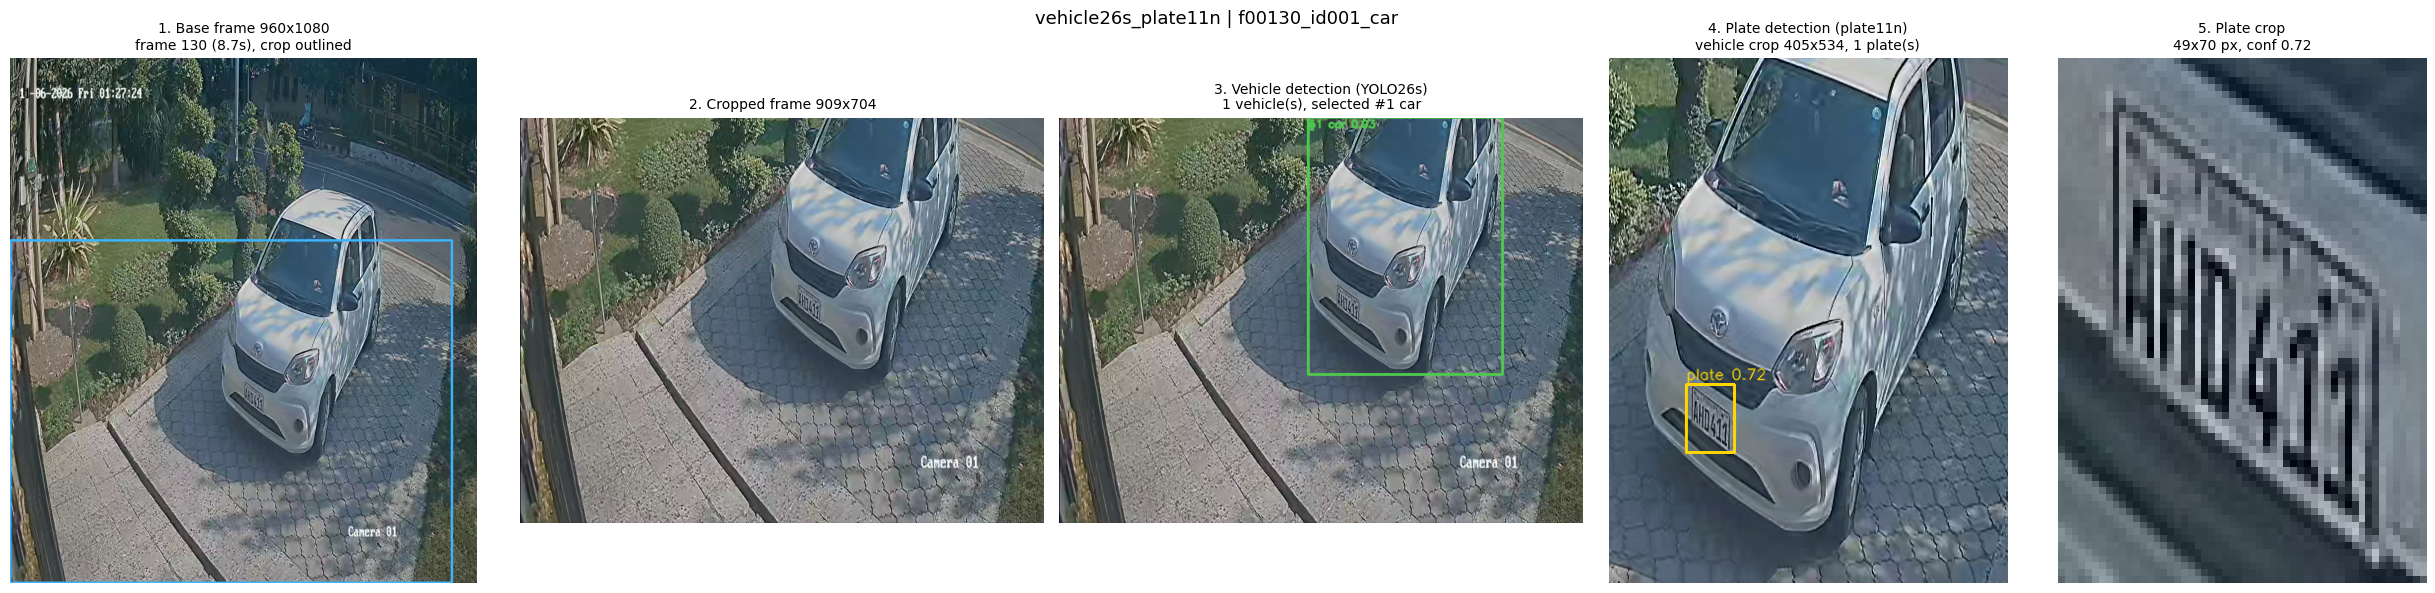

In [3]:
# Visualise one detection through the pipeline (from the saved stage-test outputs, nothing is re-run):
#   base frame -> cropped frame (config crop) -> vehicle detection on the crop -> plate detection on the vehicle crop
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

# ---------- Settings ----------
PIPELINE     = "vehicle26s_plate11n"     # or "vehicle26s_plate11s"
STEM         = None                      # e.g. "f00345_id012_car"; None = the most confident plate detection
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR      = PROJECT_ROOT / "data" / "outputs" / "plate_tests" / PIPELINE
SAVE_FIGURE  = True                      # saves to <pipeline>/figures/<stem>_pipeline.png

CROP_COLOR, VEHICLE_COLOR, SELECTED_COLOR, PLATE_COLOR = (255, 180, 60), (200, 200, 200), (80, 200, 80), (0, 215, 255)  # BGR

vehicles = json.loads((OUT_DIR / "vehicles.json").read_text())
plates   = json.loads((OUT_DIR / "plates.json").read_text())

# ---------- Pick the detection ----------
with_plate = [d for d in plates["detections"] if d["plates"]]
if STEM is None:
    assert with_plate, "No plate detections in this pipeline"
    rec = max(with_plate, key=lambda d: d["plates"][0]["conf"])
else:
    rec = next((d for d in plates["detections"] if d["stem"] == STEM), None)
    assert rec is not None, f"{STEM} not found in {PIPELINE}/plates.json"
veh = next(v for v in vehicles["detections"] if v["stem"] == rec["stem"])
frame_vehicles = [v for v in vehicles["detections"] if v["frame"] == rec["frame"]]

# ---------- 1. Base frame (frame numbers are 1-based) ----------
cap = cv2.VideoCapture(str(PROJECT_ROOT / vehicles["video"]))
cap.set(cv2.CAP_PROP_POS_FRAMES, rec["frame"] - 1)
ok, base = cap.read()
cap.release()
assert ok, f"Could not read frame {rec['frame']}"

CX1, CY1, CX2, CY2 = vehicles["settings"]["detect_area"]
base_vis = base.copy()
cv2.rectangle(base_vis, (CX1, CY1), (CX2 - 1, CY2 - 1), CROP_COLOR, 4)

# ---------- 2. Cropped frame ----------
crop = base[CY1:CY2, CX1:CX2].copy()

# ---------- 3. Vehicle detection on the crop ----------
veh_vis = crop.copy()
for v in frame_vehicles:
    x1, y1, x2, y2 = [int(c) for c in v["box_frame"]]
    x1, y1, x2, y2 = x1 - CX1, y1 - CY1, x2 - CX1, y2 - CY1
    sel = v["stem"] == rec["stem"]
    color = SELECTED_COLOR if sel else VEHICLE_COLOR
    cv2.rectangle(veh_vis, (x1, y1), (x2, y2), color, 3 if sel else 2)
    cv2.putText(veh_vis, f"#{v['track_id']} {v['class']} {v['conf']:.2f}", (x1, max(18, y1 - 6)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

# ---------- 4. Plate detection on the vehicle crop ----------
vcrop = cv2.imread(str(OUT_DIR / veh["file"]))
plate_vis = vcrop.copy()
for pl in rec["plates"]:
    x1, y1, x2, y2 = [int(c) for c in pl["box_vehicle_crop"]]
    cv2.rectangle(plate_vis, (x1, y1), (x2, y2), PLATE_COLOR, 2)
    cv2.putText(plate_vis, f"plate {pl['conf']:.2f}", (x1, max(14, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, PLATE_COLOR, 1, cv2.LINE_AA)

# ---------- 5. Plate crop ----------
plate_crop = cv2.imread(str(OUT_DIR / rec["plates"][0]["crop_file"])) if rec["plates"] else None

# ---------- Figure ----------
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
panels = [
    (base_vis,  f"1. Base frame {base.shape[1]}x{base.shape[0]}\nframe {rec['frame']} ({rec['time_s']:.1f}s), crop outlined"),
    (crop,      f"2. Cropped frame {crop.shape[1]}x{crop.shape[0]}"),
    (veh_vis,   f"3. Vehicle detection (YOLO26s)\n{len(frame_vehicles)} vehicle(s), selected #{rec['track_id']} {rec['vehicle_class']}"),
    (plate_vis, f"4. Plate detection ({PIPELINE.split('_')[-1]})\nvehicle crop {vcrop.shape[1]}x{vcrop.shape[0]}, "
                f"{len(rec['plates'])} plate(s)"),
]
if plate_crop is not None:
    p0 = rec["plates"][0]
    panels.append((plate_crop, f"5. Plate crop\n{p0['width_px']:.0f}x{p0['height_px']:.0f} px, conf {p0['conf']:.2f}"))

fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 6),
                         gridspec_kw={"width_ratios": [1, 1, 1, 0.8, 0.8][:len(panels)]})
for ax, (im, title) in zip(axes, panels):
    ax.imshow(rgb(im))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle(f"{PIPELINE} | {rec['stem']}", fontsize=13)
plt.tight_layout()
if SAVE_FIGURE:
    (OUT_DIR / "figures").mkdir(exist_ok=True)
    fig_path = OUT_DIR / "figures" / f"{rec['stem']}_pipeline.png"
    fig.savefig(fig_path, dpi=120, bbox_inches="tight")
    print(f"Saved {fig_path}")
plt.show()

## PaddleOCR setup #

Installs PaddlePaddle (the CPU build) and PaddleOCR 3.x, then prints the versions and runs Paddle's own check. **Restart the kernel after the first install.** The OCR model weights download the first time OCR runs.

In [1]:
%pip install -q paddlepaddle paddleocr
# PaddlePaddle (CPU build from PyPI) + PaddleOCR 3.x. The OCR model weights download on first use (to ~/.paddlex).
# Restart the kernel after the first install, then run this cell again to check the versions.
import os
os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "huggingface"   # download OCR models from Hugging Face (ModelScope fails here)   # skip the slow model-host check on import

import cv2
import torch  # Windows: torch must load before paddle, otherwise torch's DLLs fail (WinError 127, shm.dll)
import paddle
import paddleocr

print("paddlepaddle:", paddle.__version__)
print("paddleocr   :", paddleocr.__version__)
print("opencv      :", cv2.__version__)
paddle.utils.run_check()

Note: you may need to restart the kernel to use updated packages.


KeyboardInterrupt: 

## OCR on plate crops: vehicle → plate → OCR #

Runs PaddleOCR on the plate crops from the stage test (`PIPELINE`), then votes per vehicle for one final plate.

- **`OCR_MODE`:** `"rec"` runs recognition only (one line, fast). `"full"` adds text detection, for two-line plates.
- **Preprocessing:** small plates are upscaled to 96 px tall, then converted to grayscale and run through CLAHE (local contrast normalisation).
- **Clean-up:** text is upper-cased and only A-Z and 0-9 are kept, 4-10 characters. Set `PLATE_REGEX` to your local plate format to drop impossible readings.
- **Voting:** each reading votes for its text, weighted by OCR confidence × plate confidence. The top text becomes the vehicle's plate.

Outputs in `<pipeline>/ocr/`:
- `ocr.json`: every reading, linked by `stem`, plus the final plate per vehicle.
- `annotated/`: each plate crop with its reading underneath. Green means it passed clean-up; red means it was rejected.
- `best_per_track/id012_<PLATE>.jpg`: the best-read plate for each vehicle.

In [1]:
# PaddleOCR on the plate crops from the stage test (vehicle -> plate -> OCR).
# Reads <pipeline>/plates.json, runs OCR on each plate crop, then votes per vehicle track for one final plate.
# Outputs in <pipeline>/ocr/:
#   ocr.json                          every reading (linked by stem) + the final plate per track
#   annotated/<stem>_p0.jpg           plate crop (as sent to OCR) with the reading underneath
#   best_per_track/id012_<TEXT>.jpg   best-read plate per vehicle
import json
import os
import re
import shutil
import time
from collections import defaultdict
from pathlib import Path

os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "huggingface"   # download OCR models from Hugging Face (ModelScope fails here)
import cv2
import numpy as np
import torch  # Windows: torch must load before paddle, otherwise torch's DLLs fail (WinError 127, shm.dll)
import paddle  # noqa: F401  (imported here, at the top, so a broken paddle import fails clearly)
from paddleocr import PaddleOCR, TextRecognition

# ---------- Settings ----------
PIPELINE     = "vehicle26s_plate11n"       # or "vehicle26s_plate11s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR      = PROJECT_ROOT / "data" / "outputs" / "plate_tests" / PIPELINE
OCR_DIR      = OUT_DIR / "ocr"
OCR_MODELS_DIR = PROJECT_ROOT / "models" / "paddleocr"   # OCR model weights live here (copied from ~/.paddlex on first use)

OCR_MODE   = "rec"                       # "rec" = recognition only (one text line, fast)
                                         # "full" = text detection + recognition (handles two-line plates)
REC_MODEL  = "en_PP-OCRv5_mobile_rec"    # English/digits, loaded from models/paddleocr/; alternatives: "PP-OCRv5_mobile_rec", "PP-OCRv5_server_rec"
ONLY_TOP_PLATE = True                    # OCR only the most confident plate per vehicle crop (p0)
MIN_PLATE_CONF = 0.25                    # skip plate detections below this

# Preprocessing (applied to the plate crop before OCR)
PREPROCESS     = True
TARGET_HEIGHT  = 96                      # upscale small plates to this height (px); OCR struggles below ~30 px
USE_CLAHE      = True                    # local contrast normalisation (helps at night / in glare)

# Text clean-up + voting
KEEP_CHARS   = r"[^A-Z0-9]"              # removed after upper-casing (spaces, dashes, dots...)
MIN_CHARS    = 4                         # readings shorter than this are ignored
MAX_CHARS    = 10
PLATE_REGEX  = None                      # e.g. r"^[A-Z]{2,3}[0-9]{2,4}$" to only accept your local plate format
MIN_OCR_CONF = 0.5                       # readings below this don't vote

assert (OUT_DIR / "plates.json").exists(), f"Run the stage test for {PIPELINE} first"
plates = json.loads((OUT_DIR / "plates.json").read_text())

if OCR_DIR.exists():
    shutil.rmtree(OCR_DIR)
(OCR_DIR / "annotated").mkdir(parents=True)
(OCR_DIR / "best_per_track").mkdir()


# ---------- OCR model ----------
def local_model_dir(name):
    """models/paddleocr/<name>. If missing, PaddleOCR downloads it to ~/.paddlex once and it is copied here."""
    target = OCR_MODELS_DIR / name
    if not (target / "inference.yml").exists():
        TextRecognition(model_name=name)                    # downloads into ~/.paddlex/official_models
        cache = Path.home() / ".paddlex" / "official_models" / name
        shutil.copytree(cache, target, dirs_exist_ok=True)
        print(f"Copied {name} to {target}")
    return target


def load_ocr():
    rec_dir = local_model_dir(REC_MODEL)
    print(f"OCR model: {rec_dir}")
    if OCR_MODE == "rec":
        return TextRecognition(model_name=REC_MODEL, model_dir=str(rec_dir))
    return PaddleOCR(text_recognition_model_name=REC_MODEL, text_recognition_model_dir=str(rec_dir),
                     use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
                     enable_mkldnn=False)   # Paddle 3.3 oneDNN bug with the text detector on CPU


def as_dict(res):
    try:
        return dict(res)
    except Exception:
        return res.json.get("res", res.json)


def run_ocr(model, img):
    """-> (raw text, confidence). Multi-line results (full mode) are joined top to bottom."""
    res = as_dict(model.predict(img)[0])
    if OCR_MODE == "rec":
        return res.get("rec_text", ""), float(res.get("rec_score", 0.0))
    texts, scores = res.get("rec_texts", []), res.get("rec_scores", [])
    if not texts:
        return "", 0.0
    polys = res.get("rec_polys", res.get("dt_polys", []))
    order = np.argsort([np.mean(np.asarray(p)[:, 1]) for p in polys]) if len(polys) == len(texts) else range(len(texts))
    return " ".join(texts[i] for i in order), float(np.mean(scores))


def preprocess(img):
    if not PREPROCESS:
        return img
    h, w = img.shape[:2]
    if h < TARGET_HEIGHT:
        s = TARGET_HEIGHT / h
        img = cv2.resize(img, (int(w * s), TARGET_HEIGHT), interpolation=cv2.INTER_CUBIC)
    if USE_CLAHE:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(gray)
        img = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)       # OCR models expect 3 channels
    return img


def clean(text):
    t = re.sub(KEEP_CHARS, "", text.upper())
    if not (MIN_CHARS <= len(t) <= MAX_CHARS):
        return None
    if PLATE_REGEX and not re.match(PLATE_REGEX, t):
        return None
    return t


def annotate(img, raw, conf, cleaned):
    h, w = img.shape[:2]
    canvas = np.full((h + 34, max(w, 260), 3), 30, np.uint8)
    canvas[:h, :w] = img
    color = (80, 200, 80) if cleaned else (60, 60, 230)
    cv2.putText(canvas, f"{raw or '-'}  {conf:.2f}", (4, h + 24), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)
    return canvas


ocr = load_ocr()

# ---------- Run ----------
items = [(d, p) for d in plates["detections"] for p in d["plates"]
         if p["conf"] >= MIN_PLATE_CONF and (p["rank"] == 0 or not ONLY_TOP_PLATE)]
print(f"{PIPELINE} | OCR mode '{OCR_MODE}' | {len(items)} plate crops")
readings, t0 = [], time.time()
for i, (d, p) in enumerate(items, 1):
    img = cv2.imread(str(OUT_DIR / p["crop_file"]))
    if img is None or min(img.shape[:2]) < 4:
        continue
    prep = preprocess(img)
    ts = time.time()
    raw, conf = run_ocr(ocr, prep)
    ms = 1000 * (time.time() - ts)
    cleaned = clean(raw)
    name = Path(p["crop_file"]).name
    cv2.imwrite(str(OCR_DIR / "annotated" / name), annotate(prep, raw, conf, cleaned))
    readings.append({"stem": d["stem"], "plate_crop": p["crop_file"], "frame": d["frame"], "time_s": d["time_s"],
                     "track_id": d["track_id"], "plate_conf": p["conf"], "plate_width_px": p["width_px"],
                     "raw_text": raw, "ocr_conf": round(conf, 3), "text": cleaned, "ocr_ms": round(ms, 1)})
    if i % 50 == 0:
        print(f"  {i}/{len(items)}  {i / (time.time() - t0):.1f} crops/s")
elapsed = time.time() - t0

# ---------- Vote per track ----------
by_track = defaultdict(list)
for r in readings:
    by_track[r["track_id"]].append(r)

final = []
for tid, rs in sorted(by_track.items()):
    votes = defaultdict(float)
    for r in rs:
        if r["text"] and r["ocr_conf"] >= MIN_OCR_CONF:
            votes[r["text"]] += r["ocr_conf"] * r["plate_conf"]       # confidence-weighted vote
    if votes:
        plate = max(votes, key=votes.get)
        support = [r for r in rs if r["text"] == plate]
        best = max(support, key=lambda r: r["ocr_conf"])
        shutil.copy2(OUT_DIR / best["plate_crop"], OCR_DIR / "best_per_track" / f"id{tid:03d}_{plate}.jpg")
    else:
        plate, support, best = None, [], None
    final.append({
        "track_id": tid, "plate": plate,
        "readings": len(rs), "agreeing_readings": len(support),
        "agreement_pct": round(100 * len(support) / len(rs), 1) if rs else 0,
        "best_ocr_conf": best["ocr_conf"] if best else None,
        "best_stem": best["stem"] if best else None,
        "candidates": dict(sorted(((k, round(v, 3)) for k, v in votes.items()), key=lambda kv: -kv[1])[:5]),
    })

valid = [r for r in readings if r["text"]]
summary = {
    "pipeline": PIPELINE, "ocr_mode": OCR_MODE, "rec_model": REC_MODEL if OCR_MODE == "rec" else "PaddleOCR(lang=en)",
    "plate_crops": len(readings),
    "valid_readings": len(valid),
    "valid_pct": round(100 * len(valid) / max(len(readings), 1), 1),
    "mean_ocr_conf_valid": round(float(np.mean([r["ocr_conf"] for r in valid])), 3) if valid else None,
    "tracks": len(final),
    "tracks_with_plate": sum(f["plate"] is not None for f in final),
    "ocr_ms_per_crop": round(1000 * elapsed / max(len(readings), 1), 1),
}
(OCR_DIR / "ocr.json").write_text(json.dumps({
    "summary": summary,
    "settings": {"preprocess": PREPROCESS, "target_height": TARGET_HEIGHT, "clahe": USE_CLAHE,
                 "min_chars": MIN_CHARS, "max_chars": MAX_CHARS, "plate_regex": PLATE_REGEX,
                 "min_ocr_conf": MIN_OCR_CONF, "min_plate_conf": MIN_PLATE_CONF, "only_top_plate": ONLY_TOP_PLATE},
    "tracks": final, "readings": readings,
}, indent=2))

print(f"\nDone in {elapsed:.0f}s")
for k, v in summary.items():
    print(f"  {k:22s} {v}")
print("\nFinal plate per vehicle:")
for f in final:
    print(f"  #{f['track_id']:<4} {str(f['plate']):12s} {f['agreeing_readings']:3d}/{f['readings']:<3d} readings agree"
          f"  best conf {f['best_ocr_conf'] if f['best_ocr_conf'] is not None else '-'}  candidates {f['candidates']}")
print(f"\nOutput: {OCR_DIR}")

c:\Users\hamma\miniconda3\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


OCR model: c:\hammad's_everything\myProjects\VehicleTollingSystem\models\paddleocr\en_PP-OCRv5_mobile_rec
vehicle26s_plate11n | OCR mode 'rec' | 229 plate crops
  50/229  5.0 crops/s
  100/229  5.3 crops/s
  150/229  5.5 crops/s
  200/229  5.5 crops/s

Done in 42s
  pipeline               vehicle26s_plate11n
  ocr_mode               rec
  rec_model              en_PP-OCRv5_mobile_rec
  plate_crops            229
  valid_readings         4
  valid_pct              1.7
  mean_ocr_conf_valid    0.305
  tracks                 1
  tracks_with_plate      0
  ocr_ms_per_crop        181.7

Final plate per vehicle:
  #1    None           0/229 readings agree  best conf -  candidates {}

Output: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\plate_tests\vehicle26s_plate11n\ocr


## Frame 130 results #

Shows the saved results for one frame (`FRAME`): the vehicle crop with its plate box, the plate crop, and what OCR received with its reading. Frame 130 has the most confident plate detection (0.72); the plate reads **AHD 411** by eye, but recognition-only OCR returned "S" (0.26) because the plate is slanted.

f00130_id001_car | frame 130 (8.67s) | 1 plate(s)
  plate p0: conf 0.72, 49x70 px, box [78.6, 332.0, 127.7, 401.9]
  OCR (rec): raw 'S' conf 0.264 -> rejected


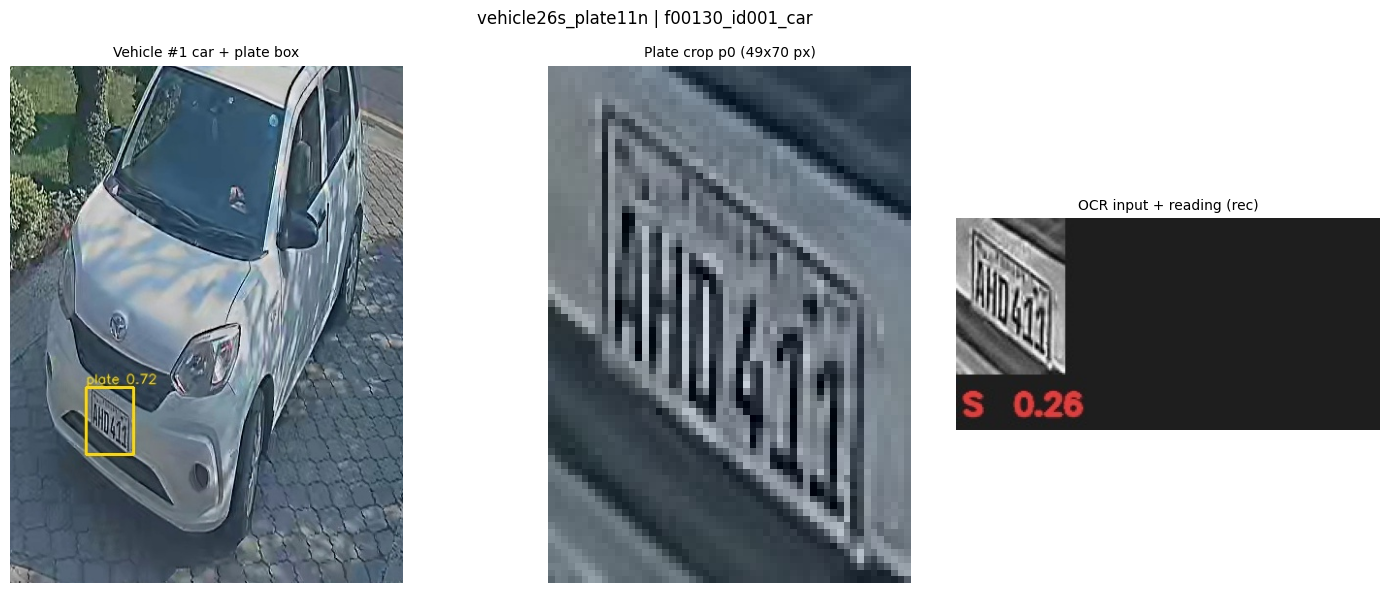

In [2]:
# Show every saved result for one frame: vehicle crop with plate box -> plate crop -> what OCR saw + its reading
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

PIPELINE     = "vehicle26s_plate11n"
FRAME        = 130
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR      = PROJECT_ROOT / "data" / "outputs" / "plate_tests" / PIPELINE

plates = json.loads((OUT_DIR / "plates.json").read_text())
ocr_j  = json.loads((OUT_DIR / "ocr" / "ocr.json").read_text()) if (OUT_DIR / "ocr" / "ocr.json").exists() else None
recs = [d for d in plates["detections"] if d["frame"] == FRAME]
assert recs, f"No vehicle detections saved for frame {FRAME}"

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
for rec in recs:
    panels = [(cv2.imread(str(OUT_DIR / (rec["annotated_file"] or rec["vehicle_file"]))),
               f"Vehicle #{rec['track_id']} {rec['vehicle_class']} + plate box")]
    print(f"{rec['stem']} | frame {rec['frame']} ({rec['time_s']}s) | {len(rec['plates'])} plate(s)")
    for pl in rec["plates"]:
        print(f"  plate p{pl['rank']}: conf {pl['conf']}, {pl['width_px']:.0f}x{pl['height_px']:.0f} px, box {pl['box_vehicle_crop']}")
        panels.append((cv2.imread(str(OUT_DIR / pl["crop_file"])),
                       f"Plate crop p{pl['rank']} ({pl['width_px']:.0f}x{pl['height_px']:.0f} px)"))
    if ocr_j:
        for r in (r for r in ocr_j["readings"] if r["stem"] == rec["stem"]):
            print(f"  OCR ({ocr_j['summary']['ocr_mode']}): raw '{r['raw_text']}' conf {r['ocr_conf']} -> "
                  f"{'kept: ' + r['text'] if r['text'] else 'rejected'}")
            ann = OUT_DIR / "ocr" / "annotated" / Path(r["plate_crop"]).name
            if ann.exists():
                panels.append((cv2.imread(str(ann)), f"OCR input + reading ({ocr_j['summary']['ocr_mode']})"))
    fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 6),
                             gridspec_kw={"width_ratios": [1.4] + [1] * (len(panels) - 1)})
    for ax, (im, title) in zip(axes if len(panels) > 1 else [axes], panels):
        ax.imshow(rgb(im))
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{PIPELINE} | {rec['stem']}", fontsize=12)
    plt.tight_layout()
    plt.show()

## OCR mode "full" on frame 130 #

Full mode runs PaddleOCR text **detection** first. It finds the slanted text line, straightens it, and then recognises it. The cell tries three inputs: the raw plate crop, the plate crop upscaled to 200 px tall, and the whole vehicle crop. The text detection model `PP-OCRv5_mobile_det` is stored in `models/paddleocr/`.

`enable_mkldnn=False` is required: Paddle 3.3's oneDNN CPU acceleration crashes on the text detector.

Creating model: ('PP-OCRv5_mobile_det', "c:\\hammad's_everything\\myProjects\\VehicleTollingSystem\\models\\paddleocr\\PP-OCRv5_mobile_det", None)
Creating model: ('en_PP-OCRv5_mobile_rec', "c:\\hammad's_everything\\myProjects\\VehicleTollingSystem\\models\\paddleocr\\en_PP-OCRv5_mobile_rec", None)


f00130_id001_car | full OCR (PP-OCRv5_mobile_det + en_PP-OCRv5_mobile_rec)
  plate crop (raw)       54x77  ->  no text found
  plate crop x2.6        140x200  ->  'ANIGIO' (0.36)
  vehicle crop           405x534  ->  'MN' (0.19)


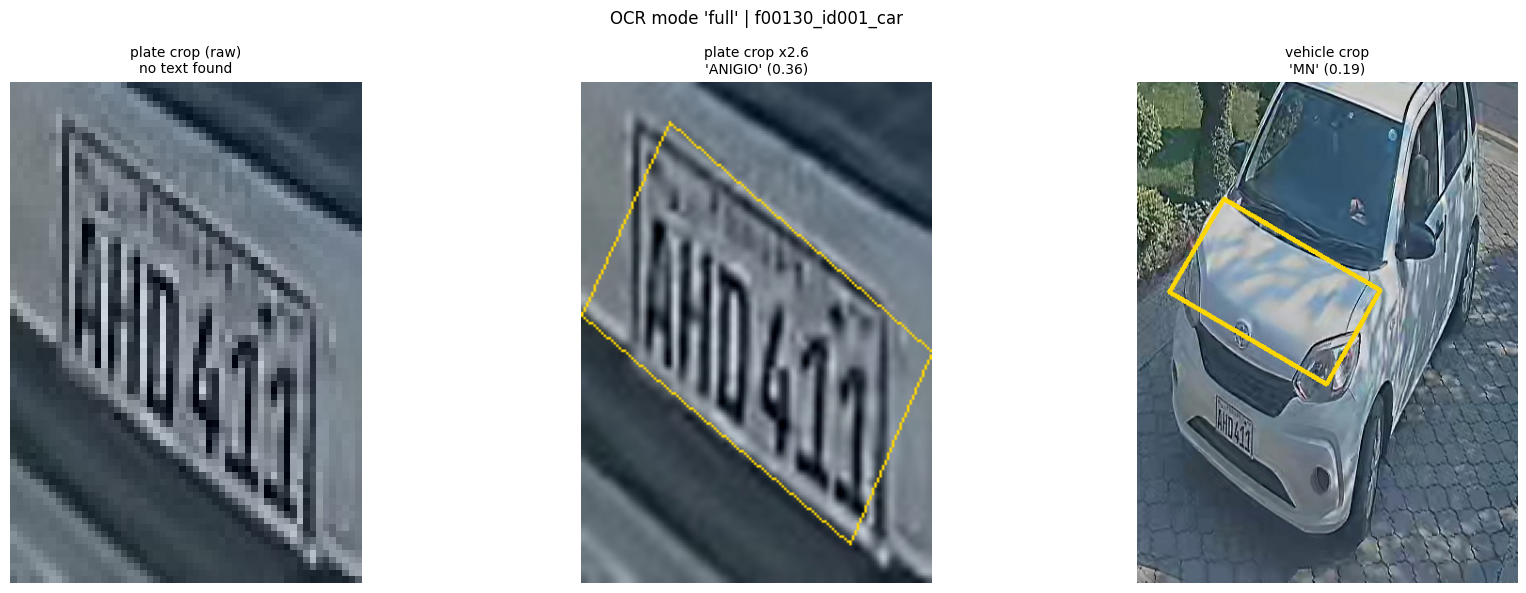

In [3]:
# OCR_MODE "full" on one frame: PaddleOCR text DETECTION finds the (slanted) text line, rectifies it, then recognises it.
# Tried on 3 inputs: the raw plate crop, the plate crop upscaled, and the whole vehicle crop.
import json
import os
import shutil
from pathlib import Path

os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "huggingface"
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch  # Windows: torch must load before paddle (WinError 127, shm.dll)
import paddle  # noqa: F401
from paddleocr import PaddleOCR, TextDetection, TextRecognition

PIPELINE     = "vehicle26s_plate11n"
FRAME        = 130
DET_MODEL    = "PP-OCRv5_mobile_det"       # text detection; "PP-OCRv5_server_det" is larger/more accurate
REC_MODEL    = "en_PP-OCRv5_mobile_rec"
UPSCALE_H    = 200                         # plate crop height for the "upscaled" input
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR      = PROJECT_ROOT / "data" / "outputs" / "plate_tests" / PIPELINE
OCR_MODELS_DIR = PROJECT_ROOT / "models" / "paddleocr"


def local_model_dir(name, loader):
    """models/paddleocr/<name>; downloaded once into ~/.paddlex and copied here if missing."""
    target = OCR_MODELS_DIR / name
    if not (target / "inference.yml").exists():
        loader(model_name=name)
        shutil.copytree(Path.home() / ".paddlex" / "official_models" / name, target, dirs_exist_ok=True)
        print(f"Copied {name} to {target}")
    return target


ocr = PaddleOCR(
    text_detection_model_name=DET_MODEL,   text_detection_model_dir=str(local_model_dir(DET_MODEL, TextDetection)),
    text_recognition_model_name=REC_MODEL, text_recognition_model_dir=str(local_model_dir(REC_MODEL, TextRecognition)),
    use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
    enable_mkldnn=False,   # Paddle 3.3 oneDNN bug with the text detector on CPU (ConvertPirAttribute2RuntimeAttribute)
)

# ---------- Inputs for this frame ----------
plates = json.loads((OUT_DIR / "plates.json").read_text())
rec = next(d for d in plates["detections"] if d["frame"] == FRAME and d["plates"])
plate_crop = cv2.imread(str(OUT_DIR / rec["plates"][0]["crop_file"]))
vehicle    = cv2.imread(str(OUT_DIR / rec["vehicle_file"]))
s = UPSCALE_H / plate_crop.shape[0]
inputs = {
    "plate crop (raw)":      plate_crop,
    f"plate crop x{s:.1f}":  cv2.resize(plate_crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC),
    "vehicle crop":          vehicle,
}


def as_dict(res):
    try:
        return dict(res)
    except Exception:
        return res.json.get("res", res.json)


# ---------- Run + show ----------
fig, axes = plt.subplots(1, len(inputs), figsize=(6 * len(inputs), 6))
print(f"{rec['stem']} | full OCR ({DET_MODEL} + {REC_MODEL})")
for ax, (name, img) in zip(axes, inputs.items()):
    r = as_dict(ocr.predict(img)[0])
    texts, scores, polys = r.get("rec_texts", []), r.get("rec_scores", []), r.get("rec_polys", [])
    vis = img.copy()
    lw = max(1, round(img.shape[0] / 150))
    for poly, t, sc in zip(polys, texts, scores):
        pts = np.asarray(poly, np.int32)
        cv2.polylines(vis, [pts], True, (0, 215, 255), lw)
    found = ", ".join(f"'{t}' ({sc:.2f})" for t, sc in zip(texts, scores)) or "no text found"
    print(f"  {name:22s} {img.shape[1]}x{img.shape[0]}  ->  {found}")
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n{found}", fontsize=10)
    ax.axis("off")
fig.suptitle(f"OCR mode 'full' | {rec['stem']}", fontsize=12)
plt.tight_layout()
plt.show()

## OCR step by step on frame 130: rec vs full vs deskew #

Shows every step of three ways to read the same plate crop:

- **A) `rec` mode:** the crop is upscaled and contrast-boosted (CLAHE), then sent as-is. The recogniser reads one horizontal line, but the plate is diagonal, so it reads 'S'.
- **B) `full` mode:** the text detector finds the line. PaddleOCR cuts the line out and **rotates** it flat, but the plate is sheared, so the letters stay slanted and it reads 'ANIGIO'.
- **C) deskew:** the slant angle is measured from the plate's border and edge lines. A **vertical shear** (y' = y − tan θ · x) levels the text line and keeps the letters upright. The main character band is then cut out and recognised.

On frame 130, C reads **AHD4101 (0.81)**: the first five characters are right and "11" is read as "101". A and B give 'S' / 'Si' (about 0.25) and 'ANIGIO' (0.36). Voting across all of the car's frames should fix the single misread.

Creating model: ('PP-OCRv5_mobile_det', "c:\\hammad's_everything\\myProjects\\VehicleTollingSystem\\models\\paddleocr\\PP-OCRv5_mobile_det", None)
Creating model: ('en_PP-OCRv5_mobile_rec', "c:\\hammad's_everything\\myProjects\\VehicleTollingSystem\\models\\paddleocr\\en_PP-OCRv5_mobile_rec", None)


f00130_id001_car | plate crop 54x77 px, plate conf 0.72



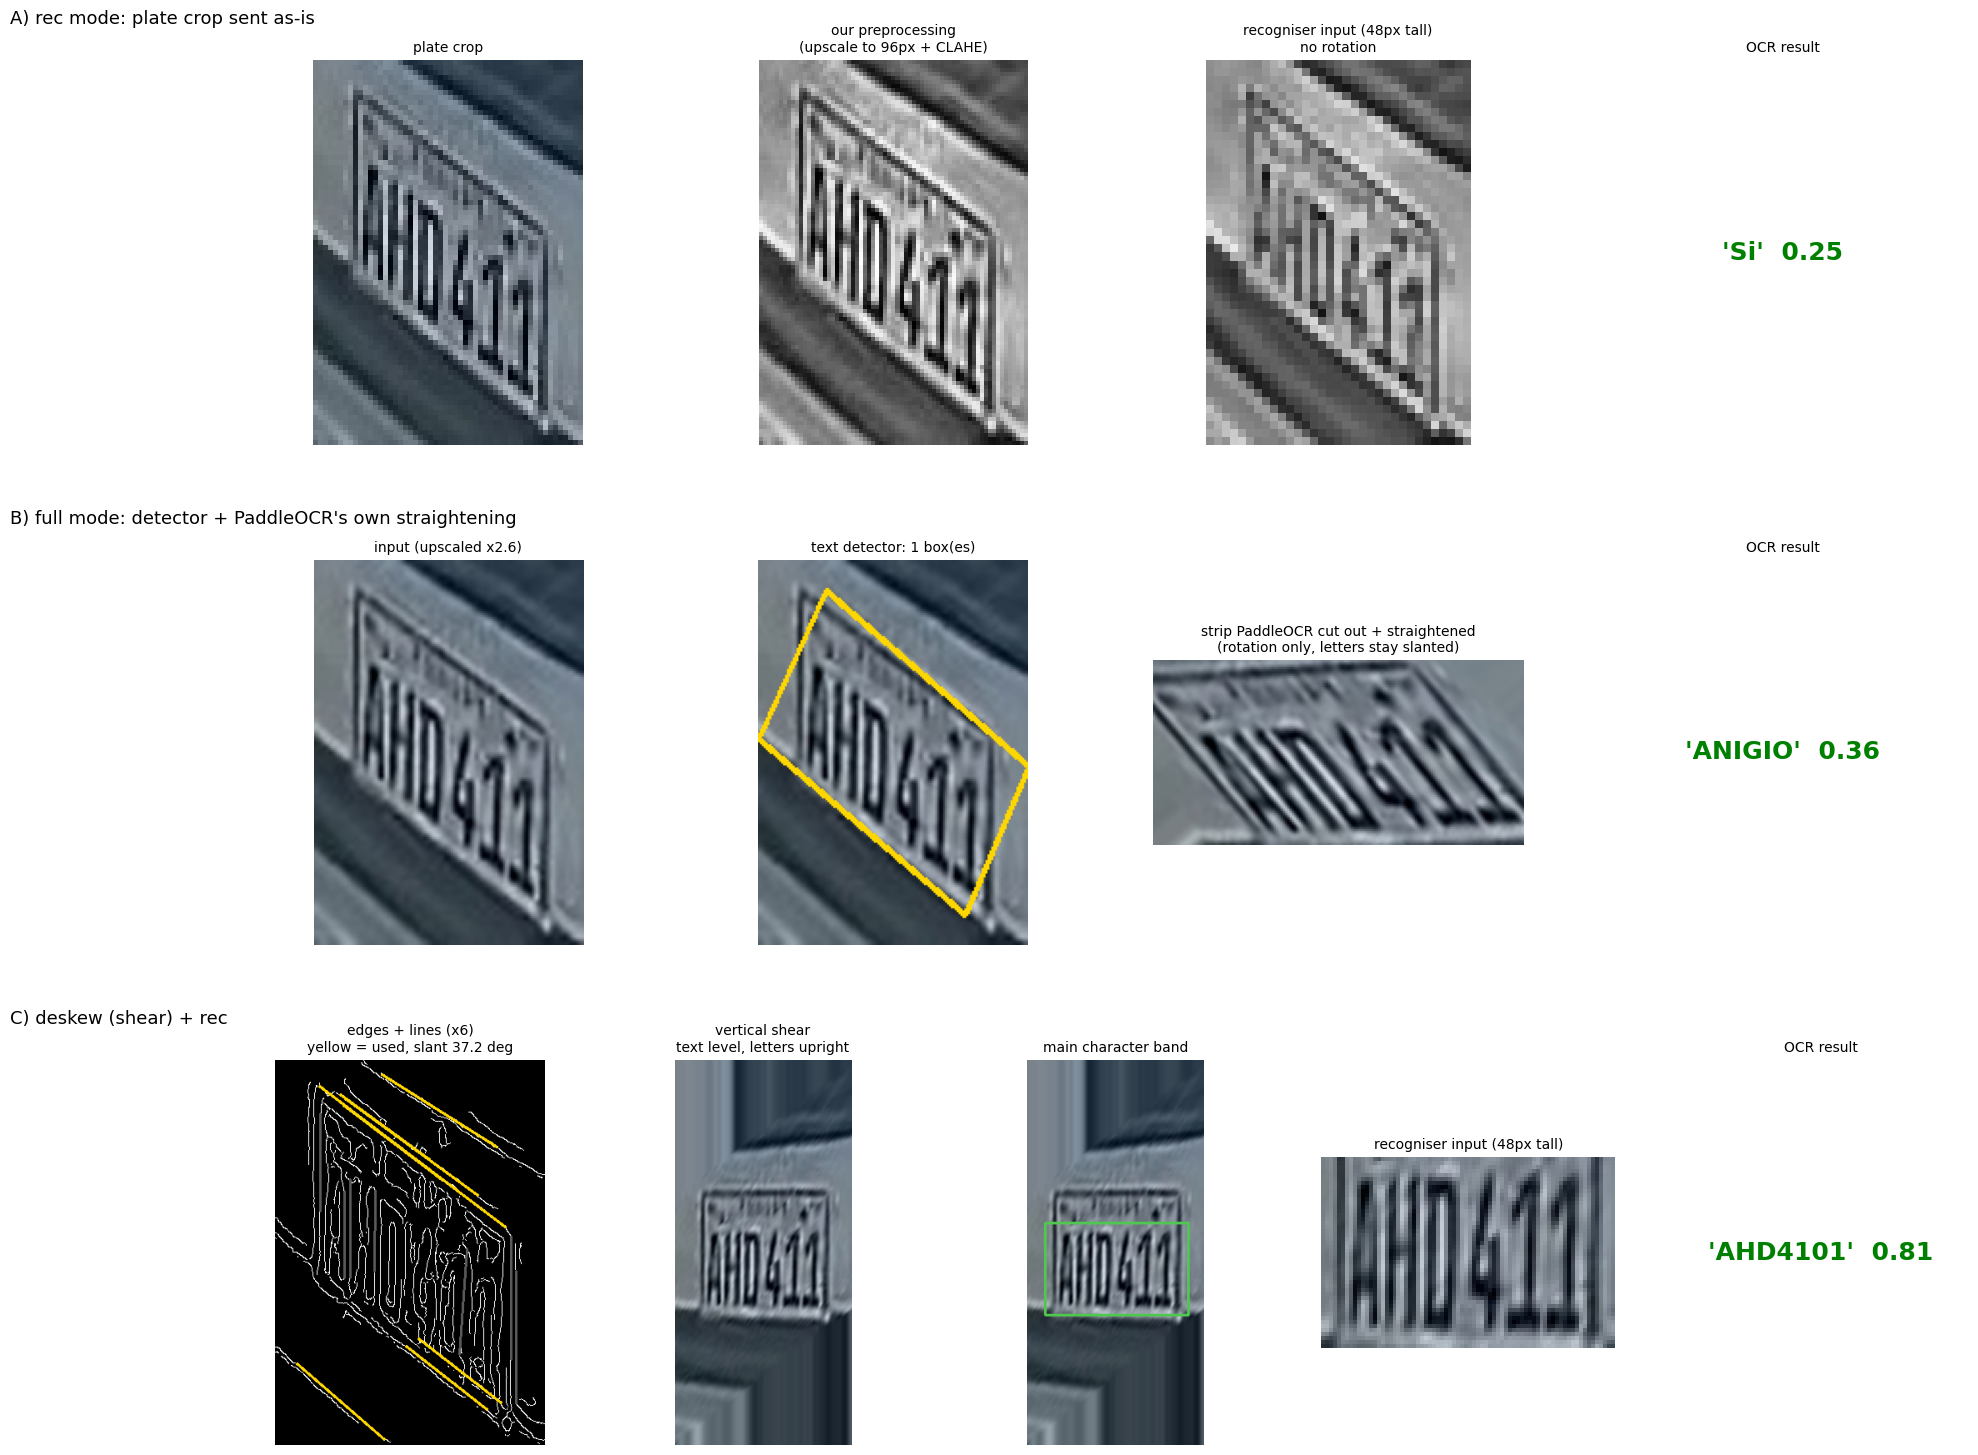

A) rec mode : 'Si' (0.25)
B) full mode: 'ANIGIO' (0.36)
C) deskew   : 'AHD4101' (0.81)   slant 37.2 deg


In [4]:
# Every step, for one frame, of three ways to OCR the plate crop:
#   A) "rec"  : plate crop -> our preprocessing -> recogniser (reads ONE horizontal line, no rotation)
#   B) "full" : upscaled crop -> text detector box -> PaddleOCR cuts out + straightens the box (rotation only) -> recogniser
#   C) deskew : find the plate's slant angle -> vertical shear so the text line is level and letters stay upright
#               -> cut out the main text band -> recogniser
import json
import os
from pathlib import Path

os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "huggingface"
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch  # Windows: torch must load before paddle (WinError 127, shm.dll)
import paddle  # noqa: F401
from paddleocr import PaddleOCR, TextRecognition
from paddlex.inference.pipelines.components.common.crop_image_regions import CropByPolys

PIPELINE     = "vehicle26s_plate11n"
FRAME        = 130
DET_MODEL    = "PP-OCRv5_mobile_det"
REC_MODEL    = "en_PP-OCRv5_mobile_rec"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR      = PROJECT_ROOT / "data" / "outputs" / "plate_tests" / PIPELINE
OCR_MODELS_DIR = PROJECT_ROOT / "models" / "paddleocr"

# A) same preprocessing as the main OCR cell
TARGET_HEIGHT, USE_CLAHE = 96, True
# B) upscale before full mode
FULL_UPSCALE_H = 200
# C) deskew
DESKEW_UP      = 6          # work on the crop upscaled this much
MIN_SLANT_DEG  = 8          # lines flatter than this are ignored when measuring the slant (|angle| in degrees)
MAX_SLANT_DEG  = 75         # ...and steeper than this (those are the plate's near-vertical sides)
BAND_ROW_FRAC  = 0.45       # rows with >= this fraction of the peak vertical-edge energy = main character band
BAND_COL_FRAC  = 0.30

for name in (DET_MODEL, REC_MODEL):
    assert (OCR_MODELS_DIR / name / "inference.yml").exists(), f"{name} missing in {OCR_MODELS_DIR}: run the full-mode cell first"
rec_model = TextRecognition(model_name=REC_MODEL, model_dir=str(OCR_MODELS_DIR / REC_MODEL))
full_ocr = PaddleOCR(text_detection_model_name=DET_MODEL, text_detection_model_dir=str(OCR_MODELS_DIR / DET_MODEL),
                     text_recognition_model_name=REC_MODEL, text_recognition_model_dir=str(OCR_MODELS_DIR / REC_MODEL),
                     use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
                     enable_mkldnn=False)


def as_dict(res):
    try:
        return dict(res)
    except Exception:
        return res.json.get("res", res.json)


def read_line(img):
    r = as_dict(rec_model.predict(img)[0])
    return r.get("rec_text", ""), float(r.get("rec_score", 0.0))


def rec_view(img, h=48):
    """Roughly what the recogniser sees: the image resized to 48 px tall."""
    return cv2.resize(img, (max(1, int(img.shape[1] * h / img.shape[0])), h), interpolation=cv2.INTER_AREA)


def to3(g):
    return cv2.cvtColor(g, cv2.COLOR_GRAY2BGR) if g.ndim == 2 else g


# ---------- Input ----------
plates = json.loads((OUT_DIR / "plates.json").read_text())
rec = next(d for d in plates["detections"] if d["frame"] == FRAME and d["plates"])
plate = cv2.imread(str(OUT_DIR / rec["plates"][0]["crop_file"]))
print(f"{rec['stem']} | plate crop {plate.shape[1]}x{plate.shape[0]} px, plate conf {rec['plates'][0]['conf']}\n")

# ---------- A) rec mode ----------
a_pre = plate
if plate.shape[0] < TARGET_HEIGHT:
    s = TARGET_HEIGHT / plate.shape[0]
    a_pre = cv2.resize(plate, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
if USE_CLAHE:
    a_pre = to3(cv2.createCLAHE(2.0, (4, 4)).apply(cv2.cvtColor(a_pre, cv2.COLOR_BGR2GRAY)))
a_text, a_conf = read_line(a_pre)
row_a = [(plate, "plate crop"), (a_pre, f"our preprocessing\n(upscale to {TARGET_HEIGHT}px + CLAHE)"),
         (rec_view(a_pre), "recogniser input (48px tall)\nno rotation"), (None, f"'{a_text}'  {a_conf:.2f}")]

# ---------- B) full mode ----------
s = FULL_UPSCALE_H / plate.shape[0]
b_in = cv2.resize(plate, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
b_res = as_dict(full_ocr.predict(b_in)[0])
b_polys = b_res.get("dt_polys", b_res.get("rec_polys", []))
b_vis = b_in.copy()
for p in b_polys:
    cv2.polylines(b_vis, [np.asarray(p, np.int32)], True, (0, 215, 255), 2)
b_strips = CropByPolys(det_box_type="quad")(b_in, b_polys) if len(b_polys) else []
b_text = " ".join(b_res.get("rec_texts", [])) or "no text"
b_conf = float(np.mean(b_res["rec_scores"])) if b_res.get("rec_scores") else 0.0
row_b = [(b_in, f"input (upscaled x{s:.1f})"), (b_vis, f"text detector: {len(b_polys)} box(es)")]
row_b += [(st, f"strip PaddleOCR cut out + straightened\n(rotation only, letters stay slanted)") for st in b_strips[:2]]
row_b += [(None, f"'{b_text}'  {b_conf:.2f}")]

# ---------- C) deskew (vertical shear) ----------
big = cv2.resize(plate, None, fx=DESKEW_UP, fy=DESKEW_UP, interpolation=cv2.INTER_CUBIC)
gray = cv2.createCLAHE(2.0, (4, 4)).apply(cv2.cvtColor(big, cv2.COLOR_BGR2GRAY))
edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 40, 120)
H, W = gray.shape
lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 40, minLineLength=int(0.3 * min(H, W)), maxLineGap=10)
c_lines = to3(edges)
angs, wts = [], []
for x1, y1, x2, y2 in (lines.reshape(-1, 4) if lines is not None else []):
    a = (np.degrees(np.arctan2(y2 - y1, x2 - x1)) + 90) % 180 - 90
    used = MIN_SLANT_DEG < abs(a) < MAX_SLANT_DEG
    if used:
        angs.append(a)
        wts.append(np.hypot(x2 - x1, y2 - y1))
    cv2.line(c_lines, (x1, y1), (x2, y2), (0, 215, 255) if used else (90, 90, 90), 2)
if angs:                                   # length-weighted median of the slanted lines
    o = np.argsort(angs)
    cum = np.cumsum(np.array(wts)[o])
    theta = float(np.array(angs)[o][np.searchsorted(cum, cum[-1] / 2)])
else:
    theta = 0.0
t = np.tan(np.radians(theta))
M = np.float32([[1, 0, 0], [-t, 1, max(0.0, t * W)]])        # y' = y - tan(theta) * x  (x unchanged -> letters stay upright)
sheared = cv2.warpAffine(big, M, (W, int(H + abs(t) * W)), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

# main character band = rows/cols with strong vertical edges (character strokes)
sx = np.abs(cv2.Sobel(cv2.cvtColor(sheared, cv2.COLOR_BGR2GRAY), cv2.CV_32F, 1, 0, ksize=3))
rows = cv2.GaussianBlur(sx.mean(1).reshape(-1, 1), (1, 31), 0).ravel()
pk = int(rows.argmax())
r0 = r1 = pk
while r0 > 0 and rows[r0 - 1] > BAND_ROW_FRAC * rows[pk]:
    r0 -= 1
while r1 < len(rows) - 1 and rows[r1 + 1] > BAND_ROW_FRAC * rows[pk]:
    r1 += 1
cols = cv2.GaussianBlur(sx[r0:r1 + 1].mean(0).reshape(1, -1), (31, 1), 0).ravel()
cc = np.where(cols > BAND_COL_FRAC * cols.max())[0]
c0, c1 = int(cc[0]), int(cc[-1])
ph, pw = int(0.12 * (r1 - r0)), int(0.04 * (c1 - c0))
by0, by1, bx0, bx1 = max(0, r0 - ph), r1 + ph, max(0, c0 - pw), c1 + pw
band = sheared[by0:by1, bx0:bx1]
c_band_vis = sheared.copy()
cv2.rectangle(c_band_vis, (bx0, by0), (bx1, by1), (80, 200, 80), 3)
c_text, c_conf = read_line(band)
row_c = [(c_lines, f"edges + lines (x{DESKEW_UP})\nyellow = used, slant {theta:.1f} deg"),
         (sheared, "vertical shear\ntext level, letters upright"),
         (c_band_vis, "main character band"),
         (rec_view(band), "recogniser input (48px tall)"),
         (None, f"'{c_text}'  {c_conf:.2f}")]

# ---------- Display ----------
rows_all = [("A) rec mode: plate crop sent as-is", row_a), ("B) full mode: detector + PaddleOCR's own straightening", row_b),
            ("C) deskew (shear) + rec", row_c)]
fig = plt.figure(figsize=(22, 15))
for sub, (title, panels) in zip(fig.subfigures(len(rows_all), 1), rows_all):
    axes = np.atleast_1d(sub.subplots(1, len(panels)))
    for ax, (im, cap) in zip(axes, panels):
        ax.axis("off")
        if im is None:
            ax.text(0.5, 0.5, cap, ha="center", va="center", fontsize=18, fontweight="bold",
                    color="green" if cap.split("'")[1] else "red")
            ax.set_title("OCR result", fontsize=10)
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
            ax.set_title(cap, fontsize=10)
    sub.suptitle(title, fontsize=13, x=0.01, ha="left")
plt.show()

print(f"A) rec mode : '{a_text}' ({a_conf:.2f})")
print(f"B) full mode: '{b_text}' ({b_conf:.2f})")
print(f"C) deskew   : '{c_text}' ({c_conf:.2f})   slant {theta:.1f} deg")